# Kenya Watch: Machine Learning Component
### Category classification of corruption reports

**Project:** A Machine Learning-Based Web Platform for the Anonymous Reporting, Referral and Tracking of Corruption Cases in Kenya
**Student:** Nyangabi Benvictor Mwangi (155499), BBIT 4C, Strathmore University
**Supervisor:** Ms. Zainabu Muti

---

## About this notebook

This notebook reproduces the machine learning pipeline from the project repository (`ml/src/`) so that the whole workflow can be read and re-run in one place. It is arranged in five parts: the problem (Section 1), the dataset and its preparation (Section 2), the choice of model and the validation design (Section 3), the evaluation (Section 4) and the deployment in the live system (Section 5).

**To run it:** choose `Runtime > Run all`. Nothing needs to be uploaded; the dataset is included in the notebook.

## Scope of the results

The data used here is a synthetic corpus of fictional reports that I wrote for the project, not real citizen submissions. No lawful, labelled source of real corruption reports was available. This affects how the results should be read:

- The scores in Section 4 describe performance on this synthetic corpus only, not accuracy on real Kenyan reports.
- The live system (https://kenyawatch-zblk.onrender.com) uses a model trained by the same pipeline. It is exported to a fingerprinted JSON file and scored inside the Node.js server, shown to a reviewer only after their own category assessment, and labelled experimental. Urgency is still set by keyword rules.
- The model gives no calibrated probability, so its scores are never shown as confidence values.
- Training on real reports would first need the approval and data-handling steps described in `ml/README.md`.

---
# 1. Introduction and Problem Definition

## 1.1 The problem

Corruption in Kenya is widespread and rarely reported. The Ethics and Anti-Corruption Commission's 2025 survey found that 98.6% of people who paid a bribe did not report it, and its 2024 survey found that people stayed silent mainly because they feared retaliation and doubted that reporting would change anything. Three problems stand out:

1. **Fear of being identified.** Reporting can expose the person who reports.
2. **No feedback.** Reports seem to disappear, so people stop trusting the process.
3. **Slow sorting.** Reviewers must read every report before they can decide where it should go.

Kenya Watch handles the first problem by never collecting the identity of anonymous reporters, and the second by giving each reporter a tracking reference and a secret access key, so they can follow what the responsible institution did. This notebook deals with the third problem, sorting reports by category.

## 1.2 Where machine learning fits

The platform uses a text classifier to suggest one of nine categories (eight types of corruption and `Other`) for each report. The suggestion only assists the reviewer:

- it is shown only after the reviewer has recorded their own category, so it cannot anchor their judgement;
- it never sees the reporter's identity, which is not collected for anonymous reports;
- labels for any future training on real data come from two reviewers labelling independently, not from the category the reporter chose.

## 1.3 Why it is worth doing

Keyword rules alone miss most reports, because people describe what happened ("he asked for something small before signing my permit") rather than naming the offence. A learned model that reads the whole narrative can give reviewers a useful starting point, and because each referral records the suggestion next to the reviewer's decision, its usefulness can be measured on real cases.

---
# 2. Dataset and Preprocessing

## 2.1 Dataset description

| Property | Value |
|---|---|
| Source | Synthetic corpus written for the project (`ml/src/generate_synthetic_dataset.py`) |
| Size | 540 rows: 9 categories x 15 incidents x 4 versions |
| Versions of each incident | 2 in English and 2 in Kiswahili |
| Labels | Eight corruption categories based on the Anti-Corruption and Economic Crimes Act, plus `Other` |
| Incident grouping | All versions of one incident share a `group_id` and always stay in the same fold |
| Real personal data | None |

**Columns:** `text, label, group_id, language, county`

- `text` is the report narrative and the only input to the model.
- `label` is the category to be predicted.
- `group_id` identifies the incident; it is used to split the data without leakage (Section 3.2).
- `language` and `county` are used only to compare results between groups, never as features.

Real reports cannot be used without institutional approval, de-identification and reviewed labels. The synthetic corpus lets the pipeline itself (grouping, nested validation and the metrics) be built and checked before any sensitive data is involved.

## 2.2 Loading the data

The corpus is included below as a CSV string so that the notebook runs without uploading files. It is identical to `ml/data/synthetic/kenya_watch_synthetic_seed.csv` in the repository.

In [1]:
%pip -q install "scikit-learn>=1.5,<2" "joblib>=1.4,<2" pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import io, csv, json, statistics
from collections import Counter
from pathlib import Path
import pandas as pd

CATEGORIES = (
    "Bribery", "Embezzlement", "Procurement Fraud", "Abuse of Office",
    "Nepotism/Favoritism", "Extortion", "Fraud/Forgery of Documents",
    "Conflict of Interest", "Other",
)

CSV_DATA = 'text,label,group_id,language,county\nA licensing officer allegedly asked for an unofficial payment before approving a complete small-business permit application.,Bribery,synthetic-bribery-01,English,Nairobi\nThe report states that a licensing officer allegedly asked for an unofficial payment before approving a complete small-business permit application.,Bribery,synthetic-bribery-01,English,Nairobi\nAfisa wa leseni anadaiwa kuomba malipo yasiyo rasmi kabla ya kuidhinisha ombi kamili la kibali cha biashara ndogo.,Bribery,synthetic-bribery-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, afisa wa leseni anadaiwa kuomba malipo yasiyo rasmi kabla ya kuidhinisha ombi kamili la kibali cha biashara ndogo.",Bribery,synthetic-bribery-01,Kiswahili,Nairobi\nA resident says a public clerk requested cash to move a land-record search ahead of other applications.,Bribery,synthetic-bribery-02,English,Mombasa\nThe report states that a resident says a public clerk requested cash to move a land-record search ahead of other applications.,Bribery,synthetic-bribery-02,English,Mombasa\nMkazi anasema karani wa umma aliomba pesa ili kuharakisha upekuzi wa rekodi ya ardhi kuliko maombi mengine.,Bribery,synthetic-bribery-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, mkazi anasema karani wa umma aliomba pesa ili kuharakisha upekuzi wa rekodi ya ardhi kuliko maombi mengine.",Bribery,synthetic-bribery-02,Kiswahili,Mombasa\nA county employee allegedly offered to speed up inspection clearance in exchange for a personal payment.,Bribery,synthetic-bribery-03,English,Kisumu\nThe report states that a county employee allegedly offered to speed up inspection clearance in exchange for a personal payment.,Bribery,synthetic-bribery-03,English,Kisumu\nMfanyakazi wa kaunti anadaiwa kutoa ahadi ya kuharakisha kibali cha ukaguzi badala ya malipo binafsi.,Bribery,synthetic-bribery-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, mfanyakazi wa kaunti anadaiwa kutoa ahadi ya kuharakisha kibali cha ukaguzi badala ya malipo binafsi.",Bribery,synthetic-bribery-03,Kiswahili,Kisumu\nA public health inspector allegedly requested a gift before issuing a routine food-premises certificate.,Bribery,synthetic-bribery-04,English,Nakuru\nThe report states that a public health inspector allegedly requested a gift before issuing a routine food-premises certificate.,Bribery,synthetic-bribery-04,English,Nakuru\nMkaguzi wa afya ya umma anadaiwa kuomba zawadi kabla ya kutoa cheti cha kawaida cha eneo la chakula.,Bribery,synthetic-bribery-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, mkaguzi wa afya ya umma anadaiwa kuomba zawadi kabla ya kutoa cheti cha kawaida cha eneo la chakula.",Bribery,synthetic-bribery-04,Kiswahili,Nakuru\nA service applicant reports that an official asked for money to release a document that was already approved.,Bribery,synthetic-bribery-05,English,Turkana\nThe report states that a service applicant reports that an official asked for money to release a document that was already approved.,Bribery,synthetic-bribery-05,English,Turkana\nMwombaji wa huduma anaripoti kuwa afisa aliomba pesa ili kutoa hati ambayo tayari ilikuwa imeidhinishwa.,Bribery,synthetic-bribery-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mwombaji wa huduma anaripoti kuwa afisa aliomba pesa ili kutoa hati ambayo tayari ilikuwa imeidhinishwa.",Bribery,synthetic-bribery-05,Kiswahili,Turkana\nA public employee allegedly asked a supplier for a personal benefit in return for processing an invoice promptly.,Bribery,synthetic-bribery-06,English,Garissa\nThe report states that a public employee allegedly asked a supplier for a personal benefit in return for processing an invoice promptly.,Bribery,synthetic-bribery-06,English,Garissa\nMfanyakazi wa umma anadaiwa kuomba manufaa binafsi kutoka kwa msambazaji ili kushughulikia ankara haraka.,Bribery,synthetic-bribery-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, mfanyakazi wa umma anadaiwa kuomba manufaa binafsi kutoka kwa msambazaji ili kushughulikia ankara haraka.",Bribery,synthetic-bribery-06,Kiswahili,Garissa\nA resident alleges that an unofficial fee was requested to obtain a place in a public-service queue.,Bribery,synthetic-bribery-07,English,Kilifi\nThe report states that a resident alleges that an unofficial fee was requested to obtain a place in a public-service queue.,Bribery,synthetic-bribery-07,English,Kilifi\nMkazi anadai kuwa ada isiyo rasmi iliombwa ili kupata nafasi kwenye foleni ya huduma ya umma.,Bribery,synthetic-bribery-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, mkazi anadai kuwa ada isiyo rasmi iliombwa ili kupata nafasi kwenye foleni ya huduma ya umma.",Bribery,synthetic-bribery-07,Kiswahili,Kilifi\nAn officer allegedly promised to omit a routine penalty after receiving a private payment.,Bribery,synthetic-bribery-08,English,Bungoma\nThe report states that an officer allegedly promised to omit a routine penalty after receiving a private payment.,Bribery,synthetic-bribery-08,English,Bungoma\nAfisa anadaiwa kuahidi kuondoa adhabu ya kawaida baada ya kupokea malipo ya faragha.,Bribery,synthetic-bribery-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, afisa anadaiwa kuahidi kuondoa adhabu ya kawaida baada ya kupokea malipo ya faragha.",Bribery,synthetic-bribery-08,Kiswahili,Bungoma\nA contractor says a public employee requested a personal commission for certifying completed work.,Bribery,synthetic-bribery-09,English,Meru\nThe report states that a contractor says a public employee requested a personal commission for certifying completed work.,Bribery,synthetic-bribery-09,English,Meru\nMkandarasi anasema mfanyakazi wa umma aliomba kamisheni binafsi ili kuthibitisha kazi iliyokamilika.,Bribery,synthetic-bribery-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, mkandarasi anasema mfanyakazi wa umma aliomba kamisheni binafsi ili kuthibitisha kazi iliyokamilika.",Bribery,synthetic-bribery-09,Kiswahili,Meru\nA trader reports being asked for an unofficial payment before a market-stall allocation was processed.,Bribery,synthetic-bribery-10,English,Kitui\nThe report states that a trader reports being asked for an unofficial payment before a market-stall allocation was processed.,Bribery,synthetic-bribery-10,English,Kitui\nMfanyabiashara anaripoti kuombwa malipo yasiyo rasmi kabla ya kushughulikiwa kwa mgao wa kibanda sokoni.,Bribery,synthetic-bribery-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, mfanyabiashara anaripoti kuombwa malipo yasiyo rasmi kabla ya kushughulikiwa kwa mgao wa kibanda sokoni.",Bribery,synthetic-bribery-10,Kiswahili,Kitui\nA public clerk allegedly requested money to issue a routine copy of a record already held by the office.,Bribery,synthetic-bribery-11,English,Nairobi\nThe report states that a public clerk allegedly requested money to issue a routine copy of a record already held by the office.,Bribery,synthetic-bribery-11,English,Nairobi\nKarani wa umma anadaiwa kuomba pesa ili kutoa nakala ya kawaida ya rekodi ambayo ofisi tayari inayo.,Bribery,synthetic-bribery-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, karani wa umma anadaiwa kuomba pesa ili kutoa nakala ya kawaida ya rekodi ambayo ofisi tayari inayo.",Bribery,synthetic-bribery-11,Kiswahili,Nairobi\nA supplier reports an official asked for a personal reward before confirming delivery of standard materials.,Bribery,synthetic-bribery-12,English,Mombasa\nThe report states that a supplier reports an official asked for a personal reward before confirming delivery of standard materials.,Bribery,synthetic-bribery-12,English,Mombasa\nMsambazaji anaripoti kuwa afisa aliomba zawadi binafsi kabla ya kuthibitisha uwasilishaji wa vifaa vya kawaida.,Bribery,synthetic-bribery-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, msambazaji anaripoti kuwa afisa aliomba zawadi binafsi kabla ya kuthibitisha uwasilishaji wa vifaa vya kawaida.",Bribery,synthetic-bribery-12,Kiswahili,Mombasa\nA resident says a public officer requested a private payment to schedule an ordinary inspection.,Bribery,synthetic-bribery-13,English,Kisumu\nThe report states that a resident says a public officer requested a private payment to schedule an ordinary inspection.,Bribery,synthetic-bribery-13,English,Kisumu\nMkazi anasema afisa wa umma aliomba malipo ya faragha ili kupanga ukaguzi wa kawaida.,Bribery,synthetic-bribery-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, mkazi anasema afisa wa umma aliomba malipo ya faragha ili kupanga ukaguzi wa kawaida.",Bribery,synthetic-bribery-13,Kiswahili,Kisumu\nAn applicant alleges a staff member requested a personal gift before forwarding a complete service form.,Bribery,synthetic-bribery-14,English,Nakuru\nThe report states that an applicant alleges a staff member requested a personal gift before forwarding a complete service form.,Bribery,synthetic-bribery-14,English,Nakuru\nMwombaji anadai kuwa mfanyakazi aliomba zawadi binafsi kabla ya kupeleka fomu kamili ya huduma.,Bribery,synthetic-bribery-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, mwombaji anadai kuwa mfanyakazi aliomba zawadi binafsi kabla ya kupeleka fomu kamili ya huduma.",Bribery,synthetic-bribery-14,Kiswahili,Nakuru\nA business owner says a public officer asked for money to perform a duty that should have been routine.,Bribery,synthetic-bribery-15,English,Turkana\nThe report states that a business owner says a public officer asked for money to perform a duty that should have been routine.,Bribery,synthetic-bribery-15,English,Turkana\nMmiliki wa biashara anasema afisa wa umma aliomba pesa ili kutekeleza jukumu la kawaida.,Bribery,synthetic-bribery-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mmiliki wa biashara anasema afisa wa umma aliomba pesa ili kutekeleza jukumu la kawaida.",Bribery,synthetic-bribery-15,Kiswahili,Turkana\nA school committee says money allocated for classroom repairs was withdrawn but the repairs were never done.,Embezzlement,synthetic-embezzlement-01,English,Nairobi\nThe report states that a school committee says money allocated for classroom repairs was withdrawn but the repairs were never done.,Embezzlement,synthetic-embezzlement-01,English,Nairobi\nKamati ya shule inasema pesa za ukarabati wa darasa zilitolewa lakini ukarabati haukufanyika.,Embezzlement,synthetic-embezzlement-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, kamati ya shule inasema pesa za ukarabati wa darasa zilitolewa lakini ukarabati haukufanyika.",Embezzlement,synthetic-embezzlement-01,Kiswahili,Nairobi\nA clinic inventory review allegedly found public medical supplies recorded as issued but missing from storage.,Embezzlement,synthetic-embezzlement-02,English,Mombasa\nThe report states that a clinic inventory review allegedly found public medical supplies recorded as issued but missing from storage.,Embezzlement,synthetic-embezzlement-02,English,Mombasa\nUkaguzi wa stoo ya kliniki unadaiwa kupata vifaa vya afya vya umma vilivyoandikwa kuwa vimetolewa lakini havipo.,Embezzlement,synthetic-embezzlement-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, ukaguzi wa stoo ya kliniki unadaiwa kupata vifaa vya afya vya umma vilivyoandikwa kuwa vimetolewa lakini havipo.",Embezzlement,synthetic-embezzlement-02,Kiswahili,Mombasa\nA community group reports that funds for a water point were transferred to an unrelated private account.,Embezzlement,synthetic-embezzlement-03,English,Kisumu\nThe report states that a community group reports that funds for a water point were transferred to an unrelated private account.,Embezzlement,synthetic-embezzlement-03,English,Kisumu\nKikundi cha jamii kinaripoti kuwa pesa za kituo cha maji zilihamishiwa kwenye akaunti binafsi isiyohusika.,Embezzlement,synthetic-embezzlement-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, kikundi cha jamii kinaripoti kuwa pesa za kituo cha maji zilihamishiwa kwenye akaunti binafsi isiyohusika.",Embezzlement,synthetic-embezzlement-03,Kiswahili,Kisumu\nA public works team says fuel bought for government vehicles was diverted for private use.,Embezzlement,synthetic-embezzlement-04,English,Nakuru\nThe report states that a public works team says fuel bought for government vehicles was diverted for private use.,Embezzlement,synthetic-embezzlement-04,English,Nakuru\nTimu ya kazi za umma inasema mafuta yaliyonunuliwa kwa magari ya serikali yalielekezwa kwa matumizi binafsi.,Embezzlement,synthetic-embezzlement-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, timu ya kazi za umma inasema mafuta yaliyonunuliwa kwa magari ya serikali yalielekezwa kwa matumizi binafsi.",Embezzlement,synthetic-embezzlement-04,Kiswahili,Nakuru\nA project audit allegedly found that building materials paid for from a public budget were removed for private use.,Embezzlement,synthetic-embezzlement-05,English,Turkana\nThe report states that a project audit allegedly found that building materials paid for from a public budget were removed for private use.,Embezzlement,synthetic-embezzlement-05,English,Turkana\nUkaguzi wa mradi unadaiwa kubaini kuwa vifaa vya ujenzi vilivyolipiwa na bajeti ya umma vilichukuliwa kwa matumizi binafsi.,Embezzlement,synthetic-embezzlement-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, ukaguzi wa mradi unadaiwa kubaini kuwa vifaa vya ujenzi vilivyolipiwa na bajeti ya umma vilichukuliwa kwa matumizi binafsi.",Embezzlement,synthetic-embezzlement-05,Kiswahili,Turkana\nA residents\' committee says collected public-service revenue was not deposited into the designated account.,Embezzlement,synthetic-embezzlement-06,English,Garissa\nThe report states that a residents\' committee says collected public-service revenue was not deposited into the designated account.,Embezzlement,synthetic-embezzlement-06,English,Garissa\nKamati ya wakazi inasema mapato ya huduma ya umma yaliyokusanywa hayakuwekwa kwenye akaunti iliyotengwa.,Embezzlement,synthetic-embezzlement-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, kamati ya wakazi inasema mapato ya huduma ya umma yaliyokusanywa hayakuwekwa kwenye akaunti iliyotengwa.",Embezzlement,synthetic-embezzlement-06,Kiswahili,Garissa\n"Funds recorded for a drainage project were allegedly withdrawn, while the site remained untouched.",Embezzlement,synthetic-embezzlement-07,English,Kilifi\n"The report states that funds recorded for a drainage project were allegedly withdrawn, while the site remained untouched.",Embezzlement,synthetic-embezzlement-07,English,Kilifi\nPesa zilizoandikwa kwa mradi wa mifereji ya maji zinadaiwa kutolewa huku eneo la kazi likibaki bila shughuli.,Embezzlement,synthetic-embezzlement-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, pesa zilizoandikwa kwa mradi wa mifereji ya maji zinadaiwa kutolewa huku eneo la kazi likibaki bila shughuli.",Embezzlement,synthetic-embezzlement-07,Kiswahili,Kilifi\nA department report says equipment entrusted to a public office was sold without authorization.,Embezzlement,synthetic-embezzlement-08,English,Bungoma\nThe report states that a department report says equipment entrusted to a public office was sold without authorization.,Embezzlement,synthetic-embezzlement-08,English,Bungoma\nRipoti ya idara inasema vifaa vilivyokabidhiwa kwa ofisi ya umma viliuzwa bila idhini.,Embezzlement,synthetic-embezzlement-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, ripoti ya idara inasema vifaa vilivyokabidhiwa kwa ofisi ya umma viliuzwa bila idhini.",Embezzlement,synthetic-embezzlement-08,Kiswahili,Bungoma\nA local committee alleges that relief supplies received for public distribution were diverted before reaching recipients.,Embezzlement,synthetic-embezzlement-09,English,Meru\nThe report states that a local committee alleges that relief supplies received for public distribution were diverted before reaching recipients.,Embezzlement,synthetic-embezzlement-09,English,Meru\nKamati ya eneo inadai kuwa bidhaa za msaada zilizopokelewa kwa ugawaji wa umma zilielekezwa kwingine kabla ya kuwafikia walengwa.,Embezzlement,synthetic-embezzlement-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, kamati ya eneo inadai kuwa bidhaa za msaada zilizopokelewa kwa ugawaji wa umma zilielekezwa kwingine kabla ya kuwafikia walengwa.",Embezzlement,synthetic-embezzlement-09,Kiswahili,Meru\nAn audit note says a public account was charged for maintenance work that was not carried out.,Embezzlement,synthetic-embezzlement-10,English,Kitui\nThe report states that an audit note says a public account was charged for maintenance work that was not carried out.,Embezzlement,synthetic-embezzlement-10,English,Kitui\nDokezo la ukaguzi linasema akaunti ya umma ilitozwa kwa kazi ya matengenezo ambayo haikufanywa.,Embezzlement,synthetic-embezzlement-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, dokezo la ukaguzi linasema akaunti ya umma ilitozwa kwa kazi ya matengenezo ambayo haikufanywa.",Embezzlement,synthetic-embezzlement-10,Kiswahili,Kitui\nA public office allegedly recorded salary payments for temporary workers who did not perform the listed work.,Embezzlement,synthetic-embezzlement-11,English,Nairobi\nThe report states that a public office allegedly recorded salary payments for temporary workers who did not perform the listed work.,Embezzlement,synthetic-embezzlement-11,English,Nairobi\nOfisi ya umma inadaiwa kurekodi malipo ya wafanyakazi wa muda ambao hawakufanya kazi iliyoandikwa.,Embezzlement,synthetic-embezzlement-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, ofisi ya umma inadaiwa kurekodi malipo ya wafanyakazi wa muda ambao hawakufanya kazi iliyoandikwa.",Embezzlement,synthetic-embezzlement-11,Kiswahili,Nairobi\nA committee reports that construction supplies purchased for a public facility were taken to a private site.,Embezzlement,synthetic-embezzlement-12,English,Mombasa\nThe report states that a committee reports that construction supplies purchased for a public facility were taken to a private site.,Embezzlement,synthetic-embezzlement-12,English,Mombasa\nKamati inaripoti kuwa vifaa vya ujenzi vilivyonunuliwa kwa kituo cha umma vilipelekwa kwenye eneo binafsi.,Embezzlement,synthetic-embezzlement-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, kamati inaripoti kuwa vifaa vya ujenzi vilivyonunuliwa kwa kituo cha umma vilipelekwa kwenye eneo binafsi.",Embezzlement,synthetic-embezzlement-12,Kiswahili,Mombasa\nMoney collected by a public unit allegedly disappeared before being entered into the official ledger.,Embezzlement,synthetic-embezzlement-13,English,Kisumu\nThe report states that money collected by a public unit allegedly disappeared before being entered into the official ledger.,Embezzlement,synthetic-embezzlement-13,English,Kisumu\nPesa zilizokusanywa na kitengo cha umma zinadaiwa kutoweka kabla ya kuingizwa kwenye daftari rasmi.,Embezzlement,synthetic-embezzlement-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, pesa zilizokusanywa na kitengo cha umma zinadaiwa kutoweka kabla ya kuingizwa kwenye daftari rasmi.",Embezzlement,synthetic-embezzlement-13,Kiswahili,Kisumu\nA review found that budgeted funds for a public water repair were used for an undocumented purpose.,Embezzlement,synthetic-embezzlement-14,English,Nakuru\nThe report states that a review found that budgeted funds for a public water repair were used for an undocumented purpose.,Embezzlement,synthetic-embezzlement-14,English,Nakuru\nUkaguzi ulibaini kuwa pesa zilizotengwa kwa ukarabati wa maji ya umma zilitumika kwa kusudi lisiloandikwa.,Embezzlement,synthetic-embezzlement-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, ukaguzi ulibaini kuwa pesa zilizotengwa kwa ukarabati wa maji ya umma zilitumika kwa kusudi lisiloandikwa.",Embezzlement,synthetic-embezzlement-14,Kiswahili,Nakuru\nA storekeeper allegedly removed public tools entrusted to the department and kept them for personal use.,Embezzlement,synthetic-embezzlement-15,English,Turkana\nThe report states that a storekeeper allegedly removed public tools entrusted to the department and kept them for personal use.,Embezzlement,synthetic-embezzlement-15,English,Turkana\nMtunza ghala anadaiwa kutoa zana za umma zilizokabidhiwa idara na kuzitumia binafsi.,Embezzlement,synthetic-embezzlement-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mtunza ghala anadaiwa kutoa zana za umma zilizokabidhiwa idara na kuzitumia binafsi.",Embezzlement,synthetic-embezzlement-15,Kiswahili,Turkana\nSeveral suppliers allege that tender requirements were written to match one bidder\'s unique product.,Procurement Fraud,synthetic-procurement-fraud-01,English,Nairobi\nThe report states that several suppliers allege that tender requirements were written to match one bidder\'s unique product.,Procurement Fraud,synthetic-procurement-fraud-01,English,Nairobi\nWasambazaji kadhaa wanadai kuwa masharti ya zabuni yaliandikwa ili yafanane na bidhaa ya mzabuni mmoja.,Procurement Fraud,synthetic-procurement-fraud-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, wasambazaji kadhaa wanadai kuwa masharti ya zabuni yaliandikwa ili yafanane na bidhaa ya mzabuni mmoja.",Procurement Fraud,synthetic-procurement-fraud-01,Kiswahili,Nairobi\nA bid review allegedly found that competing offers used the same unusual wording and price pattern.,Procurement Fraud,synthetic-procurement-fraud-02,English,Mombasa\nThe report states that a bid review allegedly found that competing offers used the same unusual wording and price pattern.,Procurement Fraud,synthetic-procurement-fraud-02,English,Mombasa\nUkaguzi wa zabuni unadaiwa kubaini kuwa ofa pinzani zilitumia maneno yasiyo ya kawaida na mpangilio wa bei unaofanana.,Procurement Fraud,synthetic-procurement-fraud-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, ukaguzi wa zabuni unadaiwa kubaini kuwa ofa pinzani zilitumia maneno yasiyo ya kawaida na mpangilio wa bei unaofanana.",Procurement Fraud,synthetic-procurement-fraud-02,Kiswahili,Mombasa\nA public tender was allegedly awarded before the advertised deadline for submitting applications.,Procurement Fraud,synthetic-procurement-fraud-03,English,Kisumu\nThe report states that a public tender was allegedly awarded before the advertised deadline for submitting applications.,Procurement Fraud,synthetic-procurement-fraud-03,English,Kisumu\nZabuni ya umma inadaiwa kutolewa kabla ya tarehe ya mwisho iliyotangazwa ya kutuma maombi.,Procurement Fraud,synthetic-procurement-fraud-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, zabuni ya umma inadaiwa kutolewa kabla ya tarehe ya mwisho iliyotangazwa ya kutuma maombi.",Procurement Fraud,synthetic-procurement-fraud-03,Kiswahili,Kisumu\nA supplier says an evaluation panel changed scoring criteria after seeing the submitted bids.,Procurement Fraud,synthetic-procurement-fraud-04,English,Nakuru\nThe report states that a supplier says an evaluation panel changed scoring criteria after seeing the submitted bids.,Procurement Fraud,synthetic-procurement-fraud-04,English,Nakuru\nMsambazaji anasema jopo la tathmini lilibadilisha vigezo vya alama baada ya kuona zabuni zilizowasilishwa.,Procurement Fraud,synthetic-procurement-fraud-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, msambazaji anasema jopo la tathmini lilibadilisha vigezo vya alama baada ya kuona zabuni zilizowasilishwa.",Procurement Fraud,synthetic-procurement-fraud-04,Kiswahili,Nakuru\nA procurement notice allegedly omitted a required qualification in a way that excluded eligible local bidders.,Procurement Fraud,synthetic-procurement-fraud-05,English,Turkana\nThe report states that a procurement notice allegedly omitted a required qualification in a way that excluded eligible local bidders.,Procurement Fraud,synthetic-procurement-fraud-05,English,Turkana\nTangazo la ununuzi linadaiwa kuacha sifa iliyohitajika kwa namna iliyowazuia wazabuni wa eneo waliostahili.,Procurement Fraud,synthetic-procurement-fraud-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, tangazo la ununuzi linadaiwa kuacha sifa iliyohitajika kwa namna iliyowazuia wazabuni wa eneo waliostahili.",Procurement Fraud,synthetic-procurement-fraud-05,Kiswahili,Turkana\nA review alleges that a contract was split into smaller purchases to avoid the required open tender process.,Procurement Fraud,synthetic-procurement-fraud-06,English,Garissa\nThe report states that a review alleges that a contract was split into smaller purchases to avoid the required open tender process.,Procurement Fraud,synthetic-procurement-fraud-06,English,Garissa\nUkaguzi unadai kuwa mkataba uligawanywa kuwa manunuzi madogo ili kuepuka utaratibu wa zabuni ya wazi.,Procurement Fraud,synthetic-procurement-fraud-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, ukaguzi unadai kuwa mkataba uligawanywa kuwa manunuzi madogo ili kuepuka utaratibu wa zabuni ya wazi.",Procurement Fraud,synthetic-procurement-fraud-06,Kiswahili,Garissa\nTwo bidders allegedly coordinated their prices and took turns submitting the lowest offer.,Procurement Fraud,synthetic-procurement-fraud-07,English,Kilifi\nThe report states that two bidders allegedly coordinated their prices and took turns submitting the lowest offer.,Procurement Fraud,synthetic-procurement-fraud-07,English,Kilifi\nWazabuni wawili wanadaiwa kuratibu bei zao na kubadilishana zamu ya kutoa ofa ya chini zaidi.,Procurement Fraud,synthetic-procurement-fraud-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, wazabuni wawili wanadaiwa kuratibu bei zao na kubadilishana zamu ya kutoa ofa ya chini zaidi.",Procurement Fraud,synthetic-procurement-fraud-07,Kiswahili,Kilifi\nA tender committee allegedly accepted a bid after its submission deadline while rejecting earlier compliant bids.,Procurement Fraud,synthetic-procurement-fraud-08,English,Bungoma\nThe report states that a tender committee allegedly accepted a bid after its submission deadline while rejecting earlier compliant bids.,Procurement Fraud,synthetic-procurement-fraud-08,English,Bungoma\nKamati ya zabuni inadaiwa kukubali zabuni baada ya muda wa mwisho huku ikikataa zabuni zilizotii masharti mapema.,Procurement Fraud,synthetic-procurement-fraud-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, kamati ya zabuni inadaiwa kukubali zabuni baada ya muda wa mwisho huku ikikataa zabuni zilizotii masharti mapema.",Procurement Fraud,synthetic-procurement-fraud-08,Kiswahili,Bungoma\nA public contract was allegedly awarded to a supplier that did not meet the published technical requirements.,Procurement Fraud,synthetic-procurement-fraud-09,English,Meru\nThe report states that a public contract was allegedly awarded to a supplier that did not meet the published technical requirements.,Procurement Fraud,synthetic-procurement-fraud-09,English,Meru\nMkataba wa umma unadaiwa kutolewa kwa msambazaji ambaye hakutimiza mahitaji ya kiufundi yaliyochapishwa.,Procurement Fraud,synthetic-procurement-fraud-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, mkataba wa umma unadaiwa kutolewa kwa msambazaji ambaye hakutimiza mahitaji ya kiufundi yaliyochapishwa.",Procurement Fraud,synthetic-procurement-fraud-09,Kiswahili,Meru\nA procurement file allegedly shows that the preferred bidder helped draft the specifications used to evaluate competitors.,Procurement Fraud,synthetic-procurement-fraud-10,English,Kitui\nThe report states that a procurement file allegedly shows that the preferred bidder helped draft the specifications used to evaluate competitors.,Procurement Fraud,synthetic-procurement-fraud-10,English,Kitui\nFaili ya ununuzi inadaiwa kuonyesha kuwa mzabuni aliyependekezwa alisaidia kuandika vipimo vilivyotumika kutathmini washindani.,Procurement Fraud,synthetic-procurement-fraud-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, faili ya ununuzi inadaiwa kuonyesha kuwa mzabuni aliyependekezwa alisaidia kuandika vipimo vilivyotumika kutathmini washindani.",Procurement Fraud,synthetic-procurement-fraud-10,Kiswahili,Kitui\nA bid opening record allegedly lists prices that differ from the sealed offers delivered by suppliers.,Procurement Fraud,synthetic-procurement-fraud-11,English,Nairobi\nThe report states that a bid opening record allegedly lists prices that differ from the sealed offers delivered by suppliers.,Procurement Fraud,synthetic-procurement-fraud-11,English,Nairobi\nRekodi ya kufungua zabuni inadaiwa kuonyesha bei zinazotofautiana na ofa zilizofungwa zilizowasilishwa na wasambazaji.,Procurement Fraud,synthetic-procurement-fraud-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, rekodi ya kufungua zabuni inadaiwa kuonyesha bei zinazotofautiana na ofa zilizofungwa zilizowasilishwa na wasambazaji.",Procurement Fraud,synthetic-procurement-fraud-11,Kiswahili,Nairobi\n"A committee reportedly changed the tender scoring after bids were submitted, without issuing a public amendment.",Procurement Fraud,synthetic-procurement-fraud-12,English,Mombasa\n"The report states that a committee reportedly changed the tender scoring after bids were submitted, without issuing a public amendment.",Procurement Fraud,synthetic-procurement-fraud-12,English,Mombasa\nKamati inaripotiwa kubadilisha alama za zabuni baada ya kuwasilishwa bila kutoa marekebisho ya umma.,Procurement Fraud,synthetic-procurement-fraud-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, kamati inaripotiwa kubadilisha alama za zabuni baada ya kuwasilishwa bila kutoa marekebisho ya umma.",Procurement Fraud,synthetic-procurement-fraud-12,Kiswahili,Mombasa\nA contract review alleges that the winning supplier lacked a mandatory document required in the tender notice.,Procurement Fraud,synthetic-procurement-fraud-13,English,Kisumu\nThe report states that a contract review alleges that the winning supplier lacked a mandatory document required in the tender notice.,Procurement Fraud,synthetic-procurement-fraud-13,English,Kisumu\nUkaguzi wa mkataba unadai kuwa msambazaji mshindi hakuwa na hati ya lazima iliyotajwa kwenye tangazo la zabuni.,Procurement Fraud,synthetic-procurement-fraud-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, ukaguzi wa mkataba unadai kuwa msambazaji mshindi hakuwa na hati ya lazima iliyotajwa kwenye tangazo la zabuni.",Procurement Fraud,synthetic-procurement-fraud-13,Kiswahili,Kisumu\nA public entity allegedly gave one bidder advance access to tender information withheld from other participants.,Procurement Fraud,synthetic-procurement-fraud-14,English,Nakuru\nThe report states that a public entity allegedly gave one bidder advance access to tender information withheld from other participants.,Procurement Fraud,synthetic-procurement-fraud-14,English,Nakuru\nTaasisi ya umma inadaiwa kumpa mzabuni mmoja taarifa za zabuni mapema huku ikiwanyima washiriki wengine.,Procurement Fraud,synthetic-procurement-fraud-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, taasisi ya umma inadaiwa kumpa mzabuni mmoja taarifa za zabuni mapema huku ikiwanyima washiriki wengine.",Procurement Fraud,synthetic-procurement-fraud-14,Kiswahili,Nakuru\nAn evaluation panel allegedly discarded a compliant low bid using a reason not found in the published criteria.,Procurement Fraud,synthetic-procurement-fraud-15,English,Turkana\nThe report states that an evaluation panel allegedly discarded a compliant low bid using a reason not found in the published criteria.,Procurement Fraud,synthetic-procurement-fraud-15,English,Turkana\nJopo la tathmini linadaiwa kuondoa zabuni ya chini iliyotii masharti kwa sababu isiyokuwapo kwenye vigezo vilivyochapishwa.,Procurement Fraud,synthetic-procurement-fraud-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, jopo la tathmini linadaiwa kuondoa zabuni ya chini iliyotii masharti kwa sababu isiyokuwapo kwenye vigezo vilivyochapishwa.",Procurement Fraud,synthetic-procurement-fraud-15,Kiswahili,Turkana\nAn officer allegedly used official authority to stop a routine service for a resident after a personal dispute.,Abuse of Office,synthetic-abuse-of-office-01,English,Nairobi\nThe report states that an officer allegedly used official authority to stop a routine service for a resident after a personal dispute.,Abuse of Office,synthetic-abuse-of-office-01,English,Nairobi\nAfisa anadaiwa kutumia mamlaka rasmi kusimamisha huduma ya kawaida kwa mkazi baada ya mzozo binafsi.,Abuse of Office,synthetic-abuse-of-office-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, afisa anadaiwa kutumia mamlaka rasmi kusimamisha huduma ya kawaida kwa mkazi baada ya mzozo binafsi.",Abuse of Office,synthetic-abuse-of-office-01,Kiswahili,Nairobi\nA public manager allegedly ordered staff to use government equipment for a private event.,Abuse of Office,synthetic-abuse-of-office-02,English,Mombasa\nThe report states that a public manager allegedly ordered staff to use government equipment for a private event.,Abuse of Office,synthetic-abuse-of-office-02,English,Mombasa\nMsimamizi wa umma anadaiwa kuwaamuru wafanyakazi kutumia vifaa vya serikali kwa tukio binafsi.,Abuse of Office,synthetic-abuse-of-office-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, msimamizi wa umma anadaiwa kuwaamuru wafanyakazi kutumia vifaa vya serikali kwa tukio binafsi.",Abuse of Office,synthetic-abuse-of-office-02,Kiswahili,Mombasa\nA licensing supervisor allegedly bypassed the normal process to close a competitor\'s lawful business.,Abuse of Office,synthetic-abuse-of-office-03,English,Kisumu\nThe report states that a licensing supervisor allegedly bypassed the normal process to close a competitor\'s lawful business.,Abuse of Office,synthetic-abuse-of-office-03,English,Kisumu\nMsimamizi wa leseni anadaiwa kupuuza utaratibu wa kawaida ili kufunga biashara halali ya mshindani.,Abuse of Office,synthetic-abuse-of-office-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, msimamizi wa leseni anadaiwa kupuuza utaratibu wa kawaida ili kufunga biashara halali ya mshindani.",Abuse of Office,synthetic-abuse-of-office-03,Kiswahili,Kisumu\nA local official allegedly directed public workers to campaign during their paid government hours.,Abuse of Office,synthetic-abuse-of-office-04,English,Nakuru\nThe report states that a local official allegedly directed public workers to campaign during their paid government hours.,Abuse of Office,synthetic-abuse-of-office-04,English,Nakuru\nAfisa wa eneo anadaiwa kuwaelekeza wafanyakazi wa umma kufanya kampeni wakati wa saa za kazi za serikali.,Abuse of Office,synthetic-abuse-of-office-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, afisa wa eneo anadaiwa kuwaelekeza wafanyakazi wa umma kufanya kampeni wakati wa saa za kazi za serikali.",Abuse of Office,synthetic-abuse-of-office-04,Kiswahili,Nakuru\nA department head allegedly used an official vehicle and staff for a personal household task.,Abuse of Office,synthetic-abuse-of-office-05,English,Turkana\nThe report states that a department head allegedly used an official vehicle and staff for a personal household task.,Abuse of Office,synthetic-abuse-of-office-05,English,Turkana\nMkuu wa idara anadaiwa kutumia gari rasmi na wafanyakazi kwa kazi ya nyumbani binafsi.,Abuse of Office,synthetic-abuse-of-office-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mkuu wa idara anadaiwa kutumia gari rasmi na wafanyakazi kwa kazi ya nyumbani binafsi.",Abuse of Office,synthetic-abuse-of-office-05,Kiswahili,Turkana\nA public officer allegedly blocked access to a record without applying the ordinary access rules.,Abuse of Office,synthetic-abuse-of-office-06,English,Garissa\nThe report states that a public officer allegedly blocked access to a record without applying the ordinary access rules.,Abuse of Office,synthetic-abuse-of-office-06,English,Garissa\nAfisa wa umma anadaiwa kuzuia upatikanaji wa rekodi bila kutumia kanuni za kawaida za kutoa taarifa.,Abuse of Office,synthetic-abuse-of-office-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, afisa wa umma anadaiwa kuzuia upatikanaji wa rekodi bila kutumia kanuni za kawaida za kutoa taarifa.",Abuse of Office,synthetic-abuse-of-office-06,Kiswahili,Garissa\nA supervisor allegedly ordered a team to alter a routine inspection schedule to inconvenience one resident.,Abuse of Office,synthetic-abuse-of-office-07,English,Kilifi\nThe report states that a supervisor allegedly ordered a team to alter a routine inspection schedule to inconvenience one resident.,Abuse of Office,synthetic-abuse-of-office-07,English,Kilifi\nMsimamizi anadaiwa kuagiza timu kubadilisha ratiba ya ukaguzi ili kumsumbua mkazi mmoja.,Abuse of Office,synthetic-abuse-of-office-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, msimamizi anadaiwa kuagiza timu kubadilisha ratiba ya ukaguzi ili kumsumbua mkazi mmoja.",Abuse of Office,synthetic-abuse-of-office-07,Kiswahili,Kilifi\nA public employee allegedly used an official stamp to approve a personal transaction outside their duties.,Abuse of Office,synthetic-abuse-of-office-08,English,Bungoma\nThe report states that a public employee allegedly used an official stamp to approve a personal transaction outside their duties.,Abuse of Office,synthetic-abuse-of-office-08,English,Bungoma\nMfanyakazi wa umma anadaiwa kutumia muhuri rasmi kuidhinisha shughuli binafsi nje ya majukumu yake.,Abuse of Office,synthetic-abuse-of-office-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, mfanyakazi wa umma anadaiwa kutumia muhuri rasmi kuidhinisha shughuli binafsi nje ya majukumu yake.",Abuse of Office,synthetic-abuse-of-office-08,Kiswahili,Bungoma\nA manager reportedly directed public staff to perform work at a private property during office hours.,Abuse of Office,synthetic-abuse-of-office-09,English,Meru\nThe report states that a manager reportedly directed public staff to perform work at a private property during office hours.,Abuse of Office,synthetic-abuse-of-office-09,English,Meru\nMsimamizi anaripotiwa kuwaelekeza wafanyakazi wa umma kufanya kazi kwenye mali binafsi wakati wa saa za ofisi.,Abuse of Office,synthetic-abuse-of-office-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, msimamizi anaripotiwa kuwaelekeza wafanyakazi wa umma kufanya kazi kwenye mali binafsi wakati wa saa za ofisi.",Abuse of Office,synthetic-abuse-of-office-09,Kiswahili,Meru\nAn official allegedly used their position to cancel a citizen\'s valid application without a recorded reason.,Abuse of Office,synthetic-abuse-of-office-10,English,Kitui\nThe report states that an official allegedly used their position to cancel a citizen\'s valid application without a recorded reason.,Abuse of Office,synthetic-abuse-of-office-10,English,Kitui\nAfisa anadaiwa kutumia nafasi yake kufuta ombi halali la mwananchi bila sababu iliyoandikwa.,Abuse of Office,synthetic-abuse-of-office-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, afisa anadaiwa kutumia nafasi yake kufuta ombi halali la mwananchi bila sababu iliyoandikwa.",Abuse of Office,synthetic-abuse-of-office-10,Kiswahili,Kitui\nA public supervisor allegedly instructed staff to ignore the normal queue for a personal acquaintance.,Abuse of Office,synthetic-abuse-of-office-11,English,Nairobi\nThe report states that a public supervisor allegedly instructed staff to ignore the normal queue for a personal acquaintance.,Abuse of Office,synthetic-abuse-of-office-11,English,Nairobi\nMsimamizi wa umma anadaiwa kuwaagiza wafanyakazi kupuuza foleni ya kawaida kwa ajili ya mtu anayemfahamu.,Abuse of Office,synthetic-abuse-of-office-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, msimamizi wa umma anadaiwa kuwaagiza wafanyakazi kupuuza foleni ya kawaida kwa ajili ya mtu anayemfahamu.",Abuse of Office,synthetic-abuse-of-office-11,Kiswahili,Nairobi\nA public officer reportedly used an office account to promote a personal business.,Abuse of Office,synthetic-abuse-of-office-12,English,Mombasa\nThe report states that a public officer reportedly used an office account to promote a personal business.,Abuse of Office,synthetic-abuse-of-office-12,English,Mombasa\nAfisa wa umma anaripotiwa kutumia akaunti ya ofisi kutangaza biashara yake binafsi.,Abuse of Office,synthetic-abuse-of-office-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, afisa wa umma anaripotiwa kutumia akaunti ya ofisi kutangaza biashara yake binafsi.",Abuse of Office,synthetic-abuse-of-office-12,Kiswahili,Mombasa\nA manager allegedly ordered the removal of a public notice to conceal a lawful community meeting.,Abuse of Office,synthetic-abuse-of-office-13,English,Kisumu\nThe report states that a manager allegedly ordered the removal of a public notice to conceal a lawful community meeting.,Abuse of Office,synthetic-abuse-of-office-13,English,Kisumu\nMsimamizi anadaiwa kuagiza kuondolewa kwa tangazo la umma ili kuficha mkutano halali wa jamii.,Abuse of Office,synthetic-abuse-of-office-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, msimamizi anadaiwa kuagiza kuondolewa kwa tangazo la umma ili kuficha mkutano halali wa jamii.",Abuse of Office,synthetic-abuse-of-office-13,Kiswahili,Kisumu\nAn employee allegedly used official authority to deny a routine inspection to a business without cause.,Abuse of Office,synthetic-abuse-of-office-14,English,Nakuru\nThe report states that an employee allegedly used official authority to deny a routine inspection to a business without cause.,Abuse of Office,synthetic-abuse-of-office-14,English,Nakuru\nMfanyakazi anadaiwa kutumia mamlaka rasmi kunyima biashara ukaguzi wa kawaida bila sababu.,Abuse of Office,synthetic-abuse-of-office-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, mfanyakazi anadaiwa kutumia mamlaka rasmi kunyima biashara ukaguzi wa kawaida bila sababu.",Abuse of Office,synthetic-abuse-of-office-14,Kiswahili,Nakuru\nA department officer reportedly used public staff and transport to carry personal household goods.,Abuse of Office,synthetic-abuse-of-office-15,English,Turkana\nThe report states that a department officer reportedly used public staff and transport to carry personal household goods.,Abuse of Office,synthetic-abuse-of-office-15,English,Turkana\nAfisa wa idara anaripotiwa kutumia wafanyakazi na usafiri wa umma kubeba bidhaa za nyumbani binafsi.,Abuse of Office,synthetic-abuse-of-office-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, afisa wa idara anaripotiwa kutumia wafanyakazi na usafiri wa umma kubeba bidhaa za nyumbani binafsi.",Abuse of Office,synthetic-abuse-of-office-15,Kiswahili,Turkana\nA qualified applicant alleges that a public job was given to the appointing manager\'s relative without a fair competition.,Nepotism/Favoritism,synthetic-nepotism-favoritism-01,English,Nairobi\nThe report states that a qualified applicant alleges that a public job was given to the appointing manager\'s relative without a fair competition.,Nepotism/Favoritism,synthetic-nepotism-favoritism-01,English,Nairobi\nMwombaji mwenye sifa anadai kuwa kazi ya umma alipewa ndugu wa msimamizi aliyeteua bila ushindani wa haki.,Nepotism/Favoritism,synthetic-nepotism-favoritism-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, mwombaji mwenye sifa anadai kuwa kazi ya umma alipewa ndugu wa msimamizi aliyeteua bila ushindani wa haki.",Nepotism/Favoritism,synthetic-nepotism-favoritism-01,Kiswahili,Nairobi\nA school committee says a supply contract was awarded to a company owned by an official\'s close family member.,Nepotism/Favoritism,synthetic-nepotism-favoritism-02,English,Mombasa\nThe report states that a school committee says a supply contract was awarded to a company owned by an official\'s close family member.,Nepotism/Favoritism,synthetic-nepotism-favoritism-02,English,Mombasa\nKamati ya shule inasema mkataba wa vifaa ulitolewa kwa kampuni inayomilikiwa na mwanafamilia wa karibu wa afisa.,Nepotism/Favoritism,synthetic-nepotism-favoritism-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, kamati ya shule inasema mkataba wa vifaa ulitolewa kwa kampuni inayomilikiwa na mwanafamilia wa karibu wa afisa.",Nepotism/Favoritism,synthetic-nepotism-favoritism-02,Kiswahili,Mombasa\nResidents allege that a public scholarship was reserved for relatives of committee members despite published criteria.,Nepotism/Favoritism,synthetic-nepotism-favoritism-03,English,Kisumu\nThe report states that residents allege that a public scholarship was reserved for relatives of committee members despite published criteria.,Nepotism/Favoritism,synthetic-nepotism-favoritism-03,English,Kisumu\nWakazi wanadai kuwa ufadhili wa masomo wa umma ulihifadhiwa kwa ndugu wa wajumbe licha ya vigezo vilivyochapishwa.,Nepotism/Favoritism,synthetic-nepotism-favoritism-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, wakazi wanadai kuwa ufadhili wa masomo wa umma ulihifadhiwa kwa ndugu wa wajumbe licha ya vigezo vilivyochapishwa.",Nepotism/Favoritism,synthetic-nepotism-favoritism-03,Kiswahili,Kisumu\nA recruitment shortlist allegedly included an officer\'s cousin who did not meet the stated minimum qualifications.,Nepotism/Favoritism,synthetic-nepotism-favoritism-04,English,Nakuru\nThe report states that a recruitment shortlist allegedly included an officer\'s cousin who did not meet the stated minimum qualifications.,Nepotism/Favoritism,synthetic-nepotism-favoritism-04,English,Nakuru\nOrodha fupi ya ajira inadaiwa kujumuisha binamu wa afisa ambaye hakutimiza sifa za chini zilizotajwa.,Nepotism/Favoritism,synthetic-nepotism-favoritism-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, orodha fupi ya ajira inadaiwa kujumuisha binamu wa afisa ambaye hakutimiza sifa za chini zilizotajwa.",Nepotism/Favoritism,synthetic-nepotism-favoritism-04,Kiswahili,Nakuru\nSeveral traders say market spaces were allocated to friends of the allocation panel ahead of eligible applicants.,Nepotism/Favoritism,synthetic-nepotism-favoritism-05,English,Turkana\nThe report states that several traders say market spaces were allocated to friends of the allocation panel ahead of eligible applicants.,Nepotism/Favoritism,synthetic-nepotism-favoritism-05,English,Turkana\nWafanyabiashara kadhaa wanasema nafasi za soko zilitolewa kwa marafiki wa jopo kabla ya waombaji waliostahili.,Nepotism/Favoritism,synthetic-nepotism-favoritism-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, wafanyabiashara kadhaa wanasema nafasi za soko zilitolewa kwa marafiki wa jopo kabla ya waombaji waliostahili.",Nepotism/Favoritism,synthetic-nepotism-favoritism-05,Kiswahili,Turkana\nA public committee allegedly selected a relative of one member for a grant while excluding equally eligible groups.,Nepotism/Favoritism,synthetic-nepotism-favoritism-06,English,Garissa\nThe report states that a public committee allegedly selected a relative of one member for a grant while excluding equally eligible groups.,Nepotism/Favoritism,synthetic-nepotism-favoritism-06,English,Garissa\nKamati ya umma inadaiwa kuchagua ndugu wa mjumbe mmoja kwa ruzuku huku ikiondoa vikundi vingine vilivyostahili.,Nepotism/Favoritism,synthetic-nepotism-favoritism-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, kamati ya umma inadaiwa kuchagua ndugu wa mjumbe mmoja kwa ruzuku huku ikiondoa vikundi vingine vilivyostahili.",Nepotism/Favoritism,synthetic-nepotism-favoritism-06,Kiswahili,Garissa\nAn applicant alleges that a vacant public post was filled by an official\'s family member without advertising the role.,Nepotism/Favoritism,synthetic-nepotism-favoritism-07,English,Kilifi\nThe report states that an applicant alleges that a vacant public post was filled by an official\'s family member without advertising the role.,Nepotism/Favoritism,synthetic-nepotism-favoritism-07,English,Kilifi\nMwombaji anadai kuwa nafasi ya umma ilijazwa na mwanafamilia wa afisa bila kutangaza nafasi hiyo.,Nepotism/Favoritism,synthetic-nepotism-favoritism-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, mwombaji anadai kuwa nafasi ya umma ilijazwa na mwanafamilia wa afisa bila kutangaza nafasi hiyo.",Nepotism/Favoritism,synthetic-nepotism-favoritism-07,Kiswahili,Kilifi\nA community group says food distribution lists favored the relatives of local selection officials.,Nepotism/Favoritism,synthetic-nepotism-favoritism-08,English,Bungoma\nThe report states that a community group says food distribution lists favored the relatives of local selection officials.,Nepotism/Favoritism,synthetic-nepotism-favoritism-08,English,Bungoma\nKikundi cha jamii kinasema orodha za ugawaji wa chakula ziliwapendelea ndugu wa maafisa wa uteuzi wa eneo.,Nepotism/Favoritism,synthetic-nepotism-favoritism-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, kikundi cha jamii kinasema orodha za ugawaji wa chakula ziliwapendelea ndugu wa maafisa wa uteuzi wa eneo.",Nepotism/Favoritism,synthetic-nepotism-favoritism-08,Kiswahili,Bungoma\nA public board allegedly gave repeated small contracts to a close associate while qualified applicants were overlooked.,Nepotism/Favoritism,synthetic-nepotism-favoritism-09,English,Meru\nThe report states that a public board allegedly gave repeated small contracts to a close associate while qualified applicants were overlooked.,Nepotism/Favoritism,synthetic-nepotism-favoritism-09,English,Meru\nBodi ya umma inadaiwa kumpa mikataba midogo mara kwa mara mshirika wa karibu huku waombaji wenye sifa wakipuuzwa.,Nepotism/Favoritism,synthetic-nepotism-favoritism-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, bodi ya umma inadaiwa kumpa mikataba midogo mara kwa mara mshirika wa karibu huku waombaji wenye sifa wakipuuzwa.",Nepotism/Favoritism,synthetic-nepotism-favoritism-09,Kiswahili,Meru\nA resident reports that a training place was reserved for a committee member\'s relative outside the open selection.,Nepotism/Favoritism,synthetic-nepotism-favoritism-10,English,Kitui\nThe report states that a resident reports that a training place was reserved for a committee member\'s relative outside the open selection.,Nepotism/Favoritism,synthetic-nepotism-favoritism-10,English,Kitui\nMkazi anaripoti kuwa nafasi ya mafunzo ilihifadhiwa kwa ndugu wa mjumbe wa kamati nje ya uteuzi wa wazi.,Nepotism/Favoritism,synthetic-nepotism-favoritism-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, mkazi anaripoti kuwa nafasi ya mafunzo ilihifadhiwa kwa ndugu wa mjumbe wa kamati nje ya uteuzi wa wazi.",Nepotism/Favoritism,synthetic-nepotism-favoritism-10,Kiswahili,Kitui\nAn employment panel allegedly advanced a family member of the chairperson despite a lower assessment score.,Nepotism/Favoritism,synthetic-nepotism-favoritism-11,English,Nairobi\nThe report states that an employment panel allegedly advanced a family member of the chairperson despite a lower assessment score.,Nepotism/Favoritism,synthetic-nepotism-favoritism-11,English,Nairobi\nJopo la ajira linadaiwa kumpandisha mwanafamilia wa mwenyekiti licha ya alama ya tathmini kuwa chini.,Nepotism/Favoritism,synthetic-nepotism-favoritism-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, jopo la ajira linadaiwa kumpandisha mwanafamilia wa mwenyekiti licha ya alama ya tathmini kuwa chini.",Nepotism/Favoritism,synthetic-nepotism-favoritism-11,Kiswahili,Nairobi\nA public project allegedly hired a supplier owned by an official\'s spouse without an open comparison of offers.,Nepotism/Favoritism,synthetic-nepotism-favoritism-12,English,Mombasa\nThe report states that a public project allegedly hired a supplier owned by an official\'s spouse without an open comparison of offers.,Nepotism/Favoritism,synthetic-nepotism-favoritism-12,English,Mombasa\nMradi wa umma unadaiwa kuajiri msambazaji anayemilikiwa na mwenzi wa afisa bila kulinganisha ofa kwa uwazi.,Nepotism/Favoritism,synthetic-nepotism-favoritism-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, mradi wa umma unadaiwa kuajiri msambazaji anayemilikiwa na mwenzi wa afisa bila kulinganisha ofa kwa uwazi.",Nepotism/Favoritism,synthetic-nepotism-favoritism-12,Kiswahili,Mombasa\nResidents allege that temporary public jobs were distributed mainly among relatives of the local committee.,Nepotism/Favoritism,synthetic-nepotism-favoritism-13,English,Kisumu\nThe report states that residents allege that temporary public jobs were distributed mainly among relatives of the local committee.,Nepotism/Favoritism,synthetic-nepotism-favoritism-13,English,Kisumu\nWakazi wanadai kuwa kazi za muda za umma ziligawiwa hasa kwa ndugu wa kamati ya eneo.,Nepotism/Favoritism,synthetic-nepotism-favoritism-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, wakazi wanadai kuwa kazi za muda za umma ziligawiwa hasa kwa ndugu wa kamati ya eneo.",Nepotism/Favoritism,synthetic-nepotism-favoritism-13,Kiswahili,Kisumu\nA grant panel reportedly favored an official\'s sibling over applicants who met the same published requirements.,Nepotism/Favoritism,synthetic-nepotism-favoritism-14,English,Nakuru\nThe report states that a grant panel reportedly favored an official\'s sibling over applicants who met the same published requirements.,Nepotism/Favoritism,synthetic-nepotism-favoritism-14,English,Nakuru\nJopo la ruzuku linaripotiwa kumpendelea ndugu wa afisa kuliko waombaji waliotimiza masharti yale yale.,Nepotism/Favoritism,synthetic-nepotism-favoritism-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, jopo la ruzuku linaripotiwa kumpendelea ndugu wa afisa kuliko waombaji waliotimiza masharti yale yale.",Nepotism/Favoritism,synthetic-nepotism-favoritism-14,Kiswahili,Nakuru\nA qualified candidate says a public appointment went to a close friend of the selection officer without a fair process.,Nepotism/Favoritism,synthetic-nepotism-favoritism-15,English,Turkana\nThe report states that a qualified candidate says a public appointment went to a close friend of the selection officer without a fair process.,Nepotism/Favoritism,synthetic-nepotism-favoritism-15,English,Turkana\nMgombea mwenye sifa anasema uteuzi wa umma ulienda kwa rafiki wa karibu wa afisa wa uteuzi bila utaratibu wa haki.,Nepotism/Favoritism,synthetic-nepotism-favoritism-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mgombea mwenye sifa anasema uteuzi wa umma ulienda kwa rafiki wa karibu wa afisa wa uteuzi bila utaratibu wa haki.",Nepotism/Favoritism,synthetic-nepotism-favoritism-15,Kiswahili,Turkana\nA trader says an official threatened to close a lawful stall unless the trader paid an unofficial amount.,Extortion,synthetic-extortion-01,English,Nairobi\nThe report states that a trader says an official threatened to close a lawful stall unless the trader paid an unofficial amount.,Extortion,synthetic-extortion-01,English,Nairobi\nMfanyabiashara anasema afisa alitishia kufunga kibanda halali isipokuwa alipe kiasi kisicho rasmi.,Extortion,synthetic-extortion-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, mfanyabiashara anasema afisa alitishia kufunga kibanda halali isipokuwa alipe kiasi kisicho rasmi.",Extortion,synthetic-extortion-01,Kiswahili,Nairobi\nA resident alleges that a clerk threatened to destroy an application unless a personal payment was made.,Extortion,synthetic-extortion-02,English,Mombasa\nThe report states that a resident alleges that a clerk threatened to destroy an application unless a personal payment was made.,Extortion,synthetic-extortion-02,English,Mombasa\nMkazi anadai kuwa karani alitishia kuharibu ombi isipokuwa malipo binafsi yafanywe.,Extortion,synthetic-extortion-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, mkazi anadai kuwa karani alitishia kuharibu ombi isipokuwa malipo binafsi yafanywe.",Extortion,synthetic-extortion-02,Kiswahili,Mombasa\nA public inspector allegedly demanded money and threatened to seize equipment if the owner refused.,Extortion,synthetic-extortion-03,English,Kisumu\nThe report states that a public inspector allegedly demanded money and threatened to seize equipment if the owner refused.,Extortion,synthetic-extortion-03,English,Kisumu\nMkaguzi wa umma anadaiwa kudai pesa na kutishia kukamata vifaa ikiwa mmiliki atakataa.,Extortion,synthetic-extortion-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, mkaguzi wa umma anadaiwa kudai pesa na kutishia kukamata vifaa ikiwa mmiliki atakataa.",Extortion,synthetic-extortion-03,Kiswahili,Kisumu\nA contractor says a supervisor threatened to withhold an approved certificate unless an unofficial fee was paid.,Extortion,synthetic-extortion-04,English,Nakuru\nThe report states that a contractor says a supervisor threatened to withhold an approved certificate unless an unofficial fee was paid.,Extortion,synthetic-extortion-04,English,Nakuru\nMkandarasi anasema msimamizi alitishia kuzuia cheti kilichoidhinishwa isipokuwa ada isiyo rasmi ilipwe.,Extortion,synthetic-extortion-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, mkandarasi anasema msimamizi alitishia kuzuia cheti kilichoidhinishwa isipokuwa ada isiyo rasmi ilipwe.",Extortion,synthetic-extortion-04,Kiswahili,Nakuru\nA service user reports being threatened with removal from a public queue for refusing a demanded payment.,Extortion,synthetic-extortion-05,English,Turkana\nThe report states that a service user reports being threatened with removal from a public queue for refusing a demanded payment.,Extortion,synthetic-extortion-05,English,Turkana\nMtumiaji wa huduma anaripoti kutishiwa kuondolewa kwenye foleni ya umma kwa kukataa malipo yaliyodaiwa.,Extortion,synthetic-extortion-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mtumiaji wa huduma anaripoti kutishiwa kuondolewa kwenye foleni ya umma kwa kukataa malipo yaliyodaiwa.",Extortion,synthetic-extortion-05,Kiswahili,Turkana\nAn officer allegedly said a resident would face a false penalty unless money was handed over privately.,Extortion,synthetic-extortion-06,English,Garissa\nThe report states that an officer allegedly said a resident would face a false penalty unless money was handed over privately.,Extortion,synthetic-extortion-06,English,Garissa\nAfisa anadaiwa kusema mkazi atatozwa adhabu ya uongo isipokuwa pesa zikabidhiwe kwa siri.,Extortion,synthetic-extortion-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, afisa anadaiwa kusema mkazi atatozwa adhabu ya uongo isipokuwa pesa zikabidhiwe kwa siri.",Extortion,synthetic-extortion-06,Kiswahili,Garissa\nA business owner says a public employee threatened to delay renewal unless a demanded personal fee was paid.,Extortion,synthetic-extortion-07,English,Kilifi\nThe report states that a business owner says a public employee threatened to delay renewal unless a demanded personal fee was paid.,Extortion,synthetic-extortion-07,English,Kilifi\nMmiliki wa biashara anasema mfanyakazi wa umma alitishia kuchelewesha upya wa leseni isipokuwa ada binafsi ilipwe.,Extortion,synthetic-extortion-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, mmiliki wa biashara anasema mfanyakazi wa umma alitishia kuchelewesha upya wa leseni isipokuwa ada binafsi ilipwe.",Extortion,synthetic-extortion-07,Kiswahili,Kilifi\nA resident alleges that an official threatened to report them unlawfully unless they paid for a routine service.,Extortion,synthetic-extortion-08,English,Bungoma\nThe report states that a resident alleges that an official threatened to report them unlawfully unless they paid for a routine service.,Extortion,synthetic-extortion-08,English,Bungoma\nMkazi anadai kuwa afisa alitishia kumripoti kinyume cha sheria isipokuwa alipe kwa huduma ya kawaida.,Extortion,synthetic-extortion-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, mkazi anadai kuwa afisa alitishia kumripoti kinyume cha sheria isipokuwa alipe kwa huduma ya kawaida.",Extortion,synthetic-extortion-08,Kiswahili,Bungoma\nA vendor says a public officer threatened to confiscate goods unless the vendor paid money outside the official process.,Extortion,synthetic-extortion-09,English,Meru\nThe report states that a vendor says a public officer threatened to confiscate goods unless the vendor paid money outside the official process.,Extortion,synthetic-extortion-09,English,Meru\nMuuzaji anasema afisa wa umma alitishia kuchukua bidhaa isipokuwa alipe pesa nje ya utaratibu rasmi.,Extortion,synthetic-extortion-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, muuzaji anasema afisa wa umma alitishia kuchukua bidhaa isipokuwa alipe pesa nje ya utaratibu rasmi.",Extortion,synthetic-extortion-09,Kiswahili,Meru\nA worker alleges that a supervisor threatened to block a lawful payment unless part of it was returned privately.,Extortion,synthetic-extortion-10,English,Kitui\nThe report states that a worker alleges that a supervisor threatened to block a lawful payment unless part of it was returned privately.,Extortion,synthetic-extortion-10,English,Kitui\nMfanyakazi anadai kuwa msimamizi alitishia kuzuia malipo halali isipokuwa sehemu irudishwe kwa siri.,Extortion,synthetic-extortion-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, mfanyakazi anadai kuwa msimamizi alitishia kuzuia malipo halali isipokuwa sehemu irudishwe kwa siri.",Extortion,synthetic-extortion-10,Kiswahili,Kitui\nA resident says an officer threatened arrest unless an unofficial payment was made.,Extortion,synthetic-extortion-11,English,Nairobi\nThe report states that a resident says an officer threatened arrest unless an unofficial payment was made.,Extortion,synthetic-extortion-11,English,Nairobi\nMkazi anasema afisa alitishia kumkamata isipokuwa malipo yasiyo rasmi yafanywe.,Extortion,synthetic-extortion-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, mkazi anasema afisa alitishia kumkamata isipokuwa malipo yasiyo rasmi yafanywe.",Extortion,synthetic-extortion-11,Kiswahili,Nairobi\nA supplier alleges that a public employee threatened to blacklist the business unless a personal demand was met.,Extortion,synthetic-extortion-12,English,Mombasa\nThe report states that a supplier alleges that a public employee threatened to blacklist the business unless a personal demand was met.,Extortion,synthetic-extortion-12,English,Mombasa\nMsambazaji anadai kuwa mfanyakazi wa umma alitishia kuorodhesha biashara kama hairuhusiwi isipokuwa dai binafsi litimizwe.,Extortion,synthetic-extortion-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, msambazaji anadai kuwa mfanyakazi wa umma alitishia kuorodhesha biashara kama hairuhusiwi isipokuwa dai binafsi litimizwe.",Extortion,synthetic-extortion-12,Kiswahili,Mombasa\nA market trader says an inspector threatened to remove their stall unless a private payment was handed over.,Extortion,synthetic-extortion-13,English,Kisumu\nThe report states that a market trader says an inspector threatened to remove their stall unless a private payment was handed over.,Extortion,synthetic-extortion-13,English,Kisumu\nMfanyabiashara wa soko anasema mkaguzi alitishia kuondoa kibanda isipokuwa malipo ya faragha yatolewe.,Extortion,synthetic-extortion-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, mfanyabiashara wa soko anasema mkaguzi alitishia kuondoa kibanda isipokuwa malipo ya faragha yatolewe.",Extortion,synthetic-extortion-13,Kiswahili,Kisumu\nAn applicant reports that an official threatened to discard valid papers unless the applicant paid cash.,Extortion,synthetic-extortion-14,English,Nakuru\nThe report states that an applicant reports that an official threatened to discard valid papers unless the applicant paid cash.,Extortion,synthetic-extortion-14,English,Nakuru\nMwombaji anaripoti kuwa afisa alitishia kutupa nyaraka halali isipokuwa mwombaji alipe pesa taslimu.,Extortion,synthetic-extortion-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, mwombaji anaripoti kuwa afisa alitishia kutupa nyaraka halali isipokuwa mwombaji alipe pesa taslimu.",Extortion,synthetic-extortion-14,Kiswahili,Nakuru\nA public worker allegedly threatened to cancel a service request unless the user provided a personal benefit.,Extortion,synthetic-extortion-15,English,Turkana\nThe report states that a public worker allegedly threatened to cancel a service request unless the user provided a personal benefit.,Extortion,synthetic-extortion-15,English,Turkana\nMfanyakazi wa umma anadaiwa kutishia kufuta ombi la huduma isipokuwa mtumiaji atoe manufaa binafsi.,Extortion,synthetic-extortion-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mfanyakazi wa umma anadaiwa kutishia kufuta ombi la huduma isipokuwa mtumiaji atoe manufaa binafsi.",Extortion,synthetic-extortion-15,Kiswahili,Turkana\nA resident alleges that an official receipt was altered to show a different payment amount.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-01,English,Nairobi\nThe report states that a resident alleges that an official receipt was altered to show a different payment amount.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-01,English,Nairobi\nMkazi anadai kuwa risiti rasmi ilibadilishwa ili kuonyesha kiasi tofauti cha malipo.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, mkazi anadai kuwa risiti rasmi ilibadilishwa ili kuonyesha kiasi tofauti cha malipo.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-01,Kiswahili,Nairobi\nA public project file allegedly contains a completion certificate for work that was not performed.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-02,English,Mombasa\nThe report states that a public project file allegedly contains a completion certificate for work that was not performed.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-02,English,Mombasa\nFaili ya mradi wa umma inadaiwa kuwa na cheti cha kukamilika kwa kazi ambayo haikufanywa.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, faili ya mradi wa umma inadaiwa kuwa na cheti cha kukamilika kwa kazi ambayo haikufanywa.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-02,Kiswahili,Mombasa\nAn applicant says a signature on a public approval letter was copied without the signatory\'s permission.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-03,English,Kisumu\nThe report states that an applicant says a signature on a public approval letter was copied without the signatory\'s permission.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-03,English,Kisumu\nMwombaji anasema sahihi kwenye barua ya idhini ya umma ilinakiliwa bila ruhusa ya aliyeweka sahihi.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, mwombaji anasema sahihi kwenye barua ya idhini ya umma ilinakiliwa bila ruhusa ya aliyeweka sahihi.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-03,Kiswahili,Kisumu\nA supplier alleges that a delivery record was changed to claim goods were received when they were not.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-04,English,Nakuru\nThe report states that a supplier alleges that a delivery record was changed to claim goods were received when they were not.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-04,English,Nakuru\nMsambazaji anadai kuwa rekodi ya uwasilishaji ilibadilishwa kuonyesha bidhaa zilipokelewa ilhali hazikupokelewa.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, msambazaji anadai kuwa rekodi ya uwasilishaji ilibadilishwa kuonyesha bidhaa zilipokelewa ilhali hazikupokelewa.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-04,Kiswahili,Nakuru\nA public register reportedly lists a permit number that the issuing office says it never created.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-05,English,Turkana\nThe report states that a public register reportedly lists a permit number that the issuing office says it never created.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-05,English,Turkana\nDaftari la umma linaripotiwa kuonyesha nambari ya kibali ambayo ofisi inayotoa vibali inasema haikuunda.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, daftari la umma linaripotiwa kuonyesha nambari ya kibali ambayo ofisi inayotoa vibali inasema haikuunda.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-05,Kiswahili,Turkana\nA committee says a meeting minute was edited to record an approval that members did not give.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-06,English,Garissa\nThe report states that a committee says a meeting minute was edited to record an approval that members did not give.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-06,English,Garissa\nKamati inasema kumbukumbu za mkutano zilihaririwa kurekodi idhini ambayo wajumbe hawakutoa.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, kamati inasema kumbukumbu za mkutano zilihaririwa kurekodi idhini ambayo wajumbe hawakutoa.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-06,Kiswahili,Garissa\nA claimant alleges that a forged letter was used to obtain a public benefit under a false identity.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-07,English,Kilifi\nThe report states that a claimant alleges that a forged letter was used to obtain a public benefit under a false identity.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-07,English,Kilifi\nMlipaji anadai kuwa barua ya kughushi ilitumika kupata manufaa ya umma kwa utambulisho wa uongo.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, mlipaji anadai kuwa barua ya kughushi ilitumika kupata manufaa ya umma kwa utambulisho wa uongo.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-07,Kiswahili,Kilifi\nAn audit review allegedly found duplicate signatures on separate public payment vouchers.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-08,English,Bungoma\nThe report states that an audit review allegedly found duplicate signatures on separate public payment vouchers.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-08,English,Bungoma\nUkaguzi unadaiwa kupata sahihi zilizorudiwa kwenye hati tofauti za malipo ya umma.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, ukaguzi unadaiwa kupata sahihi zilizorudiwa kwenye hati tofauti za malipo ya umma.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-08,Kiswahili,Bungoma\nA resident says a land-record entry was falsified to make an unapproved transfer appear official.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-09,English,Meru\nThe report states that a resident says a land-record entry was falsified to make an unapproved transfer appear official.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-09,English,Meru\nMkazi anasema rekodi ya ardhi ilighushiwa ili uhamisho usioidhinishwa uonekane rasmi.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, mkazi anasema rekodi ya ardhi ilighushiwa ili uhamisho usioidhinishwa uonekane rasmi.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-09,Kiswahili,Meru\nA public office allegedly issued a certificate bearing a fabricated inspection result.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-10,English,Kitui\nThe report states that a public office allegedly issued a certificate bearing a fabricated inspection result.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-10,English,Kitui\nOfisi ya umma inadaiwa kutoa cheti chenye matokeo ya ukaguzi yaliyobuniwa.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, ofisi ya umma inadaiwa kutoa cheti chenye matokeo ya ukaguzi yaliyobuniwa.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-10,Kiswahili,Kitui\nA payment file reportedly includes a fake invoice submitted as evidence of a public purchase.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-11,English,Nairobi\nThe report states that a payment file reportedly includes a fake invoice submitted as evidence of a public purchase.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-11,English,Nairobi\nFaili ya malipo inaripotiwa kuwa na ankara bandia iliyowasilishwa kama ushahidi wa ununuzi wa umma.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, faili ya malipo inaripotiwa kuwa na ankara bandia iliyowasilishwa kama ushahidi wa ununuzi wa umma.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-11,Kiswahili,Nairobi\nA resident alleges that an official altered a date on a public notice after the response deadline had passed.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-12,English,Mombasa\nThe report states that a resident alleges that an official altered a date on a public notice after the response deadline had passed.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-12,English,Mombasa\nMkazi anadai kuwa afisa alibadilisha tarehe kwenye tangazo la umma baada ya muda wa kujibu kupita.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, mkazi anadai kuwa afisa alibadilisha tarehe kwenye tangazo la umma baada ya muda wa kujibu kupita.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-12,Kiswahili,Mombasa\nA public application reportedly carries an approval stamp that the issuing department says is not genuine.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-13,English,Kisumu\nThe report states that a public application reportedly carries an approval stamp that the issuing department says is not genuine.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-13,English,Kisumu\nOmbi la umma linaripotiwa kuwa na muhuri wa idhini ambao idara inayotoa inasema si halisi.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, ombi la umma linaripotiwa kuwa na muhuri wa idhini ambao idara inayotoa inasema si halisi.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-13,Kiswahili,Kisumu\nA committee alleges that a record was fabricated to show a public meeting had taken place.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-14,English,Nakuru\nThe report states that a committee alleges that a record was fabricated to show a public meeting had taken place.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-14,English,Nakuru\nKamati inadai kuwa rekodi ilibuniwa kuonyesha kuwa mkutano wa umma ulifanyika.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, kamati inadai kuwa rekodi ilibuniwa kuonyesha kuwa mkutano wa umma ulifanyika.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-14,Kiswahili,Nakuru\nAn applicant says an official document was changed to remove a required condition from the approved version.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-15,English,Turkana\nThe report states that an applicant says an official document was changed to remove a required condition from the approved version.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-15,English,Turkana\nMwombaji anasema hati rasmi ilibadilishwa kuondoa sharti lililohitajika kutoka toleo lililoidhinishwa.,Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, mwombaji anasema hati rasmi ilibadilishwa kuondoa sharti lililohitajika kutoka toleo lililoidhinishwa.",Fraud/Forgery of Documents,synthetic-fraud-forgery-of-documents-15,Kiswahili,Turkana\nA committee member allegedly voted on a contract that would pay a company in which the member owns shares.,Conflict of Interest,synthetic-conflict-of-interest-01,English,Nairobi\nThe report states that a committee member allegedly voted on a contract that would pay a company in which the member owns shares.,Conflict of Interest,synthetic-conflict-of-interest-01,English,Nairobi\nMjumbe wa kamati anadaiwa kupiga kura kuhusu mkataba ambao ungelipa kampuni ambayo ana hisa.,Conflict of Interest,synthetic-conflict-of-interest-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, mjumbe wa kamati anadaiwa kupiga kura kuhusu mkataba ambao ungelipa kampuni ambayo ana hisa.",Conflict of Interest,synthetic-conflict-of-interest-01,Kiswahili,Nairobi\nA public officer reportedly helped select a supplier while privately holding a financial interest in that business.,Conflict of Interest,synthetic-conflict-of-interest-02,English,Mombasa\nThe report states that a public officer reportedly helped select a supplier while privately holding a financial interest in that business.,Conflict of Interest,synthetic-conflict-of-interest-02,English,Mombasa\nAfisa wa umma anaripotiwa kusaidia kuchagua msambazaji huku akiwa na maslahi ya kifedha ya siri katika biashara hiyo.,Conflict of Interest,synthetic-conflict-of-interest-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, afisa wa umma anaripotiwa kusaidia kuchagua msambazaji huku akiwa na maslahi ya kifedha ya siri katika biashara hiyo.",Conflict of Interest,synthetic-conflict-of-interest-02,Kiswahili,Mombasa\nA manager allegedly approved a public lease for land they personally own without disclosing the ownership.,Conflict of Interest,synthetic-conflict-of-interest-03,English,Kisumu\nThe report states that a manager allegedly approved a public lease for land they personally own without disclosing the ownership.,Conflict of Interest,synthetic-conflict-of-interest-03,English,Kisumu\nMsimamizi anadaiwa kuidhinisha upangishaji wa umma wa ardhi anayomiliki bila kufichua umiliki huo.,Conflict of Interest,synthetic-conflict-of-interest-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, msimamizi anadaiwa kuidhinisha upangishaji wa umma wa ardhi anayomiliki bila kufichua umiliki huo.",Conflict of Interest,synthetic-conflict-of-interest-03,Kiswahili,Kisumu\nA board member allegedly took part in evaluating an application from a business where they serve as a director.,Conflict of Interest,synthetic-conflict-of-interest-04,English,Nakuru\nThe report states that a board member allegedly took part in evaluating an application from a business where they serve as a director.,Conflict of Interest,synthetic-conflict-of-interest-04,English,Nakuru\nMjumbe wa bodi anadaiwa kushiriki kutathmini ombi la biashara ambako yeye ni mkurugenzi.,Conflict of Interest,synthetic-conflict-of-interest-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, mjumbe wa bodi anadaiwa kushiriki kutathmini ombi la biashara ambako yeye ni mkurugenzi.",Conflict of Interest,synthetic-conflict-of-interest-04,Kiswahili,Nakuru\nAn officer allegedly shaped a public decision that would financially benefit their undisclosed private partnership.,Conflict of Interest,synthetic-conflict-of-interest-05,English,Turkana\nThe report states that an officer allegedly shaped a public decision that would financially benefit their undisclosed private partnership.,Conflict of Interest,synthetic-conflict-of-interest-05,English,Turkana\nAfisa anadaiwa kuelekeza uamuzi wa umma ambao ungeleta faida ya kifedha kwa ubia wake binafsi ambao hakufichua.,Conflict of Interest,synthetic-conflict-of-interest-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, afisa anadaiwa kuelekeza uamuzi wa umma ambao ungeleta faida ya kifedha kwa ubia wake binafsi ambao hakufichua.",Conflict of Interest,synthetic-conflict-of-interest-05,Kiswahili,Turkana\nA public employee reportedly evaluated a grant for an organization in which the employee holds a paid position.,Conflict of Interest,synthetic-conflict-of-interest-06,English,Garissa\nThe report states that a public employee reportedly evaluated a grant for an organization in which the employee holds a paid position.,Conflict of Interest,synthetic-conflict-of-interest-06,English,Garissa\nMfanyakazi wa umma anaripotiwa kutathmini ruzuku ya shirika ambako ana nafasi ya kulipwa.,Conflict of Interest,synthetic-conflict-of-interest-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, mfanyakazi wa umma anaripotiwa kutathmini ruzuku ya shirika ambako ana nafasi ya kulipwa.",Conflict of Interest,synthetic-conflict-of-interest-06,Kiswahili,Garissa\nA procurement panel member allegedly reviewed bids from a company in which their spouse has a financial stake.,Conflict of Interest,synthetic-conflict-of-interest-07,English,Kilifi\nThe report states that a procurement panel member allegedly reviewed bids from a company in which their spouse has a financial stake.,Conflict of Interest,synthetic-conflict-of-interest-07,English,Kilifi\nMjumbe wa jopo la ununuzi anadaiwa kutathmini zabuni za kampuni ambako mwenzi wake ana maslahi ya kifedha.,Conflict of Interest,synthetic-conflict-of-interest-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, mjumbe wa jopo la ununuzi anadaiwa kutathmini zabuni za kampuni ambako mwenzi wake ana maslahi ya kifedha.",Conflict of Interest,synthetic-conflict-of-interest-07,Kiswahili,Kilifi\nA manager allegedly approved use of public property by a business they privately co-own.,Conflict of Interest,synthetic-conflict-of-interest-08,English,Bungoma\nThe report states that a manager allegedly approved use of public property by a business they privately co-own.,Conflict of Interest,synthetic-conflict-of-interest-08,English,Bungoma\nMsimamizi anadaiwa kuidhinisha matumizi ya mali ya umma na biashara anayomiliki kwa pamoja kwa siri.,Conflict of Interest,synthetic-conflict-of-interest-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, msimamizi anadaiwa kuidhinisha matumizi ya mali ya umma na biashara anayomiliki kwa pamoja kwa siri.",Conflict of Interest,synthetic-conflict-of-interest-08,Kiswahili,Bungoma\nA public board member reportedly influenced a permit decision involving their own private investment.,Conflict of Interest,synthetic-conflict-of-interest-09,English,Meru\nThe report states that a public board member reportedly influenced a permit decision involving their own private investment.,Conflict of Interest,synthetic-conflict-of-interest-09,English,Meru\nMjumbe wa bodi ya umma anaripotiwa kushawishi uamuzi wa kibali unaohusu uwekezaji wake binafsi.,Conflict of Interest,synthetic-conflict-of-interest-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, mjumbe wa bodi ya umma anaripotiwa kushawishi uamuzi wa kibali unaohusu uwekezaji wake binafsi.",Conflict of Interest,synthetic-conflict-of-interest-09,Kiswahili,Meru\nAn officer allegedly participated in setting a public contract price while owning part of the bidding company.,Conflict of Interest,synthetic-conflict-of-interest-10,English,Kitui\nThe report states that an officer allegedly participated in setting a public contract price while owning part of the bidding company.,Conflict of Interest,synthetic-conflict-of-interest-10,English,Kitui\nAfisa anadaiwa kushiriki kupanga bei ya mkataba wa umma huku akimiliki sehemu ya kampuni iliyotoa zabuni.,Conflict of Interest,synthetic-conflict-of-interest-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, afisa anadaiwa kushiriki kupanga bei ya mkataba wa umma huku akimiliki sehemu ya kampuni iliyotoa zabuni.",Conflict of Interest,synthetic-conflict-of-interest-10,Kiswahili,Kitui\nA public employee reportedly approved a business application that would increase the value of their private property.,Conflict of Interest,synthetic-conflict-of-interest-11,English,Nairobi\nThe report states that a public employee reportedly approved a business application that would increase the value of their private property.,Conflict of Interest,synthetic-conflict-of-interest-11,English,Nairobi\nMfanyakazi wa umma anaripotiwa kuidhinisha ombi la biashara ambalo lingeongeza thamani ya mali yake binafsi.,Conflict of Interest,synthetic-conflict-of-interest-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, mfanyakazi wa umma anaripotiwa kuidhinisha ombi la biashara ambalo lingeongeza thamani ya mali yake binafsi.",Conflict of Interest,synthetic-conflict-of-interest-11,Kiswahili,Nairobi\nA committee member allegedly selected a consultant whose firm pays the member for separate private work.,Conflict of Interest,synthetic-conflict-of-interest-12,English,Mombasa\nThe report states that a committee member allegedly selected a consultant whose firm pays the member for separate private work.,Conflict of Interest,synthetic-conflict-of-interest-12,English,Mombasa\nMjumbe wa kamati anadaiwa kuchagua mshauri ambaye kampuni yake humlipa kwa kazi tofauti ya binafsi.,Conflict of Interest,synthetic-conflict-of-interest-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, mjumbe wa kamati anadaiwa kuchagua mshauri ambaye kampuni yake humlipa kwa kazi tofauti ya binafsi.",Conflict of Interest,synthetic-conflict-of-interest-12,Kiswahili,Mombasa\nAn officer reportedly took part in a public allocation decision affecting a company they privately advise for a fee.,Conflict of Interest,synthetic-conflict-of-interest-13,English,Kisumu\nThe report states that an officer reportedly took part in a public allocation decision affecting a company they privately advise for a fee.,Conflict of Interest,synthetic-conflict-of-interest-13,English,Kisumu\nAfisa anaripotiwa kushiriki uamuzi wa mgao wa umma unaoathiri kampuni anayoshauri kwa ada binafsi.,Conflict of Interest,synthetic-conflict-of-interest-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, afisa anaripotiwa kushiriki uamuzi wa mgao wa umma unaoathiri kampuni anayoshauri kwa ada binafsi.",Conflict of Interest,synthetic-conflict-of-interest-13,Kiswahili,Kisumu\nA board member allegedly voted on selling public equipment to a business in which they have a financial interest.,Conflict of Interest,synthetic-conflict-of-interest-14,English,Nakuru\nThe report states that a board member allegedly voted on selling public equipment to a business in which they have a financial interest.,Conflict of Interest,synthetic-conflict-of-interest-14,English,Nakuru\nMjumbe wa bodi anadaiwa kupiga kura kuhusu kuuza vifaa vya umma kwa biashara ambako ana maslahi ya kifedha.,Conflict of Interest,synthetic-conflict-of-interest-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, mjumbe wa bodi anadaiwa kupiga kura kuhusu kuuza vifaa vya umma kwa biashara ambako ana maslahi ya kifedha.",Conflict of Interest,synthetic-conflict-of-interest-14,Kiswahili,Nakuru\nA public manager allegedly influenced a land-use decision that would benefit an undisclosed personal investment.,Conflict of Interest,synthetic-conflict-of-interest-15,English,Turkana\nThe report states that a public manager allegedly influenced a land-use decision that would benefit an undisclosed personal investment.,Conflict of Interest,synthetic-conflict-of-interest-15,English,Turkana\nMsimamizi wa umma anadaiwa kushawishi uamuzi wa matumizi ya ardhi ambao ungenufaisha uwekezaji binafsi ambao hakufichua.,Conflict of Interest,synthetic-conflict-of-interest-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, msimamizi wa umma anadaiwa kushawishi uamuzi wa matumizi ya ardhi ambao ungenufaisha uwekezaji binafsi ambao hakufichua.",Conflict of Interest,synthetic-conflict-of-interest-15,Kiswahili,Turkana\n"A residents\' group says a public office repeatedly failed to publish meeting records required for community oversight, without alleging a payment or personal benefit.",Other,synthetic-other-01,English,Nairobi\n"The report states that a residents\' group says a public office repeatedly failed to publish meeting records required for community oversight, without alleging a payment or personal benefit.",Other,synthetic-other-01,English,Nairobi\n"Kikundi cha wakazi kinasema ofisi ya umma ilishindwa mara kwa mara kuchapisha kumbukumbu za mikutano zinazohitajika kwa ufuatiliaji wa jamii, bila kudai malipo au manufaa binafsi.",Other,synthetic-other-01,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, kikundi cha wakazi kinasema ofisi ya umma ilishindwa mara kwa mara kuchapisha kumbukumbu za mikutano zinazohitajika kwa ufuatiliaji wa jamii, bila kudai malipo au manufaa binafsi.",Other,synthetic-other-01,Kiswahili,Nairobi\n"A community committee alleges that a public department ignored required notice and consultation steps for a local plan, with no specific payment, threat, or favored person described.",Other,synthetic-other-02,English,Mombasa\n"The report states that a community committee alleges that a public department ignored required notice and consultation steps for a local plan, with no specific payment, threat, or favored person described.",Other,synthetic-other-02,English,Mombasa\n"Kamati ya jamii inadai kuwa idara ya umma ilipuuza hatua zinazohitajika za notisi na mashauriano kwa mpango wa eneo, bila kueleza malipo, tishio au mtu aliyependelewa.",Other,synthetic-other-02,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, kamati ya jamii inadai kuwa idara ya umma ilipuuza hatua zinazohitajika za notisi na mashauriano kwa mpango wa eneo, bila kueleza malipo, tishio au mtu aliyependelewa.",Other,synthetic-other-02,Kiswahili,Mombasa\n"A resident says an office did not provide a public spending explanation after repeated formal requests; the report describes no diversion, false record, or private gain.",Other,synthetic-other-03,English,Kisumu\n"The report states that a resident says an office did not provide a public spending explanation after repeated formal requests; the report describes no diversion, false record, or private gain.",Other,synthetic-other-03,English,Kisumu\n"Mkazi anasema ofisi haikutoa maelezo ya matumizi ya umma baada ya maombi rasmi kurudiwa; ripoti haielezi ubadhirifu, rekodi ya uongo au faida binafsi.",Other,synthetic-other-03,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, mkazi anasema ofisi haikutoa maelezo ya matumizi ya umma baada ya maombi rasmi kurudiwa; ripoti haielezi ubadhirifu, rekodi ya uongo au faida binafsi.",Other,synthetic-other-03,Kiswahili,Kisumu\n"A community group alleges that an oversight meeting was cancelled without explanation and minutes were not made available, without identifying a bribe or altered document.",Other,synthetic-other-04,English,Nakuru\n"The report states that a community group alleges that an oversight meeting was cancelled without explanation and minutes were not made available, without identifying a bribe or altered document.",Other,synthetic-other-04,English,Nakuru\n"Kikundi cha jamii kinadai kuwa mkutano wa uangalizi ulifutwa bila maelezo na kumbukumbu hazikupatikana, bila kutaja hongo au hati iliyobadilishwa.",Other,synthetic-other-04,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, kikundi cha jamii kinadai kuwa mkutano wa uangalizi ulifutwa bila maelezo na kumbukumbu hazikupatikana, bila kutaja hongo au hati iliyobadilishwa.",Other,synthetic-other-04,Kiswahili,Nakuru\n"A public notice about a local works plan was not displayed as required, according to residents; no contract manipulation or payment demand is alleged.",Other,synthetic-other-05,English,Turkana\n"The report states that a public notice about a local works plan was not displayed as required, according to residents; no contract manipulation or payment demand is alleged.",Other,synthetic-other-05,English,Turkana\n"Tangazo la umma kuhusu mpango wa kazi za eneo halikuwekwa kama ilivyohitajika, kulingana na wakazi; hakuna udanganyifu wa mkataba au ombi la malipo linalodaiwa.",Other,synthetic-other-05,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, tangazo la umma kuhusu mpango wa kazi za eneo halikuwekwa kama ilivyohitajika, kulingana na wakazi; hakuna udanganyifu wa mkataba au ombi la malipo linalodaiwa.",Other,synthetic-other-05,Kiswahili,Turkana\n"A committee reports that required attendance and decision records were not maintained for routine public meetings, without alleging forged entries.",Other,synthetic-other-06,English,Garissa\n"The report states that a committee reports that required attendance and decision records were not maintained for routine public meetings, without alleging forged entries.",Other,synthetic-other-06,English,Garissa\n"Kamati inaripoti kuwa rekodi zinazohitajika za mahudhurio na maamuzi hazikutunzwa kwa mikutano ya kawaida ya umma, bila kudai maingizo ya kughushi.",Other,synthetic-other-06,Kiswahili,Garissa\n"Kwa mujibu wa taarifa, kamati inaripoti kuwa rekodi zinazohitajika za mahudhurio na maamuzi hazikutunzwa kwa mikutano ya kawaida ya umma, bila kudai maingizo ya kughushi.",Other,synthetic-other-06,Kiswahili,Garissa\nResidents allege that a public feedback process was not held before a service plan was adopted; no personal beneficiary is identified.,Other,synthetic-other-07,English,Kilifi\nThe report states that residents allege that a public feedback process was not held before a service plan was adopted; no personal beneficiary is identified.,Other,synthetic-other-07,English,Kilifi\nWakazi wanadai kuwa mchakato wa maoni ya umma haukufanyika kabla ya mpango wa huduma kupitishwa; hakuna mnufaika binafsi aliyetajwa.,Other,synthetic-other-07,Kiswahili,Kilifi\n"Kwa mujibu wa taarifa, wakazi wanadai kuwa mchakato wa maoni ya umma haukufanyika kabla ya mpango wa huduma kupitishwa; hakuna mnufaika binafsi aliyetajwa.",Other,synthetic-other-07,Kiswahili,Kilifi\n"A civic group says a public office did not respond to a required audit follow-up, without describing missing funds or a personal payment.",Other,synthetic-other-08,English,Bungoma\n"The report states that a civic group says a public office did not respond to a required audit follow-up, without describing missing funds or a personal payment.",Other,synthetic-other-08,English,Bungoma\n"Kikundi cha kiraia kinasema ofisi ya umma haikujibu ufuatiliaji wa ukaguzi uliotakiwa, bila kueleza pesa zilizopotea au malipo binafsi.",Other,synthetic-other-08,Kiswahili,Bungoma\n"Kwa mujibu wa taarifa, kikundi cha kiraia kinasema ofisi ya umma haikujibu ufuatiliaji wa ukaguzi uliotakiwa, bila kueleza pesa zilizopotea au malipo binafsi.",Other,synthetic-other-08,Kiswahili,Bungoma\nA community alleges that a public service schedule was not posted in the required place and residents could not verify the announced timetable.,Other,synthetic-other-09,English,Meru\nThe report states that a community alleges that a public service schedule was not posted in the required place and residents could not verify the announced timetable.,Other,synthetic-other-09,English,Meru\nJamii inadai kuwa ratiba ya huduma ya umma haikuwekwa mahali palipotakiwa na wakazi hawakuweza kuthibitisha muda uliotangazwa.,Other,synthetic-other-09,Kiswahili,Meru\n"Kwa mujibu wa taarifa, jamii inadai kuwa ratiba ya huduma ya umma haikuwekwa mahali palipotakiwa na wakazi hawakuweza kuthibitisha muda uliotangazwa.",Other,synthetic-other-09,Kiswahili,Meru\n"A residents\' association says a public department did not provide a required explanation of how it selected service priorities, with no allegation of a private interest.",Other,synthetic-other-10,English,Kitui\n"The report states that a residents\' association says a public department did not provide a required explanation of how it selected service priorities, with no allegation of a private interest.",Other,synthetic-other-10,English,Kitui\n"Chama cha wakazi kinasema idara ya umma haikutoa maelezo yaliyotakiwa kuhusu jinsi ilivyochagua vipaumbele vya huduma, bila madai ya maslahi binafsi.",Other,synthetic-other-10,Kiswahili,Kitui\n"Kwa mujibu wa taarifa, chama cha wakazi kinasema idara ya umma haikutoa maelezo yaliyotakiwa kuhusu jinsi ilivyochagua vipaumbele vya huduma, bila madai ya maslahi binafsi.",Other,synthetic-other-10,Kiswahili,Kitui\n"A community group alleges that a public consultation notice omitted the date and location, preventing residents from taking part; no bribe or threat is described.",Other,synthetic-other-11,English,Nairobi\n"The report states that a community group alleges that a public consultation notice omitted the date and location, preventing residents from taking part; no bribe or threat is described.",Other,synthetic-other-11,English,Nairobi\n"Kikundi cha jamii kinadai kuwa notisi ya mashauriano ya umma iliacha tarehe na mahali, na kuwazuia wakazi kushiriki; hakuna hongo au tishio lililoelezwa.",Other,synthetic-other-11,Kiswahili,Nairobi\n"Kwa mujibu wa taarifa, kikundi cha jamii kinadai kuwa notisi ya mashauriano ya umma iliacha tarehe na mahali, na kuwazuia wakazi kushiriki; hakuna hongo au tishio lililoelezwa.",Other,synthetic-other-11,Kiswahili,Nairobi\n"A local committee says quarterly public-service statistics were not released as required, without alleging that figures were falsified.",Other,synthetic-other-12,English,Mombasa\n"The report states that a local committee says quarterly public-service statistics were not released as required, without alleging that figures were falsified.",Other,synthetic-other-12,English,Mombasa\n"Kamati ya eneo inasema takwimu za huduma za umma za robo mwaka hazikutolewa kama ilivyotakiwa, bila kudai kuwa takwimu zilighushiwa.",Other,synthetic-other-12,Kiswahili,Mombasa\n"Kwa mujibu wa taarifa, kamati ya eneo inasema takwimu za huduma za umma za robo mwaka hazikutolewa kama ilivyotakiwa, bila kudai kuwa takwimu zilighushiwa.",Other,synthetic-other-12,Kiswahili,Mombasa\n"Residents report that a public office did not keep a required register of service requests, with no specific official benefit alleged.",Other,synthetic-other-13,English,Kisumu\n"The report states that residents report that a public office did not keep a required register of service requests, with no specific official benefit alleged.",Other,synthetic-other-13,English,Kisumu\n"Wakazi wanaripoti kuwa ofisi ya umma haikutunza daftari lililohitajika la maombi ya huduma, bila kudai manufaa maalum ya afisa.",Other,synthetic-other-13,Kiswahili,Kisumu\n"Kwa mujibu wa taarifa, wakazi wanaripoti kuwa ofisi ya umma haikutunza daftari lililohitajika la maombi ya huduma, bila kudai manufaa maalum ya afisa.",Other,synthetic-other-13,Kiswahili,Kisumu\nA civic group says the public office failed to disclose the criteria used to set service priorities; the report alleges no tender or payment scheme.,Other,synthetic-other-14,English,Nakuru\nThe report states that a civic group says the public office failed to disclose the criteria used to set service priorities; the report alleges no tender or payment scheme.,Other,synthetic-other-14,English,Nakuru\nKikundi cha kiraia kinasema ofisi ya umma haikufichua vigezo vya kupanga vipaumbele vya huduma; ripoti haina madai ya zabuni au mpango wa malipo.,Other,synthetic-other-14,Kiswahili,Nakuru\n"Kwa mujibu wa taarifa, kikundi cha kiraia kinasema ofisi ya umma haikufichua vigezo vya kupanga vipaumbele vya huduma; ripoti haina madai ya zabuni au mpango wa malipo.",Other,synthetic-other-14,Kiswahili,Nakuru\n"A community alleges that a required public notice about a service change was not issued, without describing a threat, altered record, or personal gain.",Other,synthetic-other-15,English,Turkana\n"The report states that a community alleges that a required public notice about a service change was not issued, without describing a threat, altered record, or personal gain.",Other,synthetic-other-15,English,Turkana\n"Jamii inadai kuwa notisi ya umma iliyohitajika kuhusu mabadiliko ya huduma haikutolewa, bila kueleza tishio, rekodi iliyobadilishwa au faida binafsi.",Other,synthetic-other-15,Kiswahili,Turkana\n"Kwa mujibu wa taarifa, jamii inadai kuwa notisi ya umma iliyohitajika kuhusu mabadiliko ya huduma haikutolewa, bila kueleza tishio, rekodi iliyobadilishwa au faida binafsi.",Other,synthetic-other-15,Kiswahili,Turkana'   # repr() keeps quoting/commas safe

df = pd.read_csv(io.StringIO(CSV_DATA), dtype=str, keep_default_na=False)
df = df.apply(lambda col: col.str.strip())

# --- Dataset audit gates (mirrors ml/src/dataset.py::validate_for_training) ---
counts = Counter(df["label"])
groups = {c: df[df["label"] == c]["group_id"].nunique() for c in CATEGORIES}
duplicates = len(df) - len({t.strip().casefold() for t in df["text"]})

assert set(counts) == set(CATEGORIES), f"missing categories: {set(CATEGORIES) - set(counts)}"
assert duplicates == 0, f"exact duplicate text rows: {duplicates}"
assert all(groups[c] >= 10 for c in CATEGORIES), "each category needs >=10 incident groups"

print(f"Rows               : {len(df)}")
print(f"Distinct incidents : {df['group_id'].nunique()}")
print(f"Rows per category  : {dict(sorted(counts.items()))}")
print(f"Duplicate texts    : {duplicates}")


Rows               : 540
Distinct incidents : 135
Rows per category  : {'Abuse of Office': 60, 'Bribery': 60, 'Conflict of Interest': 60, 'Embezzlement': 60, 'Extortion': 60, 'Fraud/Forgery of Documents': 60, 'Nepotism/Favoritism': 60, 'Other': 60, 'Procurement Fraud': 60}
Duplicate texts    : 0


## 2.3 Exploratory data analysis

In [3]:
df["word_count"] = df["text"].str.split().str.len()

print("Shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts().to_string())
print("\nLanguage mix:")
print(df["language"].value_counts().to_string())
print("\nNarrative length in words:")
print(df["word_count"].describe().round(1).to_string())
print("\nIncident groups per category:")
print(pd.Series(groups).to_string())


Shape: (540, 6)

Class distribution:
label
Bribery                       60
Embezzlement                  60
Procurement Fraud             60
Abuse of Office               60
Nepotism/Favoritism           60
Extortion                     60
Fraud/Forgery of Documents    60
Conflict of Interest          60
Other                         60

Language mix:
language
English      270
Kiswahili    270

Narrative length in words:
count    540.0
mean      18.2
std        3.6
min       10.0
25%       16.0
50%       18.0
75%       20.0
max       31.0

Incident groups per category:
Bribery                       15
Embezzlement                  15
Procurement Fraud             15
Abuse of Office               15
Nepotism/Favoritism           15
Extortion                     15
Fraud/Forgery of Documents    15
Conflict of Interest          15
Other                         15


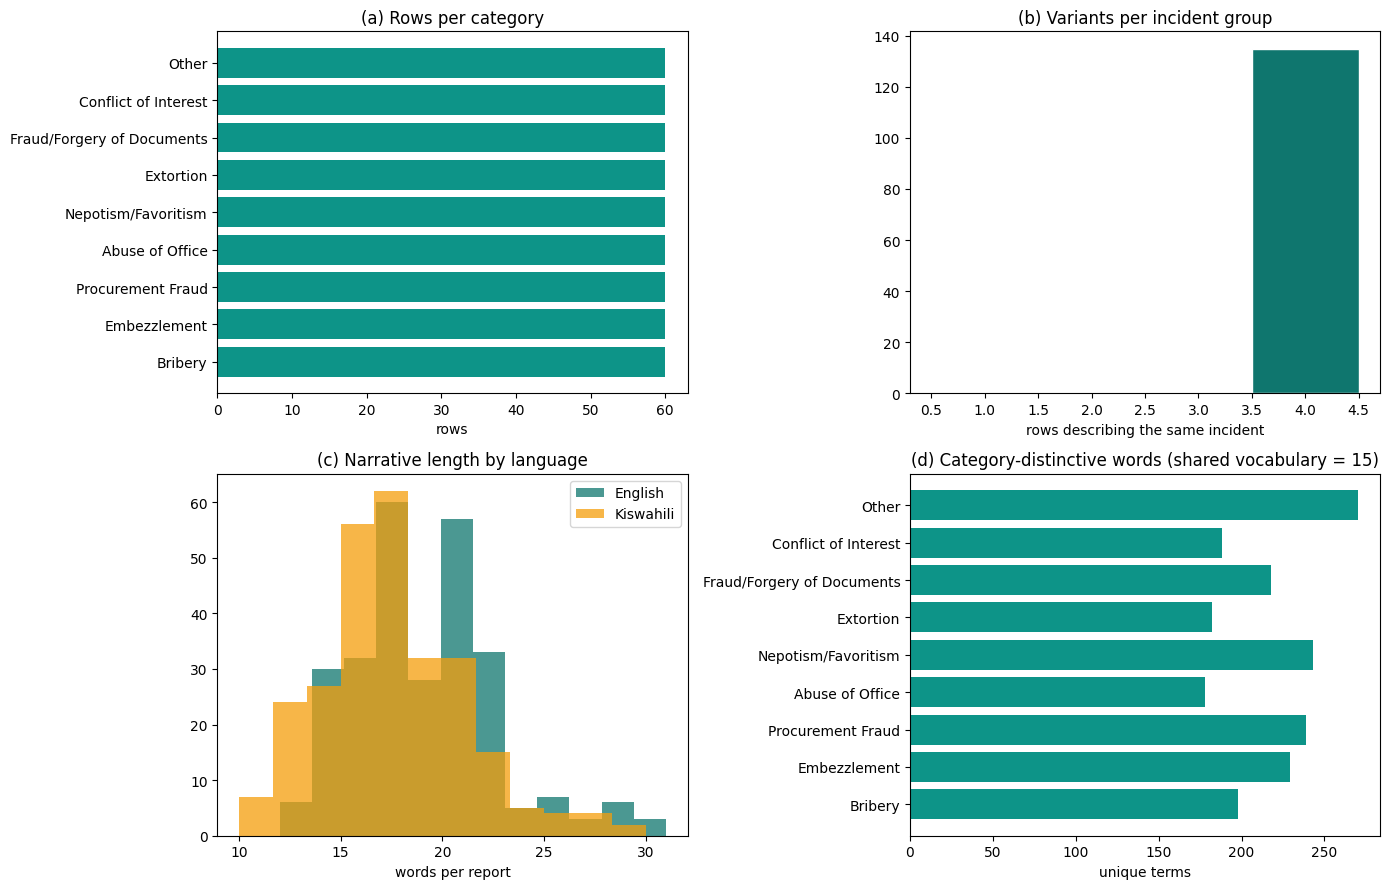

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) Class balance
counts_sorted = df["label"].value_counts().sort_values()
axes[0, 0].barh(counts_sorted.index, counts_sorted.values, color="#0d9488")
axes[0, 0].set_title("(a) Rows per category")
axes[0, 0].set_xlabel("rows")

# (b) Narratives per incident -> shows the grouping structure
per_group = df.groupby("group_id").size()
axes[0, 1].hist(per_group.values, bins=range(1, per_group.max() + 2), color="#0f766e",
                edgecolor="white", align="left")
axes[0, 1].set_title("(b) Variants per incident group")
axes[0, 1].set_xlabel("rows describing the same incident")

# (c) Narrative length by language
for lang, colour in (("English", "#0f766e"), ("Kiswahili", "#f59e0b")):
    axes[1, 0].hist(df[df["language"] == lang]["word_count"], bins=12, alpha=0.75,
                    label=lang, color=colour)
axes[1, 0].set_title("(c) Narrative length by language")
axes[1, 0].set_xlabel("words per report")
axes[1, 0].legend()

# (d) Vocabulary overlap: shared vs unique words per category
from sklearn.feature_extraction.text import CountVectorizer
vec = CountVectorizer(lowercase=True)
vocab_by_cat = {}
for cat in CATEGORIES:
    vec.fit(df[df["label"] == cat]["text"])
    vocab_by_cat[cat] = set(vec.vocabulary_)
shared = set.intersection(*vocab_by_cat.values())
axes[1, 1].barh(list(vocab_by_cat), [len(vocab_by_cat[c] - shared) for c in vocab_by_cat],
                color="#0d9488")
axes[1, 1].set_title(f"(d) Category-distinctive words (shared vocabulary = {len(shared)})")
axes[1, 1].set_xlabel("unique terms")

plt.tight_layout()
plt.show()


### What the exploration showed

1. **The classes are balanced** (60 rows per category). This is a property of the written corpus; real reports will be unbalanced, so the models use `class_weight="balanced"` and macro F1 is the main metric.
2. **The rows are not independent.** Each incident appears in four versions. If the versions were split at random, the model could learn an incident during training and be tested on a reworded copy of it, which is leakage. Validation therefore keeps each incident in a single fold.
3. **The reports are short**, about 17 to 19 words on average, which suits sparse TF-IDF features better than models built for long documents.
4. **There are two languages.** Kiswahili builds words from prefixes and suffixes, so whole-word features break up; character n-grams recover much of the signal.
5. **Categories share much of their vocabulary** (panel d). Words such as *officer*, *payment* and *report* appear everywhere, which is why keyword rules alone cannot separate the categories.

## 2.4 Preprocessing and feature engineering

All preprocessing happens inside the model pipeline, so the vectorisers are fitted only on the training folds and nothing from the test fold leaks into the features.

| Step | Setting and purpose |
|---|---|
| Lower case and accent removal | Treats "Afisa" and "afisa" as the same word |
| Whitespace clean-up | Removes formatting noise |
| Word TF-IDF, 1-2 word n-grams, sublinear term frequency | Captures phrases such as *bid rigging* |
| Character TF-IDF (`char_wb`), 3-5 character n-grams | Copes with spelling variation and Kiswahili word forms |
| `min_df=2` | Drops words that appear in only one report |
| `max_features=50000` per vectoriser | Keeps the feature space bounded |
| `class_weight="balanced"` | Prepares the model for unbalanced real data |
| Stop words kept | Words such as *without* matter in an allegation ("paid without a receipt") |

---
# 3. Methodology and Model Selection

## 3.1 Candidate models

Two candidates were chosen in advance instead of running an open-ended search, because a wide search on a small synthetic corpus would mostly fit noise.

| Candidate | Reason for including it | Weakness |
|---|---|---|
| Word TF-IDF (1-2) + logistic regression | Simple, interpretable baseline; its coefficients show which words drive each label | Ignores word structure and is sensitive to misspelling |
| Word + character TF-IDF + linear SVM | Character n-grams handle spelling and Kiswahili word forms; linear SVMs work well with many sparse features | Its scores are margins, not probabilities |
| Fine-tuned transformer such as mBERT (considered, not used) | Could be strongest on real multilingual text | No real labelled data to fine-tune on; 540 synthetic rows would only show over-fitting; too heavy for the server |

Linear models on TF-IDF features suit this problem: the reports are short, the corpus is small, the results need to be explainable to reviewers, and the model must score a report in milliseconds.

## 3.2 Validation design

```
OUTER : 5-fold StratifiedGroupKFold   -> estimates performance on unseen incidents
INNER : 3-fold grouped split          -> chooses between the two candidates
METRIC: macro F1                      -> every category counts equally
GROUP : incident group_id             -> versions of one incident never cross folds
```

This design was chosen for three reasons:

1. **Grouped folds** prevent the leakage described in Section 2.3.
2. **Nested selection** chooses the model inside each outer training fold, so the reported score includes the effect of choosing a model. Choosing on all the data and then reporting that score would overstate it.
3. **A majority-class baseline** is scored on the same folds, so every result can be compared with what a trivial model achieves.

## 3.3 Hyperparameters (fixed before training)

| Component | Setting | Reason |
|---|---|---|
| Word TF-IDF | `ngram_range=(1,2)`, `min_df=2`, `max_features=50000`, `sublinear_tf=True` | Phrases with noise control |
| Character TF-IDF | `analyzer="char_wb"`, `ngram_range=(3,5)`, `min_df=2`, `max_features=50000` | Word forms in two languages |
| Logistic regression | `class_weight="balanced"`, `max_iter=2000`, `random_state=42` | Handles unbalanced data, reproducible |
| Linear SVM | `class_weight="balanced"`, `random_state=42` | Strong on high-dimensional sparse data |
| Outer / inner folds | 5 / 3, shuffled, seeds 42 / 100+fold | Fixed in advance |

## 3.4 Building the models

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

MODEL_CANDIDATES = ("word_logistic", "word_char_linear_svc")


def _word_features():
    return TfidfVectorizer(
        analyzer="word", lowercase=True, strip_accents="unicode",
        ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True,
    )


def _char_features():
    return TfidfVectorizer(
        analyzer="char_wb", lowercase=True, strip_accents="unicode",
        ngram_range=(3, 5), min_df=2, max_features=50000, sublinear_tf=True,
    )


def build_model(name):
    if name == "word_logistic":
        return Pipeline([
            ("features", _word_features()),
            ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000,
                                              random_state=42)),
        ])
    if name == "word_char_linear_svc":
        return Pipeline([
            ("features", FeatureUnion([("word", _word_features()), ("char", _char_features())])),
            ("classifier", LinearSVC(class_weight="balanced", random_state=42)),
        ])
    raise ValueError(f"unknown candidate: {name}")


# Sanity check: both pipelines build and fit on a stratified sample covering all 9 classes.
_sample = df.groupby("label").head(6)   # 54 rows, every category represented
for _name in MODEL_CANDIDATES:
    _model = build_model(_name).fit(_sample["text"], _sample["label"])
    _accuracy = (_model.predict(_sample["text"]) == _sample["label"]).mean()
    print(f"{_name:26s} build+fit OK on {len(_sample)} rows (in-sample accuracy {_accuracy:.2f})")


word_logistic              build+fit OK on 54 rows (in-sample accuracy 1.00)
word_char_linear_svc       build+fit OK on 54 rows (in-sample accuracy 1.00)


## 3.5 Nested grouped cross-validation

In [6]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix)

TEXTS = df["text"].tolist()
LABELS = df["label"].tolist()
GROUPS = df["group_id"].tolist()


def compute_metrics(y_true, y_pred, labels=CATEGORIES):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return {
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "balanced_accuracy": round(float(balanced_accuracy_score(y_true, y_pred)), 4),
        "macro_f1": round(float(f1_score(y_true, y_pred, labels=labels, average="macro",
                                         zero_division=0)), 4),
        "per_category": {
            c: {"precision": round(float(p[i]), 4), "recall": round(float(r[i]), 4),
                "f1": round(float(f[i]), 4), "support": int(s[i])}
            for i, c in enumerate(labels)
        },
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }


def cross_validate_candidate(train_idx, name, n_splits, seed):
    """Grouped CV inside an outer training fold; returns out-of-fold predictions + macro F1."""
    t = [TEXTS[i] for i in train_idx]
    y = [LABELS[i] for i in train_idx]
    g = [GROUPS[i] for i in train_idx]
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    preds = [None] * len(train_idx)
    for tr, te in splitter.split(t, y, g):
        assert not (set(g[i] for i in tr) & set(g[i] for i in te)), "group leakage"
        model = build_model(name).fit([t[i] for i in tr], [y[i] for i in tr])
        for i, pred in zip(te, model.predict([t[i] for i in te])):
            preds[i] = str(pred)
    return preds, compute_metrics(y, preds)["macro_f1"]


def select_model(train_idx, n_splits=3, seed=42):
    scores = {name: cross_validate_candidate(train_idx, name, n_splits, seed)[1]
              for name in MODEL_CANDIDATES}
    return max(scores, key=scores.get), scores


print("Helpers ready.")


Helpers ready.


In [7]:
outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = [None] * len(df)
baseline_preds = [None] * len(df)
fold_records = []

for fold, (tr, te) in enumerate(outer_splitter.split(TEXTS, LABELS, GROUPS), start=1):
    # Leakage guard: no incident on both sides of the split.
    assert not (set(GROUPS[i] for i in tr) & set(GROUPS[i] for i in te)), "group leakage"

    chosen, inner_scores = select_model(tr, n_splits=3, seed=100 + fold)

    model = build_model(chosen).fit([TEXTS[i] for i in tr], [LABELS[i] for i in tr])
    fold_pred = model.predict([TEXTS[i] for i in te])
    for i, pred in zip(te, fold_pred):
        oof_preds[i] = str(pred)

    majority = Counter(LABELS[i] for i in tr).most_common(1)[0][0]
    for i in te:
        baseline_preds[i] = majority

    fold_records.append({
        "fold": fold,
        "selected": chosen,
        "test_rows": len(te),
        "test_incidents": len({GROUPS[i] for i in te}),
        "macro_f1": round(float(f1_score([LABELS[i] for i in te], fold_pred,
                                         labels=CATEGORIES, average="macro",
                                         zero_division=0)), 4),
        **{f"inner_{k}": v for k, v in inner_scores.items()},
    })

folds_df = pd.DataFrame(fold_records)
assert all(p is not None for p in oof_preds), "every row needs an out-of-fold prediction"
print(folds_df.to_string(index=False))


 fold             selected  test_rows  test_incidents  macro_f1  inner_word_logistic  inner_word_char_linear_svc
    1 word_char_linear_svc        108              27    0.8304               0.7578                      0.8088
    2 word_char_linear_svc        108              27    0.9019               0.7236                      0.7774
    3 word_char_linear_svc        108              27    0.8882               0.7333                      0.7829
    4 word_char_linear_svc        108              27    0.8918               0.7781                      0.8195
    5 word_char_linear_svc        108              27    0.8108               0.7132                      0.7634


---
# 4. Model Evaluation

## 4.1 Metrics used

| Metric | Meaning | Why it is used |
|---|---|---|
| Accuracy | Share of reports given the correct category | Easy to understand |
| Balanced accuracy | Average recall across categories | Not affected by class sizes |
| Macro F1 | Average of the per-category F1 scores | Main metric: a rare category counts as much as a common one |
| Per-category precision, recall and F1 | Which categories are reliable and which are confused | A missed extortion report matters more than a missed `Other` |
| Confusion matrix | Where the mistakes go | Shows which categories the model mixes up |

## 4.2 Results against the baseline

In [8]:
headline = pd.DataFrame([
    {"model": "Fold-local majority baseline",
     "accuracy": compute_metrics(LABELS, baseline_preds)["accuracy"],
     "balanced_accuracy": compute_metrics(LABELS, baseline_preds)["balanced_accuracy"],
     "macro_f1": compute_metrics(LABELS, baseline_preds)["macro_f1"]},
    {"model": "Nested grouped CV (selected model)",
     **{k: v for k, v in compute_metrics(LABELS, oof_preds).items()
        if k in ("accuracy", "balanced_accuracy", "macro_f1")}},
])

print(headline.to_string(index=False))
print()
print(f"Out-of-fold macro F1 across outer folds: "
      f"mean {folds_df.macro_f1.mean():.4f}  (spread {folds_df.macro_f1.std(ddof=0):.4f})")
print(f"Models chosen per fold: {folds_df.selected.value_counts().to_dict()}")


                             model  accuracy  balanced_accuracy  macro_f1
      Fold-local majority baseline    0.0815             0.0815    0.0582
Nested grouped CV (selected model)    0.8722             0.8722    0.8688

Out-of-fold macro F1 across outer folds: mean 0.8646  (spread 0.0367)
Models chosen per fold: {'word_char_linear_svc': 5}


## 4.3 Comparisons

Three comparisons are made:

1. **Model against baseline** (table above). The majority-class baseline scores close to chance on a balanced nine-class problem (accuracy 0.08 and macro F1 0.06 in this run, against 1/9, about 0.11), so the trained model has to clear it by a wide margin to be worth using.
2. **Candidate against candidate.** The inner scores for each fold (`inner_word_logistic` and `inner_word_char_linear_svc`) show which model won the selection and by how much.
3. **Category against category.** The per-category F1 scores (Section 4.5) show whether errors cluster between particular categories, such as bribery and extortion, which is the most useful information for reviewers.

## 4.4 Charts

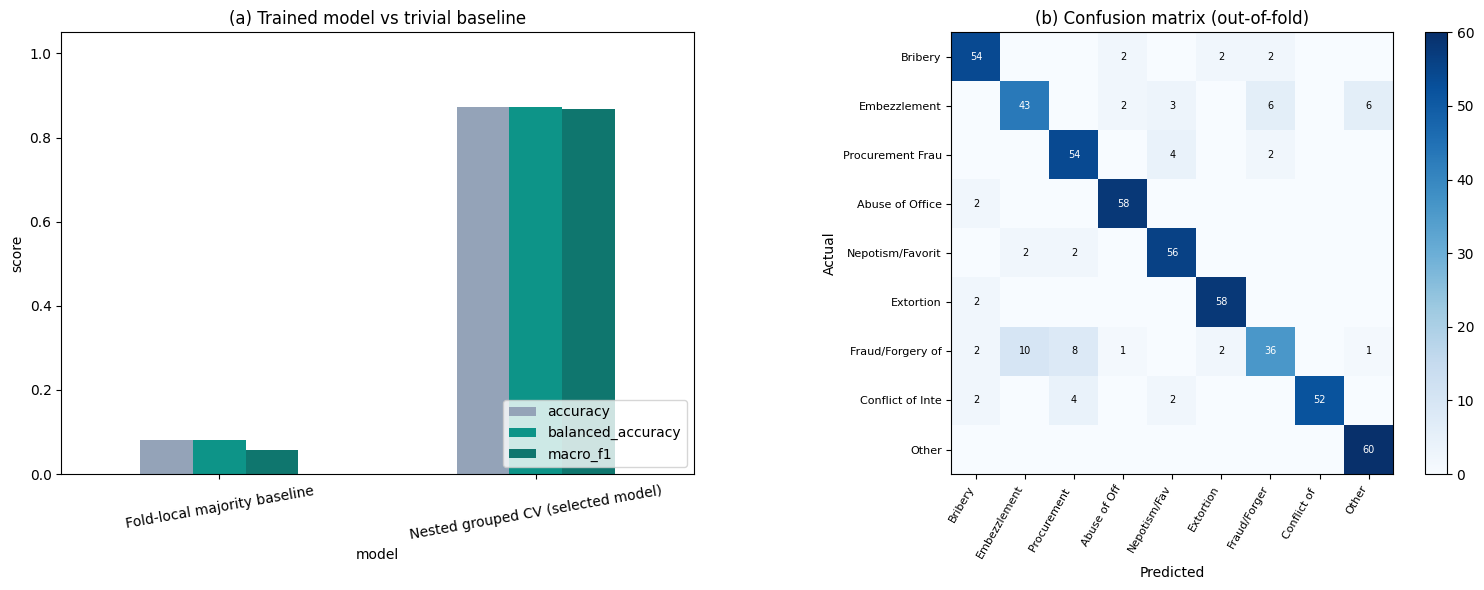

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

headline.set_index("model")[["accuracy", "balanced_accuracy", "macro_f1"]].plot.bar(
    ax=axes[0], color=["#94a3b8", "#0d9488", "#0f766e"], rot=10)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("score")
axes[0].set_title("(a) Trained model vs trivial baseline")
axes[0].legend(loc="lower right")

cm = compute_metrics(LABELS, oof_preds)["confusion_matrix"]
im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks(range(len(CATEGORIES)))
axes[1].set_yticks(range(len(CATEGORIES)))
axes[1].set_xticklabels([c[:12] for c in CATEGORIES], rotation=60, ha="right", fontsize=8)
axes[1].set_yticklabels([c[:16] for c in CATEGORIES], fontsize=8)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title("(b) Confusion matrix (out-of-fold)")
vmax = max(max(row) for row in cm)
for i in range(len(CATEGORIES)):
    for j in range(len(CATEGORIES)):
        if cm[i][j]:
            axes[1].text(j, i, cm[i][j], ha="center", va="center", fontsize=7,
                         color="white" if cm[i][j] > vmax / 2 else "black")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()


## 4.5 Results for each category

                            precision  recall      F1  support
Fraud/Forgery of Documents     0.7826  0.6000  0.6792     60.0
Embezzlement                   0.7818  0.7167  0.7478     60.0
Procurement Fraud              0.7941  0.9000  0.8438     60.0
Bribery                        0.8710  0.9000  0.8852     60.0
Nepotism/Favoritism            0.8615  0.9333  0.8960     60.0
Conflict of Interest           1.0000  0.8667  0.9286     60.0
Abuse of Office                0.9206  0.9667  0.9431     60.0
Other                          0.8955  1.0000  0.9449     60.0
Extortion                      0.9355  0.9667  0.9508     60.0


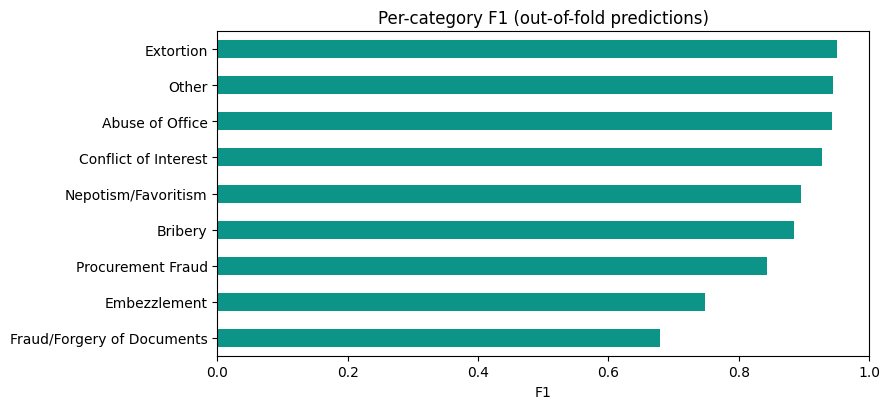

In [10]:
per_cat = pd.DataFrame(compute_metrics(LABELS, oof_preds)["per_category"]).T
per_cat.columns = ["precision", "recall", "F1", "support"]
per_cat = per_cat.sort_values("F1")
print(per_cat.to_string())

per_cat["F1"].plot(kind="barh", figsize=(9, 4.2), color="#0d9488",
                   title="Per-category F1 (out-of-fold predictions)")
plt.xlabel("F1")
plt.xlim(0, 1.0)
plt.tight_layout()
plt.show()


These synthetic scores do not justify trusting the suggestion for any category on its own. The live system shows the category suggestion without any probability or confidence value, and the label is always decided by the reviewers. The model never labels a report by itself.

## 4.6 Results by language

Kenya Watch accepts reports in English and Kiswahili, so the results are also computed for each language. This is only a first check, not a fairness guarantee. The Kiswahili in the corpus was written by me and has not been reviewed by a native speaker, so any gap should be read as a reason for proper review rather than as a conclusion.

In [11]:
subgroup_rows = []
for language in sorted(df["language"].unique()):
    idx = df.index[df["language"] == language].tolist()
    present = tuple(c for c in CATEGORIES if c in {LABELS[i] for i in idx})
    m = compute_metrics([LABELS[i] for i in idx], [oof_preds[i] for i in idx], present)
    subgroup_rows.append({"language": language, "rows": len(idx),
                          "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
print(pd.DataFrame(subgroup_rows).to_string(index=False))


 language  rows  accuracy  macro_f1
  English   270    0.8926    0.8894
Kiswahili   270    0.8519    0.8480


## 4.7 Limitations of these results

1. **The data is synthetic.** It was written to be learnable, and its regular phrasing and balanced classes raise the scores. The numbers say nothing about real Kenyan reports.
2. **There is no later-in-time test set.** A real deployment needs a test set of later incidents to detect changes in how people write reports.
3. **No native speaker has validated the Kiswahili or Sheng.** Slang and code-switched text were tested separately in the repository (`ml/lingo/`): on slang held back from training, macro F1 fell to about 0.22, and adding code-switched training examples raised it to 0.36 (unseen mixed text rose from 0.60 to 0.74). Vocabulary coverage is the main limit; Section 4.9 adds a layer that reads Swahili verb frames, which helps with grammar but not with slang words the model has never seen.
4. **The scores are not calibrated probabilities**, which is why the live system does not show them as confidence values.
5. **Fairness has only been checked by language.** A fuller evaluation would need acceptable error rates for each category agreed with the institutions.

The main contribution of this work is therefore the pipeline: a grouped, nested and multilingual evaluation that avoids leakage, together with a clear account of why its current scores cannot be presented as real-world accuracy.

## 4.8 Results on a more varied corpus

The corpus above is formal: almost every incident reads like *"A licensing officer allegedly asked
for an unofficial payment..."*. To check whether the model had learned that register rather than the
conduct, a second corpus of 216 rows (54 fictional incidents) was written in forms the first lacked:
first-person accounts, SMS spelling (*"dey askd me 4 500 2 fix ma permit"*), Sheng and code-switching
(*"Kanjo alinidai kitu kidogo"*), second-hand reports and questions
(`ml/src/generate_colloquial_dataset.py`). Both corpora were scored with the same pipeline and folds
in the repository (`ml/src/train.py`, `ml/src/diagnose_fit.py`). These repository figures are the ones
reported in the project documentation; this notebook is an independent re-implementation with
different fold boundaries, which is why its own score above (0.869) differs slightly:

| Corpus | Rows | Incidents | Macro F1 | Accuracy | Train-validation gap |
|---|---|---|---|---|---|
| Formal seed | 540 | 135 | 0.878 | 0.880 | 0.125 |
| Seed + colloquial | 756 | 189 | 0.835 | 0.835 | 0.170 |

Macro F1 fell although the model was unchanged, and a shuffled-label control still fell to chance
(0.0995 against 0.111), so the drop is not leakage: part of the first score measured how tidy the
training text was. The learning curve was still rising at full size (0.449 at 20% of the data, 0.830 at
100%), so the model is limited by data rather than by tuning. A readiness gate (`ml/src/readiness.py`)
passed five of seven checks and keeps the model labelled experimental until it is validated on
adjudicated real reports. The deployed model is trained on all 756 rows.


## 4.9 Understanding Kenyan street language (lugha ya mtaa)

Reports from Nairobi will often be written in Sheng. Beck (2015) studied about 32,000 words of natural conversation among young people in Eastleigh and found that Sheng is best described as a variety of Swahili: the **grammar of the verb stays Swahili**, with subject, tense, relative and object prefixes used fluently, while the **stem inside the verb changes**. Her examples include English stems in Swahili verbs (*a-si-contract*, *a-nge-tumi-a condom*, *m-na-think*), the repetitive or habitual extension *-ang-* (*wa-na-fany-ang-a*, "they keep doing"), class 6 *ma-* plurals for borrowed nouns (*ma-chali*, *ma-STIs*) and lengthened vowels in clipped words (*kolee* for college, *stoori* for story). She also found that vocabulary renews quickly and differs between estates, so no fixed word list stays complete.

This suggests a better way to handle street language than adding more synthetic rows. A word such as *anamwitishanga* ("he keeps demanding from him") is new to the model as a whole word, but it contains the familiar stem *itisha* (demand) inside a familiar frame: *a-na-mw-itish-ang-a*. The layer below reads that frame and adds the stem as an extra token, while keeping the original words:

1. **Glossary.** Known Sheng and Kiswahili phrases are mapped to standard words (*kitu kidogo* to "rushwa bribe"), matching whole words only.
2. **Verb frames.** Subject + tense (+ relative) (+ object) + stem, the negative frame (*si-taki*, *ha-tu-pend-i*) and habitual *hu-* are recognised; the stem is added, with *-ang-* and the passive *-w-* removed.
3. **Borrowed nouns and spelling.** *ma-* plurals (*maofficer* to *officer*) and lengthened letters (*pesaaa* to *pesa*) are reduced.

The same rules run in the live system (`backend/utils/shengMorphology.js`) and in training (`ml/src/text_prep.py`); a test checks that both prepare every training text identically, and the exported model records the rules it was trained with.

In [12]:
import re, unicodedata

GLOSSARY = {"kitu kidogo": "rushwa bribe", "chai ya": "rushwa bribe", "pesa ya chai": "rushwa bribe", "toa chai": "toa rushwa bribe", "kupiga chai": "rushwa bribe", "chai mzee": "rushwa bribe", "hongo": "rushwa bribe", "hongoh": "rushwa bribe", "hongoo": "rushwa bribe", "hongo ya": "rushwa bribe", "nikikataa": "refused extort", "nikikataa kulipa": "refused forced to pay extort", "tulikataa": "refused extort", "pesa chini ya meza": "rushwa bribe under the table", "chini ya meza": "under the table bribe", "kutiwa mfukoni": "rushwa bribe", "kuchomea": "rushwa bribe", "kuchoma": "rushwa bribe", "kutoa kitu": "rushwa bribe", "pesa ya mkono": "rushwa bribe", "bakshishi": "rushwa bribe", "zawadi ya kazi": "rushwa bribe", "chaidai": "demanded money bribe", "nidai": "demanded money", "wanadai": "demanded money", "alikuwa anadai": "demanded money", "kula pesa": "embezzle misappropriated funds", "kuliwa pesa": "embezzle misappropriated funds", "kula za umma": "embezzle public funds", "pesa imeliwa": "embezzle misappropriated funds", "kumezwa": "embezzle misappropriated funds", "kupotea kwa pesa": "missing funds", "pesa hazieleweki": "missing funds unexplained", "kuchota": "diverted funds misappropriat", "kuchota pesa": "diverted funds misappropriat", "kukata pesa": "diverted funds misappropriat", "kufuja": "misappropriat waste public funds", "kufuja pesa": "misappropriat waste public funds", "matumizi mabaya": "misappropriat misuse of public funds", "zabuni": "tender procurement", "kupanga zabuni": "bid rigging tender", "kupanga": "rigged arranged irregular", "tender zimepangwa": "bid rigging tender", "kupokea hongo kwa tender": "bribe tender procurement", "mkataba wa hewa": "ghost supplier inflated contract", "kampuni ya hewa": "ghost supplier", "tender ya hewa": "ghost supplier inflated contract", "bei imepandishwa": "inflated contract inflated price", "kupeana tender": "awarded tender supplier", "tender ya ndugu": "tender nepotism relative", "kuajiri ndugu": "nepotism hired relative", "ameajiri ndugu": "nepotism hired relative", "kuweka ndugu": "nepotism hired relative", "kupendelea": "favoritism nepotism", "upendeleo": "favoritism nepotism", "kujuana": "favoritism relative connection", "tuajiri": "hired", "wetu": "relative favoritism", "jamaa yake": "relative nepotism", "ndugu yake": "relative nepotism", "mtoto wake": "relative nepotism", "mtu wake": "relative favoritism", "kutumia ofisi": "abuse of office misuse position", "kutumia cheo": "abuse of office misuse position", "kutumia mamlaka": "abuse of office misuse authority", "amejipatia": "misappropriat benefited personally", "kujipatia": "benefited personally", "kunyanyasa": "abuse extort intimidate", "kudhulumu": "abuse extort", "vitisho": "threatened extort", "kunilazimisha": "forced to pay extort", "kulazimishwa": "forced to pay extort", "kunitishia": "threatened extort", "atakufanya nini": "threatened extort", "hamna njia": "forced extortion", "lazima ulipe": "forced to pay extort", "utalipa": "forced to pay extort", "kutishia": "threatened extort", "kutishia maisha": "threatened to kill extort", "kutishiwa": "threatened extort", "kutishiwa maisha": "threatened to kill extort", "kunichoma": "threatened extort", "kunichomeka": "threatened extort", "kuchomeka": "threatened extort", "kunichoma kisu": "threatened extort coerced", "kuchoma kisu": "threatened extort coerced", "kukuua": "threatened to kill", "kuuawa": "threatened to kill", "nitakuua": "threatened to kill", "tutakuua": "threatened to kill", "kukupiga": "coerced threatened extort", "kunipiga": "coerced threatened extort", "kukudhuru": "threatened extort", "utajuta": "threatened extort coerced", "mullah": "bribe money amount", "mula": "bribe money amount", "doo nyingi": "bribe money amount", "chedaz nyingi": "bribe money amount", "mkwanja mnene": "bribe money amount", "kitu kidogo kidogo": "rushwa bribe small", "toza kitu kidogo": "pay bribe", "panya route": "smuggling evasion secret route", "panya": "smuggle evasion", "gava pesa": "government funds public money", "pesa za gava": "government funds public money", "serikali pesa": "government funds public money", "pesa za serikali": "public funds government money", "magidha": "court case prosecution", "govala": "government state", "chedaz": "money", "cheddar": "money", "mkwanja": "money", "makwarkwar": "money", "cheng": "money", "ganji": "money", "chapaa": "money", "doo": "money", "doe": "money", "mundez": "money", "thao": "one thousand money amount", "jirongo": "five hundred money amount", "finje": "fifty money amount", "mbao": "twenty money amount", "kobole": "five money amount small amount", "karao": "police officer", "karaoke": "police officer", "kanjo": "city council enforcement officer", "kanjoo": "city council enforcement officer", "msapere": "elder respected person", "mdosi": "boss supervisor", "doshi": "boss supervisor", "mtu wa serikali": "government official", "mserikali": "government official", "godha": "steal theft", "zamwa": "pickpocketed theft stolen", "msanii": "thief thug", "mambaru": "detectives dci police investigation", "njege": "police officer", "karau": "police officer", "kanja": "pay give money", "dau": "money", "baroda": "money", "mita": "one million money amount", "jill": "two hundred money amount", "salasa": "thirty money amount", "kinde": "ten money amount", "chwani": "fifty money amount", "imbo": "fake counterfeit", "mbwenya": "court case legal", "kanairo": "nairobi", "sonko": "rich person influential", "cheti bandia": "fake document forged forgery", "hati bandia": "fake document forged forgery", "kubuni nyaraka": "forged falsified documents", "kuchakachua": "falsified forged rigged", "kuchakachua nyaraka": "forged falsified documents", "nyaraka za uongo": "fake document forged", "kudanganya": "fraud deception", "kupotosha": "fraud deception mislead", "maslahi binafsi": "conflict of interest personal interest", "mgongano wa maslahi": "conflict of interest", "anafaa mwenyewe": "personal interest conflict", "ofisi ya ardhi": "lands office land registry", "ofisi ya lands": "lands office land registry", "ofisi ya polisi": "police station", "kwa chief": "chief office", "kwa afisi": "office", "hospitali ya umma": "public hospital", "shule ya serikali": "public school", "sijui": "do not know unclear", "sina uhakika": "not sure unclear", "labda": "maybe unclear", "whatsapp": "whatsapp", "whatsap": "whatsapp", "whatsappi": "whatsapp"}
RULES = {"version": 1, "subject": ["ni", "u", "a", "tu", "m", "mu", "wa", "i", "li", "ya", "ki", "vi", "zi", "ku", "yu", "pa"], "tam": ["na", "li", "me", "ta", "ki", "nge", "ngali", "ka", "ja", "sha", "si"], "relative": ["ye", "o", "cho", "vyo", "zo", "lo", "yo", "po", "ko", "mo"], "object": ["ni", "ku", "m", "mw", "tu", "wa", "i", "li", "ya", "ki", "vi", "zi", "ji"], "negativeSubject": ["si", "hu", "ha", "hatu", "ham", "hamu", "hawa", "hai", "hali", "haya", "haki", "havi", "hazi", "haku", "hayu"], "negativeTam": ["ku", "ta", "ja", "na"], "habitual": ["hu"], "nounPlural": "ma", "minStem": 3, "minNounRest": 4, "minToken": 4}
VOWELS = set("aeiou")


def normalize_text(value):
    text = unicodedata.normalize("NFKD", str(value or ""))
    text = "".join(ch for ch in text if not unicodedata.combining(ch)).lower()
    return re.sub(r"[\W_]+", " ", text).strip()


_PATTERNS = [(re.compile(r"(?<![^\W_])" + re.escape(t) + r"(?![^\W_])"), f" {c} ")
             for t, c in sorted(GLOSSARY.items(), key=lambda item: -len(item[0]))]


def expand_lingo_terms(text):
    for pattern, replacement in _PATTERNS:
        text = pattern.sub(replacement, text)
    return re.sub(r"\s+", " ", text).strip()


def _longest_first(items):
    return sorted(items, key=lambda item: (-len(item), item))


R = {**RULES, **{k: _longest_first(RULES[k]) for k in ("subject", "tam", "object", "negativeSubject", "negativeTam", "habitual")},
     "relative": _longest_first([r for r in RULES["relative"] if len(r) >= 2])}


def _stem_variants(rest, negative_present):
    out = [rest]
    if re.search(r"(anga|angi|ange)$", rest) and len(rest) - 4 >= 2:
        out.append(rest[:-4] + "a")                       # habitual -ang-: itishanga -> itisha
    if rest.endswith("wa") and len(rest) >= 5:
        base = rest[:-2]                                  # passive -w-: tozwa -> toza, daiwa -> dai
        out.append(base if base[-1] in VOWELS else base + "a")
    if negative_present and rest.endswith("i") and len(rest) >= 4 and rest[-2] not in VOWELS:
        out.append(rest[:-1] + "a")                       # negative present: hatupendi -> penda
    return out


def _remainders(after_tam):
    found = []
    rel = next((r for r in R["relative"] if after_tam.startswith(r)), None)
    for rel_part in (["", rel] if rel else [""]):
        after_rel = after_tam[len(rel_part):]
        om = next((o for o in R["object"] if after_rel.startswith(o)), None)
        for om_part in (["", om] if om else [""]):
            rest = after_rel[len(om_part):]
            stripped = rel_part != "" or om_part != ""
            ok = (len(rest) >= R["minStem"] + 1 or (len(rest) == R["minStem"] and rest.endswith("i"))) if stripped \
                else len(rest) >= R["minStem"]
            if ok and any(ch in VOWELS for ch in rest) and rest not in found:
                found.append(rest)
    return found


def _parse_verb(token):
    for sc in R["subject"]:                               # subject + tense (+ relative) (+ object) + stem
        if token.startswith(sc):
            for tam in R["tam"]:
                if token[len(sc):].startswith(tam):
                    rests = _remainders(token[len(sc) + len(tam):])
                    if rests:
                        return [v for r in rests for v in _stem_variants(r, False)]
    for neg in R["negativeSubject"]:                      # negative frame
        if token.startswith(neg):
            after = token[len(neg):]
            for tam in R["negativeTam"]:
                if after.startswith(tam):
                    rests = _remainders(after[len(tam):])
                    if rests:
                        return [v for r in rests for v in _stem_variants(r, False)]
            if token.endswith("i"):
                rests = _remainders(after)
                if rests:
                    return [v for r in rests for v in _stem_variants(r, True)]
    for hab in R["habitual"]:                             # habitual hu-
        if token.startswith(hab):
            rests = _remainders(token[len(hab):])
            if rests:
                return [v for r in rests for v in _stem_variants(r, False)]
    return []


def analyse_token(token):
    if len(token) < R["minToken"] or not re.fullmatch(r"[a-z]+", token):
        return []
    extras = []
    word = re.sub(r"(.)\1{2,}", r"\1", token)            # pesaaa -> pesa
    if word != token:
        extras.append(word)
    if len(word) >= 5 and word[-1] in VOWELS and word[-1] == word[-2]:
        word = word[:-1]
        extras.append(word)                               # kolee -> kole
    if word.startswith(R["nounPlural"]) and len(word) - 2 >= R["minNounRest"]:
        extras.append(word[2:])                           # maofficer -> officer
    extras.extend(_parse_verb(word))
    return [e for e in extras if e != token and len(e) >= 3]


def prepare_model_text(value):
    normalized = normalize_text(value)
    expanded = expand_lingo_terms(normalized)
    extras = []
    for token in normalized.split(" "):
        for extra in analyse_token(token):
            if extra not in extras:
                extras.append(extra)
    return f"{expanded} {expand_lingo_terms(' '.join(extras))}".strip() if extras else expanded


examples = ["anamwitishanga", "alinidai", "asicontract", "walinithreaten", "wanafanyanga",
            "hatupendi", "anadaiwa", "maofficer", "pesaaa", "mkuchoma", "angetumia"]
print(f"{'word':18s} stems added")
print("-" * 52)
for word in examples:
    print(f"{word:18s} {', '.join(analyse_token(word)) or '(none)'}")
print()
print(prepare_model_text("Kanjo alinidai kitu kidogo, sasa anamwitishanga kila siku"))

word               stems added
----------------------------------------------------
anamwitishanga     mwitishanga, mwitisha, itishanga, itisha
alinidai           nidai, dai
asicontract        contract
walinithreaten     nithreaten, threaten
wanafanyanga       fanyanga, fanya
hatupendi          pendi, penda
anadaiwa           daiwa, dai
maofficer          officer
pesaaa             pesa
mkuchoma           (none)
angetumia          tumia

city council enforcement officer alinidai rushwa bribe sasa anamwitishanga kila siku demanded money dai mwitishanga mwitisha itishanga itisha


### Does it help? A controlled comparison

To test the layer, each held-out fold is also rewritten in the patterns Beck describes: English past-tense verbs become English stems inside a Swahili frame (*asked* becomes *aliask* or *aliniask*), Swahili verbs take the habitual *-ang-* (*aliomba* becomes *aliombanga*), English plural nouns take *ma-* (*officers* becomes *maofficer*) and some final vowels are lengthened. Only the test folds are rewritten; the model never trains on them. The same grouped folds and the selected linear SVM are used with and without the layer.

The rewriting rules were written by me with the layer in mind, so this checks that the layer handles the patterns Beck documents. It is not a measure of accuracy on real reports.

In [13]:
import random
from sklearn.preprocessing import FunctionTransformer

ENGLISH_VERBS = {"threatened": "threaten", "asked": "ask", "demanded": "demand", "requested": "request",
                 "forced": "force", "changed": "change", "altered": "alter", "diverted": "divert",
                 "forged": "forge", "falsified": "falsify", "awarded": "award", "hired": "hire",
                 "collected": "collect", "received": "receive", "used": "use", "approved": "approve",
                 "ordered": "order", "required": "require", "issued": "issue", "favored": "favour",
                 "allocated": "allocate", "removed": "remove", "fabricated": "fabricate",
                 "directed": "direct", "took": "take", "stole": "steal", "paid": "pay",
                 "refused": "refuse", "wanted": "want"}
PLURAL_NOUNS = {"officers": "officer", "documents": "document", "tenders": "tender", "contracts": "contract",
                "payments": "payment", "receipts": "receipt", "records": "record", "suppliers": "supplier",
                "funds": "fund", "permits": "permit", "bribes": "bribe", "relatives": "relative",
                "officials": "official", "certificates": "certificate", "invoices": "invoice"}
SWAHILI_VERB = re.compile(r"((?:a|wa|ni|tu)(?:li|na|me))([a-z]{3,}?)(a)")


def beck_rewrite(text, rng):
    out = []
    for word in text.split():
        core = re.sub(r"[^\w]", "", word.lower())
        tail = word[len(word.rstrip(".,;:!?")):]
        if core in ENGLISH_VERBS:
            word = ("alini" if rng.random() < 0.5 else "ali") + ENGLISH_VERBS[core] + tail
        elif core in PLURAL_NOUNS:
            word = "ma" + PLURAL_NOUNS[core] + tail
        else:
            match = SWAHILI_VERB.fullmatch(core)
            if match and not core.endswith("wa"):
                word = match.group(1) + match.group(2) + "anga" + tail
            elif len(core) >= 4 and core[-1] in "aeiou" and rng.random() < 0.15:
                word = core + core[-1] * 2 + tail
        out.append(word)
    return " ".join(out)


def street_model(use_layer):
    model = build_model("word_char_linear_svc")
    if use_layer:
        model.steps.insert(0, ("prep", FunctionTransformer(lambda xs: [prepare_model_text(x) for x in xs])))
    return model


rng = random.Random(2015)
STREET = [beck_rewrite(t, rng) for t in TEXTS]
print(f"Rows changed by the rewrite: {sum(a != b for a, b in zip(TEXTS, STREET))} of {len(TEXTS)}")
print("Example:", TEXTS[0]);  print("     ->", STREET[0]);  print()

scores = {(layer, kind): [] for layer in (False, True) for kind in ("original", "street")}
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(TEXTS, LABELS, GROUPS):
    truth = [LABELS[i] for i in te]
    for layer in (False, True):
        model = street_model(layer).fit([TEXTS[i] for i in tr], [LABELS[i] for i in tr])
        for kind, source in (("original", TEXTS), ("street", STREET)):
            pred = model.predict([source[i] for i in te])
            scores[(layer, kind)].append(f1_score(truth, pred, average="macro", zero_division=0))

comparison = pd.DataFrame([
    {"text preparation": "raw text" if not layer else "glossary + street-language layer",
     "original test text": f"{np.mean(scores[(layer, 'original')]):.3f} ± {np.std(scores[(layer, 'original')]):.3f}",
     "street-style test text": f"{np.mean(scores[(layer, 'street')]):.3f} ± {np.std(scores[(layer, 'street')]):.3f}"}
    for layer in (False, True)])
print(comparison.to_string(index=False))

Rows changed by the rewrite: 454 of 540


Example: A licensing officer allegedly asked for an unofficial payment before approving a complete small-business permit application.
     -> A licensing officer allegedly aliask for an unofficial payment before approving a complete small-business permit application.



                text preparation original test text street-style test text
                        raw text      0.865 ± 0.037          0.817 ± 0.043
glossary + street-language layer      0.883 ± 0.018          0.855 ± 0.021


### Results and what they mean

In the run above, on the 540-row formal corpus, the layer raised macro F1 on street-style test text from 0.817 to 0.855 and on the original text from 0.865 to 0.883, and it roughly halved the variation between folds. The repository runs the same comparison on the larger corpus (756 rows, including the colloquial and Sheng rows; `ml/lingo/evaluate_street_language.py`), and the full nested evaluation was repeated with the layer switched on:

| Measure (macro F1) | Before | With the layer |
|---|---|---|
| Street-style test text, 756-row corpus | 0.806 ± 0.034 | 0.824 ± 0.023 |
| Original test text, 756-row corpus | 0.830 ± 0.034 | 0.838 ± 0.019 |
| Nested evaluation, 756-row corpus | 0.835 | 0.843 |
| Nested evaluation, 540-row formal corpus | 0.878 (folds ± 0.045) | 0.881 (folds ± 0.026) |
| Kiswahili rows, 756-row corpus | 0.870 | 0.904 |
| Sheng rows, 756-row corpus | 0.714 | 0.706 |

The layer raises the scores a little and, more clearly, makes them steadier: the spread between folds falls, and the gain comes mainly from the weakest folds (on street-style text, the worst fold rose from 0.751 to 0.798). The largest gain is on Kiswahili rows, where reading the verb frame (*a-na-dai-w-a*, *a-li-tishi-a*) recovers stems the model already knows.

The hand-written Sheng rows did not improve, and Beck's work explains why: Sheng innovates mainly in its vocabulary, and a slang word the model has never seen (*kanjo*, *doo*) has no stem to recover. That part can only be covered by vocabulary. The live system already supports this: reviewers can propose new Sheng terms, an administrator approves them, and they extend the glossary without retraining. Adding slang terms by looking at which test rows failed would have raised the score here, but it would no longer have been a fair test.

The layer also exposed a fault in the live glossary: a pattern intended to match whole words was matching inside longer words, so *mkuchoma moto* (burning something) was read as a bribery term. That was corrected, and a test now guards it.

## 4.10 Closing the gap between formal and street wording

Cross-validation inside one corpus flatters a model, because the test reports are written in the same style as the training reports. A harder and more realistic test is to train only on the formal corpus and then test on reports written separately in a different style. The colloquial corpus (216 rows: short first-person accounts, SMS spelling, Sheng and code-switching) is loaded below for exactly that.

That test exposed the real weakness. The glossary correctly turns *kitu kidogo*, *hongo* and *chai* into "rushwa bribe", but the formal training reports never use those words; they say "asked for an unofficial payment". The two styles describe the same acts in different vocabulary, and nothing connected them.

The fix is a **concept layer**: a controlled vocabulary in which every way of expressing one idea maps to a single concept token. "Unofficial payment", "kickback", *rushwa*, *hongo* and *kitu kidogo* all add `concept_bribe`; "asked for", "demanded", *dai*, *itisha* and *omba* add `concept_demand`. The concepts follow the elements of the offences in the Anti-Corruption and Economic Crimes Act and the Bribery Act, with standard English and Kiswahili terms, the project's Sheng glossary and documented Sheng words for money and police. Because a formal report and a street report now share concept tokens, what the model learns from one carries over to the other. The word and character n-grams were also widened slightly (words seen once are kept; character n-grams span 2 to 6 letters), which a comparison of several model variants showed to help.

In [14]:
from sklearn.preprocessing import FunctionTransformer
COLLOQUIAL_CSV = "text,label,group_id,language,county\nAsked for 500 before he would stamp my papers.,Bribery,colloquial-bribery-01,English,Mombasa\nthe clerk wanted something small to sign my form,Bribery,colloquial-bribery-01,English,Kisumu\nAlinidai kitu kidogo ndio apige stempu.,Bribery,colloquial-bribery-01,Sheng,Nakuru\nmsee akaniambia nilete hongo ya 500,Bribery,colloquial-bribery-01,Sheng,Meru\ndey askd me 4 500 2 fix ma permit,Bribery,colloquial-bribery-02,English,Kisumu\nofficer said pay me n ill approve it quick,Bribery,colloquial-bribery-02,English,Nakuru\nkanjo alinidai 500 nimpitishe haraka,Bribery,colloquial-bribery-02,Sheng,Meru\naliniambia nitoe chai ya stempu,Bribery,colloquial-bribery-02,Sheng,Kitui\nMy brother says the lands clerk wanted money to open the file.,Bribery,colloquial-bribery-03,English,Nakuru\nhe was asked for a bribe at the counter,Bribery,colloquial-bribery-03,English,Meru\nJamaa yangu alidaiwa rushwa kwa ofisi ya lands.,Bribery,colloquial-bribery-03,Sheng,Kitui\nkarani alitaka pesa aonee faili,Bribery,colloquial-bribery-03,Sheng,Kilifi\nWhy do I have to pay extra for a service I already paid for?,Bribery,colloquial-bribery-04,English,Meru\nthey want payment in hand to serve us,Bribery,colloquial-bribery-04,English,Kitui\nKwa nini nilipe zaidi kwa huduma nimeshalipa?,Bribery,colloquial-bribery-04,Sheng,Kilifi\nwanataka malipo ya mkono kwa huduma,Bribery,colloquial-bribery-04,Sheng,Bungoma\nInspector from health came and demanded a gift for the certificate.,Bribery,colloquial-bribery-05,English,Kitui\nhe asked for something for himself before signing,Bribery,colloquial-bribery-05,English,Kilifi\nMkaguzi wa afya alidai zawadi kwa cheti.,Bribery,colloquial-bribery-05,Sheng,Bungoma\nalitaka kitu chake kabla ya kutia sahihi,Bribery,colloquial-bribery-05,Sheng,Nairobi\nThe guy at the window said no money no service.,Bribery,colloquial-bribery-06,English,Kilifi\nhe wanted a kickback to process my invoice,Bribery,colloquial-bribery-06,English,Bungoma\nMsee wa dirisha akasema hakuna pesa hakuna huduma.,Bribery,colloquial-bribery-06,Sheng,Nairobi\nalitaka kitu kidogo kushughulikia ankara,Bribery,colloquial-bribery-06,Sheng,Mombasa\nThe CDF money for the borehole is gone and nothing was built.,Embezzlement,colloquial-embezzlement-01,English,Mombasa\nthe funds disappeared and the project stopped,Embezzlement,colloquial-embezzlement-01,English,Kisumu\nMullah za CDF zimepotea na hakuna kisima.,Embezzlement,colloquial-embezzlement-01,Sheng,Nakuru\ndoo za mradi zilipotea ghafla,Embezzlement,colloquial-embezzlement-01,Sheng,Meru\nmoney 4 the shcool lunch program is missing,Embezzlement,colloquial-embezzlement-02,English,Kisumu\nthe bursary cash was withdrawn n never seen,Embezzlement,colloquial-embezzlement-02,English,Nakuru\npesa za chakula cha shule zimepotea,Embezzlement,colloquial-embezzlement-02,Sheng,Meru\nfedha za bursary zilichukuliwa hazikuonekana,Embezzlement,colloquial-embezzlement-02,Sheng,Kitui\nSays the clerk diverted the health budget to his own account.,Embezzlement,colloquial-embezzlement-03,English,Nakuru\nthe funds were misappropriated quietly,Embezzlement,colloquial-embezzlement-03,English,Meru\nAnasema karani alichota fedha za afya.,Embezzlement,colloquial-embezzlement-03,Sheng,Kitui\nfedha za umma zilitumika vibaya,Embezzlement,colloquial-embezzlement-03,Sheng,Kilifi\nWhere did the county money for the road go?,Embezzlement,colloquial-embezzlement-04,English,Meru\nthe budget for the dispensary vanished,Embezzlement,colloquial-embezzlement-04,English,Kitui\nFedha za barabara zilienda wapi?,Embezzlement,colloquial-embezzlement-04,Sheng,Kilifi\nbajeti ya zahanati ilipotea,Embezzlement,colloquial-embezzlement-04,Sheng,Bungoma\nHe took all the money and left the project half done.,Embezzlement,colloquial-embezzlement-05,English,Kitui\nthe cash meant for supplies was never used for supplies,Embezzlement,colloquial-embezzlement-05,English,Kilifi\nAlichukua doo zote akaacha mradi nusu.,Embezzlement,colloquial-embezzlement-05,Sheng,Bungoma\npesa ya vifaa haikununua vifaa,Embezzlement,colloquial-embezzlement-05,Sheng,Nairobi\nWater project money missing from the account,Embezzlement,colloquial-embezzlement-06,English,Kilifi\nthey ate the funds for the youth program,Embezzlement,colloquial-embezzlement-06,English,Bungoma\nPesa ya mradi wa maji haipo kwa akaunti,Embezzlement,colloquial-embezzlement-06,Sheng,Nairobi\nwalikula fedha za vijana,Embezzlement,colloquial-embezzlement-06,Sheng,Mombasa\nThe tender for the road was already decided before it opened.,Procurement Fraud,colloquial-procurement-fraud-01,English,Mombasa\nthe bid was rigged for one company,Procurement Fraud,colloquial-procurement-fraud-01,English,Kisumu\nZabuni ya barabara ilikuwa imeamuliwa kabla kufunguliwa.,Procurement Fraud,colloquial-procurement-fraud-01,Sheng,Nakuru\nzabuni ilipangwa kwa kampuni moja,Procurement Fraud,colloquial-procurement-fraud-01,Sheng,Meru\ncontract was inflated n the co is owned by a relative,Procurement Fraud,colloquial-procurement-fraud-02,English,Kisumu\nghost supplier invoiced for nothing,Procurement Fraud,colloquial-procurement-fraud-02,English,Nakuru\nbei ya mkataba ilipandishwa na kampuni ni ya ndugu,Procurement Fraud,colloquial-procurement-fraud-02,Sheng,Meru\nmsambazaji wa hewa alitoa ankara,Procurement Fraud,colloquial-procurement-fraud-02,Sheng,Kitui\nSays the evaluation committee read only one bid.,Procurement Fraud,colloquial-procurement-fraud-03,English,Nakuru\nthe award went to the company that did not quote lowest,Procurement Fraud,colloquial-procurement-fraud-03,English,Meru\nAnasema kamati ilisoma zabuni moja tu.,Procurement Fraud,colloquial-procurement-fraud-03,Sheng,Kitui\ntuzo ilienda kwa kampuni isiyo na bei ya chini,Procurement Fraud,colloquial-procurement-fraud-03,Sheng,Kilifi\nWhy did the hospital pay for 40 beds and receive 12?,Procurement Fraud,colloquial-procurement-fraud-04,English,Meru\nthe same supplier wins every tender,Procurement Fraud,colloquial-procurement-fraud-04,English,Kitui\nKwa nini hospitali ililipa vitanda 40 ikapokea 12?,Procurement Fraud,colloquial-procurement-fraud-04,Sheng,Kilifi\nmsambazaji mmoja hushinda zabuni zote,Procurement Fraud,colloquial-procurement-fraud-04,Sheng,Bungoma\nThe tender documents were changed after closing.,Procurement Fraud,colloquial-procurement-fraud-05,English,Kitui\nthe contract price doubled after signing,Procurement Fraud,colloquial-procurement-fraud-05,English,Kilifi\nNyaraka za zabuni zilibadilishwa baada ya kufungwa.,Procurement Fraud,colloquial-procurement-fraud-05,Sheng,Bungoma\nbei ya mkataba iliongezwa mara mbili,Procurement Fraud,colloquial-procurement-fraud-05,Sheng,Nairobi\ncompany registered last month won a 200m tender,Procurement Fraud,colloquial-procurement-fraud-06,English,Kilifi\nthey split the contract to avoid the limit,Procurement Fraud,colloquial-procurement-fraud-06,English,Bungoma\nkampuni iliyosajiliwa mwezi juzi ikashinda zabuni ya milioni,Procurement Fraud,colloquial-procurement-fraud-06,Sheng,Nairobi\nwaligawanya mkataba kuepuka kikomo,Procurement Fraud,colloquial-procurement-fraud-06,Sheng,Mombasa\nHe used his position to have my licence cancelled.,Abuse of Office,colloquial-abuse-of-office-01,English,Mombasa\nthe officer misused his office against me,Abuse of Office,colloquial-abuse-of-office-01,English,Kisumu\nAlitumia ofisi yake kufuta leseni yangu.,Abuse of Office,colloquial-abuse-of-office-01,Sheng,Nakuru\nalitumia cheo vibaya dhidi yangu,Abuse of Office,colloquial-abuse-of-office-01,Sheng,Meru\nchief used his power 2 close my shop,Abuse of Office,colloquial-abuse-of-office-02,English,Kisumu\nhe abused his position to punish me,Abuse of Office,colloquial-abuse-of-office-02,English,Nakuru\nchief alitumia mamlaka kufunga duka langu,Abuse of Office,colloquial-abuse-of-office-02,Sheng,Meru\nalitumia ofisi kuniadhibu,Abuse of Office,colloquial-abuse-of-office-02,Sheng,Kitui\nSays the director ordered staff to serve his friends first.,Abuse of Office,colloquial-abuse-of-office-03,English,Nakuru\nthe boss used the office for personal orders,Abuse of Office,colloquial-abuse-of-office-03,English,Meru\nAnasema mkurugenzi aliamuru wafuasi wahudumiwe kwanza.,Abuse of Office,colloquial-abuse-of-office-03,Sheng,Kitui\nbosi alitumia ofisi kwa maagizo binafsi,Abuse of Office,colloquial-abuse-of-office-03,Sheng,Kilifi\nWhy does the officer decide who gets served and who waits?,Abuse of Office,colloquial-abuse-of-office-04,English,Meru\nhe acts as if the office belongs to him,Abuse of Office,colloquial-abuse-of-office-04,English,Kitui\nKwa nini afisa anaamua nani ahudumiwe?,Abuse of Office,colloquial-abuse-of-office-04,Sheng,Kilifi\nanafanya kama ofisi ni yake,Abuse of Office,colloquial-abuse-of-office-04,Sheng,Bungoma\nThe officer refused to release my documents without reason.,Abuse of Office,colloquial-abuse-of-office-05,English,Kitui\nhe used his power to delay my case,Abuse of Office,colloquial-abuse-of-office-05,English,Kilifi\nAfisa alikataa kutoa nyaraka bila sababu.,Abuse of Office,colloquial-abuse-of-office-05,Sheng,Bungoma\nalitumia mamlaka kuchelewesha kesi yangu,Abuse of Office,colloquial-abuse-of-office-05,Sheng,Nairobi\nmanager blocked my transfer after I complained,Abuse of Office,colloquial-abuse-of-office-06,English,Kilifi\nhe misused the position to silence us,Abuse of Office,colloquial-abuse-of-office-06,English,Bungoma\nmeneja alizuia uhamisho wangu baada ya malalamiko,Abuse of Office,colloquial-abuse-of-office-06,Sheng,Nairobi\nalitumia cheo kutunyamazisha,Abuse of Office,colloquial-abuse-of-office-06,Sheng,Mombasa\n\"The job went to the manager's cousin, not to those who applied.\",Nepotism/Favoritism,colloquial-nepotism-favoritism-01,English,Mombasa\nthey hired a relative who never applied,Nepotism/Favoritism,colloquial-nepotism-favoritism-01,English,Kisumu\n\"Kazi ilienda kwa ndugu wa meneja, si kwa walioomba.\",Nepotism/Favoritism,colloquial-nepotism-favoritism-01,Sheng,Nakuru\nwaliajiri ndugu ambaye hakuomba,Nepotism/Favoritism,colloquial-nepotism-favoritism-01,Sheng,Meru\nhis daughter got the post w no interview,Nepotism/Favoritism,colloquial-nepotism-favoritism-02,English,Kisumu\nthey only hire ppl from their village,Nepotism/Favoritism,colloquial-nepotism-favoritism-02,English,Nakuru\nmtoto wake akapata kazi bila usaili,Nepotism/Favoritism,colloquial-nepotism-favoritism-02,Sheng,Meru\nwanaajiri ndugu tu,Nepotism/Favoritism,colloquial-nepotism-favoritism-02,Sheng,Kitui\nSays the promotion list is all names from one family.,Nepotism/Favoritism,colloquial-nepotism-favoritism-03,English,Nakuru\nthe contract was given to a family friend,Nepotism/Favoritism,colloquial-nepotism-favoritism-03,English,Meru\nAnasema orodha ya kupandishwa ni ndugu tu.,Nepotism/Favoritism,colloquial-nepotism-favoritism-03,Sheng,Kitui\nmkataba ulipewa rafiki wa familia,Nepotism/Favoritism,colloquial-nepotism-favoritism-03,Sheng,Kilifi\nWhy was I skipped when her nephew was hired?,Nepotism/Favoritism,colloquial-nepotism-favoritism-04,English,Meru\nthe vacancy was never advertised,Nepotism/Favoritism,colloquial-nepotism-favoritism-04,English,Kitui\nKwa nini nilipitwa huku mpwa wake akaajiriwa?,Nepotism/Favoritism,colloquial-nepotism-favoritism-04,Sheng,Kilifi\nnafasi haikutangazwa,Nepotism/Favoritism,colloquial-nepotism-favoritism-04,Sheng,Bungoma\nEvery posting in this office goes to the same clan.,Nepotism/Favoritism,colloquial-nepotism-favoritism-05,English,Kitui\nthe shortlist was already known,Nepotism/Favoritism,colloquial-nepotism-favoritism-05,English,Kilifi\nNafasi zote ofisi hii zinenda kwa kabila moja.,Nepotism/Favoritism,colloquial-nepotism-favoritism-05,Sheng,Bungoma\norodha ya mwisho ilijulikana,Nepotism/Favoritism,colloquial-nepotism-favoritism-05,Sheng,Nairobi\nmy sister was denied the job but the chief's son got it,Nepotism/Favoritism,colloquial-nepotism-favoritism-06,English,Kilifi\nfavouritism in the recruitment,Nepotism/Favoritism,colloquial-nepotism-favoritism-06,English,Bungoma\ndada yangu alinyimwa kazi lakini mtoto wa chief akapata,Nepotism/Favoritism,colloquial-nepotism-favoritism-06,Sheng,Nairobi\nupendeleo kwa ndugu kwenye kuajiri,Nepotism/Favoritism,colloquial-nepotism-favoritism-06,Sheng,Mombasa\nHe said if I refuse he will have me arrested.,Extortion,colloquial-extortion-01,English,Mombasa\nthe officer threatened me until I paid,Extortion,colloquial-extortion-01,English,Kisumu\nAlisema nikikataa atanifunga.,Extortion,colloquial-extortion-01,Sheng,Nakuru\nafisa alinitishia hadi nililipa,Extortion,colloquial-extortion-01,Sheng,Meru\nkarao said pay or ill sleep in cells,Extortion,colloquial-extortion-02,English,Kisumu\nthey threatened to cut me if i didnt pay,Extortion,colloquial-extortion-02,English,Nakuru\nkarao akasema lipe au ulale ndani,Extortion,colloquial-extortion-02,Sheng,Meru\nwalinitishia kunichoma kisu nikikataa,Extortion,colloquial-extortion-02,Sheng,Kitui\nSays the guard demanded money to let the lorry pass.,Extortion,colloquial-extortion-03,English,Nakuru\nhe forced my brother to pay at the gate,Extortion,colloquial-extortion-03,English,Meru\nAnasema mlinzi alidai pesa lori ipite.,Extortion,colloquial-extortion-03,Sheng,Kitui\nalimlazimisha ndugu yangu kulipa langoni,Extortion,colloquial-extortion-03,Sheng,Kilifi\nWhy must I pay to be released at the roadblock?,Extortion,colloquial-extortion-04,English,Meru\nhe would not let me go without payment,Extortion,colloquial-extortion-04,English,Kitui\nKwa nini nilipie nitolewe kwenye kizuizi?,Extortion,colloquial-extortion-04,Sheng,Kilifi\nhakuachia bila malipo,Extortion,colloquial-extortion-04,Sheng,Bungoma\nThe man at the gate threatened my staff until we paid.,Extortion,colloquial-extortion-05,English,Kitui\nhe demanded and warned us of consequences,Extortion,colloquial-extortion-05,English,Kilifi\nMtu wa lango alitishia wafanyakazi hadi tulilipa.,Extortion,colloquial-extortion-05,Sheng,Bungoma\nalidai na kututishia madhara,Extortion,colloquial-extortion-05,Sheng,Nairobi\naskari held my id n said pay 200 or else,Extortion,colloquial-extortion-06,English,Kilifi\nforced to pay under threat,Extortion,colloquial-extortion-06,English,Bungoma\naskari akashika kitambulisho akasema lipe 200 au la,Extortion,colloquial-extortion-06,Sheng,Nairobi\nkulazimishwa kulipa kwa vitisho,Extortion,colloquial-extortion-06,Sheng,Mombasa\nThe receipt they gave me has a different name on it.,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-01,English,Mombasa\nthe certificate is fake,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-01,English,Kisumu\nRisiti waliyonipa ina jina lingine.,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-01,Sheng,Nakuru\ncheti ni bandia,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-01,Sheng,Meru\nsignature on my form was forged,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-02,English,Kisumu\nthe land title is fake n was printed elsewhere,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-02,English,Nakuru\nsahihi kwenye fomu yangu ilighushiwa,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-02,Sheng,Meru\nhati ya ardhi ni bandia,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-02,Sheng,Kitui\nSays the payslip submitted was not the real one.,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-03,English,Nakuru\nthe academic paper is a forgery,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-03,English,Meru\nAnasema payslip iliyowasilishwa si ya kweli.,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-03,Sheng,Kitui\nkaratasi ya masomo ni ya kughushi,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-03,Sheng,Kilifi\nWhy does the record show a payment I never made?,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-04,English,Meru\nthe invoice number does not exist in the system,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-04,English,Kitui\nKwa nini rekodi inaonyesha malipo nisiyofanya?,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-04,Sheng,Kilifi\nnamba ya ankara haipo kwenye mfumo,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-04,Sheng,Bungoma\nThe clearance letter carries a stamp that is not theirs.,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-05,English,Kitui\nthey falsified the delivery note,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-05,English,Kilifi\nBarua ya kibali ina muhuri si wao.,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-05,Sheng,Bungoma\nwalighushi hati ya uwasilishaji,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-05,Sheng,Nairobi\nmy degree cert was changed,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-06,English,Kilifi\nthey edited the register to add a name,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-06,English,Bungoma\ncheti changu cha shahada kilibadilishwa,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-06,Sheng,Nairobi\nwalibadilisha rejista kuongeza jina,Fraud/Forgery of Documents,colloquial-fraud-forgery-of-documents-06,Sheng,Mombasa\nThe officer who approved the tender owns the company.,Conflict of Interest,colloquial-conflict-of-interest-01,English,Mombasa\nhe had a personal interest in the award,Conflict of Interest,colloquial-conflict-of-interest-01,English,Kisumu\nAfisa aliyeidhinisha zabuni anamiliki kampuni.,Conflict of Interest,colloquial-conflict-of-interest-01,Sheng,Nakuru\nalikuwa na maslahi binafsi kwenye tuzo,Conflict of Interest,colloquial-conflict-of-interest-01,Sheng,Meru\ndirector sits on the board n also owns the supplier,Conflict of Interest,colloquial-conflict-of-interest-02,English,Kisumu\nhe never declared his shares,Conflict of Interest,colloquial-conflict-of-interest-02,English,Nakuru\nmkurugenzi ni mjumbe na pia anamiliki msambazaji,Conflict of Interest,colloquial-conflict-of-interest-02,Sheng,Meru\nhakutoa tamko la hisa zake,Conflict of Interest,colloquial-conflict-of-interest-02,Sheng,Kitui\nSays the committee chair has a stake in the winning bid.,Conflict of Interest,colloquial-conflict-of-interest-03,English,Nakuru\nan undisclosed interest affected the decision,Conflict of Interest,colloquial-conflict-of-interest-03,English,Meru\nAnasema mwenyekiti ana hisa kwa zabuni iliyoshinda.,Conflict of Interest,colloquial-conflict-of-interest-03,Sheng,Kitui\nmaslahi yasiyotangazwa yaliathiri uamuzi,Conflict of Interest,colloquial-conflict-of-interest-03,Sheng,Kilifi\nWhy is his own brother working for the company he supervises?,Conflict of Interest,colloquial-conflict-of-interest-04,English,Meru\nhe approved a payment to himself,Conflict of Interest,colloquial-conflict-of-interest-04,English,Kitui\nKwa nini ndugu yake anafanya kazi kwa kampuni anayoisimamia?,Conflict of Interest,colloquial-conflict-of-interest-04,Sheng,Kilifi\naliidhinisha malipo kwake mwenyewe,Conflict of Interest,colloquial-conflict-of-interest-04,Sheng,Bungoma\nThe officer signed for land next to his own plot.,Conflict of Interest,colloquial-conflict-of-interest-05,English,Kitui\na financial interest was never disclosed,Conflict of Interest,colloquial-conflict-of-interest-05,English,Kilifi\nAfisa alitia sahihi ardhi jirani na yake.,Conflict of Interest,colloquial-conflict-of-interest-05,Sheng,Bungoma\nmaslahi ya kifedha hayakutangazwa,Conflict of Interest,colloquial-conflict-of-interest-05,Sheng,Nairobi\nmanager approved his wifes company,Conflict of Interest,colloquial-conflict-of-interest-06,English,Kilifi\nfamily interest in the contract,Conflict of Interest,colloquial-conflict-of-interest-06,English,Bungoma\nmeneja aliidhinisha kampuni ya mkewe,Conflict of Interest,colloquial-conflict-of-interest-06,Sheng,Nairobi\nmaslahi ya familia kwenye mkataba,Conflict of Interest,colloquial-conflict-of-interest-06,Sheng,Mombasa\nThe office sells public forms at three times the printed price.,Other,colloquial-other-01,English,Mombasa\nthey charge for a service that should be free,Other,colloquial-other-01,English,Kisumu\nOfisi inauza fomu kwa bei mara tatu.,Other,colloquial-other-01,Sheng,Nakuru\nwanatoza huduma ambayo ni bure,Other,colloquial-other-01,Sheng,Meru\nstaff keep our files n refuse to return them,Other,colloquial-other-02,English,Kisumu\nthe queue is moved only for those who know someone,Other,colloquial-other-02,English,Nakuru\nwafanyakazi wanashikilia faili zetu,Other,colloquial-other-02,Sheng,Meru\nfoleni inasogea kwa wanaojuana tu,Other,colloquial-other-02,Sheng,Kitui\nSays the office closed early for three weeks with no notice.,Other,colloquial-other-03,English,Nakuru\nnobody answers the phone or the counter,Other,colloquial-other-03,English,Meru\nAnasema ofisi ilifungwa wiki tatu bila taarifa.,Other,colloquial-other-03,Sheng,Kitui\nhakuna anayejibu simu wala dirisha,Other,colloquial-other-03,Sheng,Kilifi\nWhy are we sent from one office to another for the same paper?,Other,colloquial-other-04,English,Meru\nnobody will say who is responsible,Other,colloquial-other-04,English,Kitui\nKwa nini tunapelekwa ofisi moja hadi nyingine?,Other,colloquial-other-04,Sheng,Kilifi\nhakuna anayesema nani mhusika,Other,colloquial-other-04,Sheng,Bungoma\nThe public notice was changed after people complained.,Other,colloquial-other-05,English,Kitui\nthe rules keep changing without explanation,Other,colloquial-other-05,English,Kilifi\nTaarifa ya umma ilibadilishwa baada ya malalamiko.,Other,colloquial-other-05,Sheng,Bungoma\nsheria zinabadilika bila maelezo,Other,colloquial-other-05,Sheng,Nairobi\nwater point closed for months no reason,Other,colloquial-other-06,English,Kilifi\npromised road never built no explanation,Other,colloquial-other-06,English,Bungoma\nkituo cha maji kimefungwa miezi hakuna sababu,Other,colloquial-other-06,Sheng,Nairobi\nbarabara iliyoahidiwa haikujengwa,Other,colloquial-other-06,Sheng,Mombasa\n"
col_df = pd.read_csv(io.StringIO(COLLOQUIAL_CSV))
print(f"Colloquial corpus: {len(col_df)} rows, {col_df.group_id.nunique()} incidents, languages {dict(col_df.language.value_counts())}")

CONCEPTS = {"bribe": ["bribe", "bribes", "bribery", "bribed", "kickback", "kickbacks", "inducement", "unofficial payment", "unofficial fee", "facilitation fee", "under the table", "rushwa", "hongo", "kitu kidogo", "malipo yasiyo rasmi", "pesa ya mkono", "toa kitu"], "demand": ["demand", "demanded", "demanding", "demands", "ask for", "asked for", "asking for", "solicit", "solicited", "dai", "daiwa", "itisha", "omba", "taka", "wanted", "want"], "money": ["money", "cash", "payment", "pay", "paid", "shillings", "ksh", "kes", "fee", "pesa", "fedha", "malipo", "lipa", "doo", "ganji", "chapaa", "ngiri"], "threat": ["threat", "threats", "threaten", "threatened", "threatening", "intimidate", "intimidated", "intimidation", "coerce", "coerced", "force", "forced", "extort", "extorted", "extortion", "harass", "harassed", "harassment", "arrest", "arrested", "detain", "impound", "confiscate", "tishia", "vitisho", "lazimisha", "lazimishwa", "kamata", "kufungwa", "funga"], "public_funds_loss": ["embezzle", "embezzled", "embezzlement", "misappropriate", "misappropriated", "misappropriation", "divert", "diverted", "diversion", "siphon", "siphoned", "pocketed", "steal", "stole", "stolen", "theft", "missing funds", "public funds", "unaccounted", "fedha za umma", "pesa za umma", "kuiba", "iba", "ibiwa", "chota", "kula", "liwa", "potea", "fujo"], "procurement": ["tender", "tenders", "bid", "bids", "bidder", "bidding", "procurement", "supplier", "suppliers", "contractor", "contract", "contracts", "invoice", "invoices", "quotation", "inflated", "overpriced", "lpo", "zabuni", "mkandarasi", "mzabuni", "ununuzi"], "family_favour": ["relative", "relatives", "nephew", "niece", "cousin", "brother", "sister", "son", "daughter", "wife", "husband", "in law", "family", "clan", "tribe", "nepotism", "favoritism", "favouritism", "favoured", "favored", "ndugu", "binamu", "mpwa", "shemeji", "mkwe", "familia", "ukoo", "kabila", "upendeleo"], "forgery": ["forge", "forged", "forgery", "fake", "fabricate", "fabricated", "falsify", "falsified", "counterfeit", "doctored", "altered", "alter", "tamper", "tampered", "feki", "bandia", "ghushi", "kughushi", "ghushiwa"], "document": ["certificate", "document", "documents", "record", "records", "permit", "licence", "license", "receipt", "stamp", "signature", "id", "title deed", "cheti", "hati", "kibali", "leseni", "stakabadhi", "sahihi", "stempu"], "own_interest": ["conflict of interest", "own company", "his company", "her company", "owns", "owned", "shares", "shareholder", "stake", "business partner", "undisclosed", "did not declare", "kampuni yake", "maslahi", "hisa"], "misuse_power": ["abuse of office", "abuse", "abused", "misuse", "misused", "power", "authority", "position", "official vehicle", "government vehicle", "mamlaka", "cheo", "matumizi mabaya", "gari la serikali"], "official": ["officer", "official", "officials", "clerk", "inspector", "police", "policeman", "chief", "councillor", "governor", "mca", "afisa", "karani", "polisi", "askari", "kanjo", "karao", "sanse", "gavaa"], "service": ["service", "services", "serve", "approve", "approval", "process", "processing", "huduma", "hudumia", "idhinisha", "pitisha"]}
_CONCEPT_PATTERNS = [
    (name, re.compile(r"(?<![^\W_])(?:" + "|".join(re.escape(p) for p in sorted(set(CONCEPTS[name]), key=lambda x: (-len(x), x)))
                      + r")(?![^\W_])"))
    for name in sorted(CONCEPTS)
]


def prepare_v3(value):
    text = prepare_model_text(value)            # glossary + street-language layer from Section 4.9
    tokens = [f"concept_{name}" for name, pattern in _CONCEPT_PATTERNS if pattern.search(text)]
    return f"{text} {' '.join(tokens)}" if tokens else text


for sample in ["A licensing officer allegedly asked for an unofficial payment",
               "Kanjo alinidai kitu kidogo ndio apige stempu"]:
    print("\n", sample, "\n ->", " ".join(t for t in prepare_v3(sample).split() if t.startswith("concept_")))

Colloquial corpus: 216 rows, 54 incidents, languages {'English': np.int64(108), 'Sheng': np.int64(108)}

 A licensing officer allegedly asked for an unofficial payment 
 -> concept_bribe concept_demand concept_money concept_official

 Kanjo alinidai kitu kidogo ndio apige stempu 
 -> concept_bribe concept_demand concept_document concept_money concept_official


In [15]:
def text_model(prepare=None, rich=False):
    word = TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2),
                           min_df=1 if rich else 2, max_features=50000, sublinear_tf=True)
    char = TfidfVectorizer(analyzer="char_wb", lowercase=True, strip_accents="unicode",
                           ngram_range=(2, 6) if rich else (3, 5), min_df=2, max_features=50000, sublinear_tf=True)
    steps = [("prep", FunctionTransformer(lambda xs: [prepare(x) for x in xs]))] if prepare else []
    steps += [("features", FeatureUnion([("word", word), ("char", char)])),
              ("classifier", LinearSVC(class_weight="balanced", random_state=42))]
    return Pipeline(steps)


variants = {
    "raw text (original model)": dict(prepare=None, rich=False),
    "+ street-language layer (Section 4.9)": dict(prepare=prepare_model_text, rich=False),
    "+ concept layer and richer n-grams": dict(prepare=prepare_v3, rich=True),
}
rows = []
for name, settings in variants.items():
    model = text_model(**settings).fit(TEXTS, LABELS)
    pred = model.predict(col_df.text)
    rows.append({"model (trained on the formal corpus only)": name,
                 "macro F1 on the colloquial corpus": round(f1_score(col_df.label, pred, average="macro"), 3),
                 "Sheng rows": round(f1_score(col_df.label[col_df.language == "Sheng"], pred[col_df.language == "Sheng"], average="macro"), 3)})
print(pd.DataFrame(rows).to_string(index=False))

model (trained on the formal corpus only)  macro F1 on the colloquial corpus  Sheng rows
                raw text (original model)                              0.652       0.611
    + street-language layer (Section 4.9)                              0.623       0.568
       + concept layer and richer n-grams                              0.680       0.646


### Knowing when to be unsure

A suggestion is only useful if the reviewer can tell when to trust it. A linear SVM gives margins, not probabilities, and turning them into probabilities with a plain softmax gives badly miscalibrated values. The cell below fits a single **temperature** on grouped out-of-fold scores so that the probabilities become calibrated, measured by the expected calibration error (ECE, the gap between stated confidence and actual accuracy). The live system then shows a single category when the calibrated probability is at least 0.6, and otherwise says that the model is unsure and names the two most likely categories. No number is ever shown to the reviewer.

In [16]:
from scipy.optimize import minimize_scalar

v3 = lambda: text_model(prepare=prepare_v3, rich=True)
decisions = np.zeros((len(TEXTS), len(CATEGORIES)))
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(TEXTS, LABELS, GROUPS):
    fold_model = v3().fit([TEXTS[i] for i in tr], [LABELS[i] for i in tr])
    decisions[te] = fold_model.decision_function([TEXTS[i] for i in te])
classes = fold_model.classes_
truth = np.searchsorted(classes, LABELS)


def calibrated(d, temperature):
    z = d / temperature
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def ece(p, y):
    conf, ok, total = p.max(axis=1), p.argmax(axis=1) == y, 0.0
    for low in np.linspace(0, 1, 10, endpoint=False):
        b = (conf > low) & (conf <= low + 0.1)
        if b.any():
            total += b.mean() * abs(ok[b].mean() - conf[b].mean())
    return total


temperature = minimize_scalar(lambda t: -np.mean(np.log(calibrated(decisions, t)[np.arange(len(truth)), truth] + 1e-12)),
                              bounds=(0.01, 5), method="bounded").x
p = calibrated(decisions, temperature)
print(f"Temperature {temperature:.3f}; calibration error (ECE) {ece(calibrated(decisions, 1.0), truth):.3f} -> {ece(p, truth):.3f}\n")

full = v3().fit(TEXTS, LABELS)
pc = calibrated(full.decision_function(col_df.text), temperature)
yc = np.searchsorted(full.classes_, col_df.label)
for label, probs, y in (("formal corpus, out-of-fold", p, truth), ("colloquial corpus (style shift)", pc, yc)):
    confident = probs.max(axis=1) >= 0.6
    correct = probs.argmax(axis=1) == y
    top2 = np.argsort(-probs, axis=1)[:, :2]
    unsure_top2 = np.mean([y[i] in top2[i] for i in np.where(~confident)[0]]) if (~confident).any() else float("nan")
    print(f"{label:34s} overall accuracy {correct.mean():.3f} | confident on {confident.mean():.0%} "
          f"with accuracy {correct[confident].mean():.3f} | right answer in the top two when unsure: {unsure_top2:.3f}")

Temperature 0.134; calibration error (ECE) 0.623 -> 0.039



formal corpus, out-of-fold         overall accuracy 0.885 | confident on 88% with accuracy 0.950 | right answer in the top two when unsure: 0.762
colloquial corpus (style shift)    overall accuracy 0.685 | confident on 83% with accuracy 0.754 | right answer in the top two when unsure: 0.595


### Results in the project repository

The repository applies the same changes to the larger 756-row corpus and repeats the full nested evaluation (`ml/src/experiments.py`, `ml/src/train.py`):

| Measure (macro F1 unless stated) | Original | Street-language layer | + concepts and richer n-grams |
|---|---|---|---|
| Nested evaluation, 756-row corpus | 0.835 | 0.843 | **0.874** |
| Nested evaluation, 540-row formal corpus | 0.878 | 0.881 | **0.899** |
| Sheng rows, 756-row corpus | 0.714 | 0.706 | **0.764** |
| Kiswahili rows, 756-row corpus | 0.870 | 0.904 | **0.918** |
| Trained on formal, tested on colloquial | 0.652 | 0.623 | **0.680** |
| Calibration error (ECE) | 0.576 | 0.576 | **0.021** |
| Accuracy when the model is confident (86% of reports) | | | **0.932** |

The cross-corpus row is the one shown in the cell above. It also shows that the street-language layer on its own lowered that score: the glossary replaces slang such as *kitu kidogo* with standard words ("rushwa bribe") that the formal training reports never use. The concept layer more than recovers this by linking both wordings to the same concept. Keeping the original slang next to its glossary meaning was also tried and made no difference.

Each change was kept only because it improved the three-part test bench (in-domain, street-style rewrites and the cross-corpus test); other variants were tried and rejected, among them NB-SVM, an averaged ensemble and giving the concept tokens extra weight, all of which did no better or worse. The cross-corpus result is the most honest indicator here, and it shows that a gap remains between formal and informal wording. The concept vocabulary was written after some cross-corpus errors had been seen, although no phrase was copied from the test reports, so that number may be slightly optimistic. Real, reviewer-labelled reports remain the only way to know how the model performs in practice.

## 4.11 Learning what Sheng words mean from parallel text

Three further Kenyan-language sources were added for this work:

- an **English–Sheng parallel corpus** of about 5,000 sentence pairs, used with the owner's permission;
- **Sheng dictionary example phrases** from the think-ke Sheng dataset, used with permission;
- the **LughaGen Multilingual Kenyan Language Corpus** (LughaGen-Organization, CC BY-SA 4.0): machine-generated Sheng, Kiswahili, Luo, Kikuyu and Kamba text, about 13 million words in the part used here.

The permission-based texts are not included in this notebook or in the code repository; only what was learned from them is.

**A Sheng-to-English lexicon.** The parallel corpus pairs each English sentence with a Sheng one. IBM Model 1 (Brown et al., 1993), the classic statistical word-alignment method, uses those pairs to estimate which English word each Sheng word most often stands for. From about 5,000 pairs it learned 1,288 word pairs, such as *ganji* → money, *kanjo* → council, *manzi* → woman and *soo* → hundred.

**Only for words the model has never seen.** Adding these meanings to every report lowered accuracy on formal Kiswahili, whose words the model already handles well, so a meaning is added only when the word did not appear in the training data. Familiar words are left alone, and an unfamiliar street word gains an English meaning the concept layer can use (*ganji* → money → `concept_money`).

**Word clusters were tried and rejected.** Clusters learned from the 13 million unlabelled words (Turian et al., 2010) lowered every score, probably because the LughaGen text is machine-generated and much of it paraphrases religious text, so its contexts are far from corruption reports.

In [17]:
SHENG_LEXICON = {"aache": "away", "aah": "replied", "abebe": "carry", "acheki": "see", "acrucifaiwe": "crucify", "adam": "man", "aende": "man", "afike": "because", "aibu": "ashamed", "ajabb": "see", "akaamka": "got", "akaanguka": "fell", "akaanza": "began", "akabegin": "began", "akacheck": "went", "akacheki": "saw", "akachukua": "took", "akadeclare": "declared", "akadedi": "died", "akadrop": "fell", "akadunda": "fell", "akaenda": "went", "akafika": "went", "akafikia": "came", "akafungua": "opened", "akageiana": "gave", "akageuka": "turned", "akagive": "gave", "akagusa": "touched", "akaheal": "healed", "akainama": "bent", "akainuka": "got", "akaishia": "went", "akaita": "called", "akaitana": "called", "akajibu": "replied", "akajifunga": "outer", "akakam": "came", "akakemea": "rebuked", "akakick": "died", "akakitoa": "went", "akakuwa": "time", "akakwachu": "took", "akakwara": "denied", "akaleta": "brought", "akalia": "cried", "akam": "come", "akamcheki": "looked", "akamchukua": "took", "akamfuata": "followed", "akamjibu": "answered", "akamkamia": "came", "akamsend": "sent", "akamtupia": "asked", "akamwaga": "poured", "akamwai": "struck", "akamwangukia": "fell", "akamwingia": "entered", "akamwita": "called", "akamwuliza": "asked", "akaona": "saw", "akapata": "found", "akapeana": "gave", "akapoa": "sat", "akapolea": "sat", "akapray": "prayed", "akarauka": "got", "akarejea": "returned", "akareply": "replied", "akasend": "sent", "akasimama": "stood", "akaskia": "heard", "akasogelea": "came", "akasorora": "saw", "akaspend": "spent", "akastand": "stood", "akastraighten": "straightened", "akatoka": "went", "akatokezea": "came", "akatry": "tried", "akatulia": "stayed", "akatuma": "sent", "akatumana": "sent", "akauliza": "asked", "akaulizia": "asked", "akaunda": "made", "akavuka": "side", "akawaacha": "left", "akawaelimisha": "told", "akawagei": "gave", "akawaita": "called", "akawajibu": "replied", "akawauliza": "asked", "akazidi": "continued", "akazikwa": "buried", "akifunza": "teaching", "akikam": "coming", "akili": "heard", "akimesea": "now", "akipitia": "through", "akipoleaga": "sit", "akipray": "praying", "akipreach": "preaching", "akishia": "went", "akitembea": "walking", "akiwalk": "walking", "akizidi": "while", "alianza": "started", "alibaptize": "baptized", "alibonga": "spoke", "alicheck": "entered", "alicheki": "saw", "alichomoka": "came", "alidedi": "died", "alifaa": "come", "alifungua": "opened", "aligeiwa": "given", "aliishia": "went", "aliishigi": "lived", "aliita": "called", "aliitwa": "named", "alikam": "came", "alikwachu": "took", "alikwachuliwa": "taken", "alim": "betrayed", "alimaanisha": "meant", "alimada": "finished", "alimbongesha": "fearlessly", "alimcheki": "saw", "alimesea": "knew", "alimraise": "author", "alimsend": "sent", "alinisend": "sent", "alinituma": "sent", "alipata": "found", "alipeana": "given", "alipenda": "loved", "aliponywa": "healed", "aliprophesy": "prophesied", "alisha": "demon", "alishare": "shared", "alisimama": "stood", "aliskia": "heard", "alitaka": "wanted", "alitoa": "amazed", "alitokezea": "came", "aliuliza": "asked", "aliwagei": "gave", "aliwaiwa": "man", "aliweka": "put", "alizidi": "jews", "amani": "peace", "ameamini": "believes", "ameblessika": "blessed", "amebonga": "spoken", "amecheki": "seen", "amededi": "dead", "amedoze": "sleeps", "amefungwa": "bound", "ameglorifaiwa": "glorified", "amejazika": "awe", "amekam": "come", "amekwachu": "taken", "amelost": "lost", "amempata": "come", "amenigei": "given", "amenikaribisha": "welcomes", "amenisend": "sent", "amenituma": "sent", "amepagawa": "possessed", "amependa": "loved", "amepolea": "sitting", "amerise": "risen", "ameshoiwa": "seen", "ameshona": "strong", "amesimama": "standing", "amesota": "poor", "ametokezea": "appeared", "ametupwa": "thrown", "amewahi": "ever", "amewasukia": "made", "amezaliwa": "born", "amini": "believe", "anabaptize": "baptizing", "anadishi": "eats", "anado": "doing", "anaenda": "going", "anafunza": "teaching", "anaitwa": "named", "anajua": "knows", "anakam": "comes", "anamaanisha": "mean", "anamesea": "knows", "anameseka": "named", "anaskia": "hears", "anaskiza": "hears", "anaswear": "swears", "anatestify": "testifies", "anatoka": "comes", "anauliza": "asks", "anawant": "wants", "andru": "andrew", "angededi": "die", "angemwuza": "betray", "anifuate": "follow", "annoint": "anointed", "anywa": "whoever", "apeane": "sent", "apo": "standing", "appoint": "appointed", "approach": "approached", "arisha": "clean", "army": "centurion", "asimame": "stand", "assasinate": "kill", "asubuhi": "morning", "atachukua": "mine", "atafind": "find", "atageiana": "give", "ataingia": "enters", "ataishi": "live", "ataitwa": "called", "atakam": "comes", "atakeep": "keeps", "atampenda": "love", "atamshow": "eat", "atanyang": "whoever", "atarauka": "rise", "atasevika": "saved", "ataskia": "hear", "ataswear": "swears", "atatokezea": "come", "atatuma": "send", "aways": "away", "baada": "after", "baadaye": "after", "badala": "instead", "bado": "still", "bafore": "before", "bahada": "after", "bahadayez": "afterward", "bahari": "sea", "baking": "yeast", "baptiziwa": "baptized", "barabbus": "barabbas", "baro": "way", "bash": "feast", "beef": "against", "besht": "good", "beshte": "friend", "bila": "without", "bizna": "business", "blaspheme": "blaspheming", "bless": "blessed", "bora": "good", "boss": "sir", "bow": "bowed", "boy": "man", "bro": "brother", "bruzza": "brothers", "bubu": "mute", "buda": "father", "buzzenga": "father", "bwaku": "large", "capi": "while", "capuu": "captain", "cargo": "possessions", "carpet": "mat", "cert": "certificate", "chali": "son", "chapo": "unleavened", "cheki": "look", "chembe": "speck", "chini": "under", "chochote": "whatever", "chukua": "take", "chunga": "care", "cladi": "clothes", "code": "went", "constitution": "law", "contractor": "builders", "daddy": "father", "daily": "day", "damu": "blood", "davie": "david", "dedi": "died", "dee": "came", "deni": "owed", "devo": "devil", "dhambi": "sin", "dhefa": "father", "dibre": "bread", "dingo": "thief", "direct": "plainly", "disease": "spirits", "dishi": "food", "doaa": "door", "doh": "sold", "doiwa": "done", "dooa": "door", "dota": "daughter", "dotee": "daughter", "dunia": "world", "eeh": "yes", "elewa": "understand", "elezea": "even", "elizah": "elizabeth", "enzi": "throne", "fadhe": "father", "faina": "boat", "famo": "family", "fao": "first", "farisayo": "pharisees", "fathe": "father", "fikira": "thoughts", "fimbo": "staff", "finje": "groups", "fiti": "saw", "foree": "give", "forex": "tables", "freshi": "good", "fruits": "fruit", "fuata": "follow", "fumbo": "parable", "furaha": "joy", "galilaya": "galilee", "ganji": "money", "gava": "tax", "gazza": "gathered", "gei": "give", "gerro": "village", "gherro": "village", "ghetto": "village", "giza": "darkness", "govana": "governor", "grao": "ground", "grapes": "vineyard", "grave": "tomb", "greece": "grecian", "guarantee": "tell", "habari": "news", "hai": "nothing", "haikuwa": "because", "haiwezi": "cannot", "hajado": "done", "haki": "justice", "halo": "died", "hamjawai": "never", "hamjui": "know", "hamnyiti": "don", "hamuamini": "believe", "hamuelewi": "understand", "hamummesei": "know", "hamuwezi": "cannot", "hao": "house", "haradali": "mustard", "haraka": "going", "harusi": "bridegroom", "hatawahi": "never", "hatawai": "never", "haters": "enemies", "hatumesei": "don", "hatuwezi": "cannot", "hauwezi": "cannot", "hawaamini": "believe", "hawacheki": "see", "hawajafika": "saw", "hawakuamini": "believe", "hawakuget": "find", "hawakumesea": "realize", "hawakutaka": "want", "hawanyiti": "turn", "hazi": "husband", "healiwa": "healed", "hekalu": "temple", "hekima": "wisdom", "hesabu": "number", "heshima": "honor", "heshimu": "honor", "hide": "hidden", "higher": "prophet", "higherman": "prophets", "hiki": "come", "hio": "immediately", "holla": "son", "holyspirit": "holy", "huduma": "ministry", "hugeiana": "gives", "hukam": "come", "hupanga": "among", "hupeana": "gives", "hupenda": "therefore", "huruma": "mercy", "hutoka": "come", "huzuni": "grief", "ibaki": "remain", "ifanyike": "done", "ikagrow": "grew", "ikakam": "came", "ikakwachu": "seized", "ikamhide": "hid", "ikate": "cut", "ikatoka": "came", "iliandikwa": "written", "ilibongeshwa": "joel", "ilichukuaga": "day", "ilihappen": "happened", "iliitagwa": "called", "iliitwaga": "called", "ilikam": "came", "ilimfuata": "followed", "iliundwa": "made", "imagine": "suppose", "imani": "faith", "imeandikwa": "written", "imechorwa": "written", "imefika": "come", "imehappen": "happened", "imejaa": "full", "imekam": "come", "imelost": "lost", "imemsurround": "around", "imepandwa": "sown", "imepeanwa": "given", "imeshona": "full", "imestand": "valid", "inafanya": "causes", "inaitwa": "called", "inamaanisha": "mean", "inasema": "spoken", "inatoka": "comes", "inaweza": "come", "inazaa": "bear", "infact": "fact", "ingawa": "though", "injili": "fearlessly", "inuka": "get", "invitation": "invited", "isaiya": "spoken", "ishara": "signs", "isikuwe": "take", "itafunguliwa": "opened", "izzo": "isaiah", "jamaa": "man", "jamo": "james", "jana": "yesterday", "jangwa": "desert", "janjes": "gained", "jaymo": "james", "jela": "jail", "jemo": "james", "jeri": "jericho", "jerusa": "jerusalem", "jerusaa": "jerusalem", "jeshi": "centurion", "jicho": "eye", "jiji": "city", "jina": "name", "jinayako": "name", "jiokoe": "save", "jioni": "evening", "jiwe": "stone", "jizuia": "help", "jogoo": "rooster", "johnie": "john", "jonaa": "jonah", "jordo": "jordan", "jose": "joseph", "josee": "joseph", "juala": "basketfuls", "jude": "judas", "judee": "judas", "judgement": "judgment", "jueni": "know", "jungle": "desert", "kabla": "before", "kaburi": "tomb", "kabuti": "robe", "kam": "come", "kamili": "complete", "kamiti": "prison", "kamnyweso": "wine", "kamu": "come", "kamuni": "come", "kanda": "men", "kanisa": "church", "kanjo": "council", "karibu": "near", "kati": "among", "katikati": "through", "keja": "house", "kejani": "home", "kiapo": "oath", "kibao": "many", "kichaka": "grove", "kichwa": "head", "kick": "dead", "kidogo": "little", "kidole": "finger", "kifo": "death", "kijanaa": "young", "kijiti": "stalk", "kikapu": "basket", "kikombe": "cup", "kilema": "paralytic", "kilihappen": "happened", "kilipandwa": "sown", "kimeandikwa": "written", "kimehappen": "happened", "kinde": "ten", "kinywaji": "drink", "kiondo": "basketfuls", "kipimo": "measure", "kipofu": "blind", "kisima": "well", "kitambaa": "cloth", "kitambo": "long", "kiti": "seat", "kitu": "everything", "kiu": "thirsty", "kiuno": "around", "kizazi": "age", "kladi": "clothes", "kona": "end", "kondoo": "sheep", "koroboi": "lamps", "kra": "tax", "kristo": "christ", "kuamini": "believe", "kuanza": "began", "kuanzia": "hand", "kubaptize": "baptist", "kubaptiziwa": "baptized", "kuboti": "buy", "kubwa": "large", "kucheki": "see", "kuchora": "wrote", "kuchujwa": "thrown", "kuchukua": "take", "kucollect": "collectors", "kudedi": "death", "kudishi": "eat", "kudrink": "drink", "kufikiria": "thinking", "kufunza": "teach", "kugazza": "gather", "kugeiana": "give", "kuhappen": "happen", "kuheal": "heal", "kuhepa": "pray", "kuingia": "enter", "kuingiza": "fear", "kuja": "come", "kujaza": "filled", "kuji": "show", "kukanyagia": "footstool", "kukumada": "kill", "kukutana": "meet", "kuleta": "bring", "kulingana": "according", "kulipa": "pay", "kumada": "kill", "kumanga": "eat", "kumbe": "deceive", "kumbuka": "remember", "kumi": "ten", "kumliko": "takes", "kummada": "kill", "kumskiza": "hear", "kumtemea": "spit", "kumwai": "struck", "kunawa": "unwashed", "kundi": "herd", "kunimada": "kill", "kunywa": "drink", "kuokoa": "save", "kuona": "sight", "kuonyesha": "show", "kuosha": "wash", "kupanda": "sow", "kupeanwa": "given", "kupitia": "through", "kuponya": "heal", "kupraise": "praising", "kurauka": "resurrection", "kurejea": "returned", "kurudi": "coming", "kusameheana": "forgiveness", "kusimama": "stand", "kuskia": "heard", "kuspend": "spend", "kutairi": "circumcision", "kuteach": "called", "kutestify": "testify", "kuto": "ignorance", "kutuliza": "man", "kuvisit": "visit", "kuvuna": "hard", "kuwafunza": "teach", "kuwagei": "give", "kuwamada": "wanted", "kuwaseti": "apostles", "kuwatupa": "apostles", "kuzifungua": "whose", "kwanza": "first", "kwara": "deny", "kwenda": "went", "laterz": "later", "lazaro": "lazarus", "lebo": "clothes", "legal": "lawful", "leo": "today", "leta": "during", "leteni": "bring", "lighting": "lightning", "loaf": "loaves", "loan": "lend", "lundee": "asking", "maajabu": "great", "mabanga": "guard", "mabeshte": "friends", "maboi": "disciples", "maboiz": "disciples", "maboy": "men", "mabro": "brothers", "machief": "chief", "macho": "eyes", "machungu": "anguish", "madam": "woman", "madays": "days", "madee": "kill", "madem": "women", "madeni": "money", "madevo": "demons", "madhambi": "sins", "madisciples": "disciples", "mafans": "followers", "mafarisayo": "pharisees", "mafruit": "fruit", "mafruits": "fruit", "mafta": "oil", "mafumbo": "parables", "magithaa": "time", "magoti": "knees", "magugu": "weeds", "mahaters": "enemies", "maidhaa": "time", "maisha": "life", "maithaa": "time", "majamaa": "men", "majews": "jews", "maji": "water", "makabwela": "hypocrites", "malaika": "angel", "mamanzi": "women", "mamatha": "women", "mamboch": "servants", "mambuyu": "fathers", "mamode": "teachers", "mandush": "sparrows", "maneiba": "neighbors", "maneno": "words", "manga": "eat", "manzi": "woman", "maodijo": "teachers", "maombi": "prayer", "maparo": "parents", "mapasii": "priests", "mapepe": "splendor", "mapero": "parents", "maperoz": "parents", "mapharisayo": "pharisees", "mapharisee": "pharisees", "mapharisees": "pharisees", "mapriest": "priests", "mapriests": "priests", "maprophets": "prophets", "mara": "once", "marashi": "perfume", "marungu": "clubs", "masaa": "three", "mashahidi": "witnesses", "mashaito": "demons", "mashaitula": "demons", "mashtaka": "going", "masiku": "days", "masilva": "silver", "masilver": "silver", "masiz": "sisters", "maskio": "hear", "masoja": "soldiers", "massive": "great", "mataifa": "nations", "matawi": "branches", "mate": "spit", "matha": "mother", "mathaake": "mother", "mathaako": "mother", "mathaangu": "mother", "mathake": "mother", "mathayo": "matthew", "mathe": "mother", "mathee": "mother", "mathegi": "robbers", "matime": "time", "matope": "mud", "matunda": "fruit", "maubao": "hungry", "mavuno": "harvest", "mawatchie": "guards", "mawe": "stone", "mawimbi": "waves", "mbali": "distance", "mbanyu": "house", "mbegu": "seed", "mbele": "before", "mbingu": "heaven", "mbio": "ran", "mblind": "blind", "mboch": "servant", "mbovu": "bad", "mbuku": "book", "mbuyu": "father", "mbuyus": "father", "mbuyuz": "father", "mbwaku": "greater", "mbwenya": "cloak", "mchafu": "defile", "mchana": "day", "mchanga": "soil", "mcheki": "see", "mchungaji": "shepherd", "mcrucify": "crucify", "mdhi": "man", "mdhii": "man", "mdogo": "child", "mdomo": "mouth", "mdos": "enable", "meja": "great", "member": "number", "meno": "teeth", "merii": "mary", "meza": "table", "mfalme": "king", "mfuasi": "disciple", "mholy": "holy", "miaka": "years", "miba": "thorns", "miezi": "months", "miguu": "feet", "miiba": "thorns", "mikono": "hands", "mila": "tradition", "milele": "eternal", "milima": "mountains", "mimea": "plants", "mioto": "fearlessly", "mioyo": "hearts", "mission": "people", "miti": "trees", "mizigo": "men", "mjane": "widow", "mkanyo": "bread", "mkasimame": "stand", "mkate": "bread", "mkawashow": "tell", "mkia": "last", "mkidi": "child", "mkiingia": "enter", "mkono": "hand", "mkulima": "farmer", "mkuyu": "fig", "mliget": "price", "mlimada": "killed", "mlisakanya": "thousand", "mmeblesika": "blessed", "mmeshika": "caught", "mnacheki": "see", "mnajua": "know", "mnamesea": "know", "mnammesea": "know", "mnanimesea": "know", "mnanisaka": "answered", "mnataka": "want", "mnawant": "want", "mob": "many", "mode": "teachers", "modee": "teacher", "moko": "hired", "mose": "moses", "mosee": "moses", "moto": "fire", "moyo": "heart", "mpoa": "good", "mpya": "new", "mrighteous": "righteous", "msafara": "saul", "msakanyaji": "collector", "mse": "man", "msee": "man", "mseiya": "servant", "mshahara": "wages", "msick": "sick", "msigwaye": "afraid", "msiogope": "afraid", "msoo": "greater", "msoto": "poor", "mstrong": "strong", "msupa": "woman", "mtabaptiziwa": "baptized", "mtacheki": "see", "mtageiwa": "given", "mtaget": "find", "mtajua": "know", "mtanicheki": "see", "mtapokea": "receive", "mti": "tree", "mtoi": "son", "mtupu": "sent", "muamini": "believe", "muda": "long", "munamesea": "know", "munde": "money", "mundee": "money", "muthama": "mother", "mwaka": "year", "mwalimu": "teacher", "mwangaza": "light", "mwengine": "went", "mwenyewe": "himself", "mwezi": "moon", "mwili": "body", "mwishoni": "last", "mwishowe": "finally", "mwuliza": "asked", "mwulizeni": "ask", "mzae": "father", "mzeiya": "man", "mzima": "whole", "naamini": "believe", "nabonga": "language", "nacheki": "see", "nafaka": "grain", "nafsi": "soul", "nahapo": "man", "nails": "put", "naishia": "going", "najua": "know", "nakuomba": "beg", "nakupenda": "love", "nakushow": "tell", "nakushukuru": "thank", "namba": "number", "namesea": "know", "nane": "eight", "nare": "fire", "narudi": "things", "nashow": "tell", "nathaniel": "nathanael", "nawaambia": "assuredly", "nawaeleza": "tell", "nawaelimisha": "tell", "nawapea": "tell", "nawashow": "tell", "nawatuma": "sending", "nchi": "nation", "ndama": "fattened", "ndogo": "little", "neiba": "neighbor", "neti": "fish", "ngamia": "camel", "ngano": "wheat", "ngapi": "many", "ngovo": "five", "ngumu": "hard", "nguo": "garment", "nguruwe": "pigs", "nguvu": "power", "ngware": "early", "niamini": "believe", "nicheki": "see", "nico": "man", "nifuate": "follow", "nilicheki": "saw", "nilikam": "came", "nilikucheki": "see", "nilimaanisha": "meant", "nimechora": "written", "nimekam": "come", "nimewabongesha": "already", "nimewapenda": "loved", "nimewashow": "told", "nimse": "man", "ninacheki": "see", "ninakam": "coming", "ningekuwa": "know", "nishawashow": "told", "nishow": "tell", "nitabaki": "remain", "nitakugei": "give", "nitasend": "send", "nitatuma": "send", "nitauliza": "ask", "nitawashow": "show", "njaa": "hungry", "njema": "good", "njeve": "fear", "njia": "way", "njiani": "way", "njora": "sword", "nne": "four", "nyeupe": "white", "nyingine": "another", "nyuma": "behind", "nywele": "hair", "nzima": "whole", "ocha": "country", "odijo": "teacher", "officer": "officers", "ole": "woe", "ombe": "cattle", "ombea": "pray", "ordinaree": "ordinary", "otoree": "asked", "outmkono": "perform", "pano": "punishment", "panzi": "wild", "pap": "suddenly", "paralysed": "paralytic", "paree": "feast", "pasii": "priests", "peana": "give", "penda": "love", "pendaneni": "love", "peni": "yet", "perm": "permission", "personally": "come", "pesa": "money", "phillo": "philip", "philo": "philip", "pili": "second", "pita": "peter", "pitaa": "peter", "poa": "good", "pokea": "received", "powder": "yeast", "powers": "power", "preps": "preparation", "punda": "colt", "punde": "soon", "rahisi": "easier", "raia": "subjects", "rauka": "get", "raundi": "walked", "reali": "truth", "recession": "shriveled", "rela": "relatives", "religiously": "ceremonial", "rende": "crowd", "respect": "honor", "ritho": "watch", "rodi": "road", "saba": "seven", "sabato": "sabbath", "sadaka": "gift", "saducees": "sadducees", "safari": "journey", "safi": "clean", "safiri": "traveled", "sahani": "dipped", "saka": "seek", "sakanya": "take", "salasa": "thirty", "salo": "wages", "samaki": "large", "sandale": "sandals", "sasa": "now", "saulo": "saul", "sauti": "voice", "sawa": "right", "scatter": "scattered", "sema": "answered", "sense": "consented", "shakee": "vineyard", "shakeiwa": "shaken", "sheria": "law", "shilingi": "mina", "shout": "shouted", "shpiri": "spirit", "shtuka": "astonished", "shuka": "come", "sifa": "praise", "sijaget": "found", "sijakam": "come", "siku": "day", "simama": "stand", "simesei": "don", "simjui": "know", "simo": "simon", "sinia": "platter", "sip": "drink", "sita": "sixth", "siwamesei": "know", "siz": "sister", "skia": "heard", "skio": "ear", "skiza": "listen", "skizeni": "listen", "smarta": "full", "smata": "good", "sms": "message", "solar": "sun", "solo": "alone", "soma": "never", "sonkwo": "master", "soo": "hundred", "space": "room", "stevo": "stephen", "stool": "footstool", "stov": "lamps", "sudden": "suddenly", "sure": "surely", "swali": "question", "taa": "light", "talanta": "talents", "tangu": "made", "tano": "five", "tao": "town", "tasa": "barren", "tatu": "third", "tayari": "already", "teachings": "teaching", "tebo": "table", "tei": "wine", "tembea": "walk", "tena": "again", "tesimony": "testimony", "thao": "thousand", "thenashara": "twelve", "tichaa": "teacher", "timeza": "brought", "tokezea": "come", "toma": "thomas", "tucheki": "look", "tugetha": "together", "tugezza": "together", "tuki": "nothing", "tulicheki": "saw", "tulieni": "while", "tumake": "make", "tumbo": "womb", "tumecheki": "seen", "tunaishia": "going", "tunajua": "know", "tunamesea": "know", "tuseme": "suppose", "tuta": "going", "tutaget": "answered", "type": "kind", "ubani": "incense", "ubao": "hungry", "ucheki": "see", "uende": "leave", "ufalme": "kingdom", "ufuo": "shore", "ujuzi": "knowledge", "ukoma": "willing", "ukwela": "truth", "ukweli": "truth", "ulaya": "pigs", "ulimi": "tongue", "ulimwengu": "world", "ulinigei": "gave", "ulinipea": "gave", "ulinituma": "sent", "uliza": "ask", "ulizeni": "ask", "umejipenda": "yourself", "umekam": "come", "umenigei": "given", "unacheki": "see", "unadhani": "think", "unamesea": "know", "unanipenda": "love", "unaona": "see", "unataka": "want", "unawant": "want", "unawezaje": "replied", "unifuate": "follow", "unit": "detachment", "unyoya": "ran", "uongo": "false", "upepo": "wind", "ushahidi": "witness", "ushuru": "tax", "usigwaye": "afraid", "usiku": "night", "usiogope": "afraid", "usishow": "see", "usitry": "don", "uso": "face", "utacheki": "see", "utembee": "walk", "utukufu": "glory", "uwashow": "tell", "uwezo": "power", "uwongo": "false", "uza": "sell", "vajo": "virgin", "verandah": "courts", "viajabu": "like", "vibe": "amazed", "vidonda": "sores", "vijiji": "villages", "vilio": "weeping", "viongozi": "rulers", "vip": "honor", "vipande": "pieces", "vipofu": "blind", "vitambaa": "strips", "vitisho": "threats", "vitu": "things", "vunja": "broke", "wachana": "leave", "wacheki": "see", "wadhii": "people", "wadishi": "eat", "wadogo": "little", "wadosi": "officials", "wafalme": "kings", "wafike": "banquet", "wafuasi": "disciples", "wageini": "give", "wageni": "guests", "wagondi": "robbers", "wagonjwa": "sick", "waif": "wife", "waifudhes": "wife", "waisrael": "addressed", "waiter": "wait", "wajukuu": "descendants", "wakaamini": "believed", "wakaanza": "began", "wakacheki": "saw", "wakafika": "came", "wakaget": "found", "wakaishia": "went", "wakajam": "furious", "wakajazwa": "filled", "wakajiuliza": "even", "wakakam": "came", "wakakutana": "met", "wakakwachu": "took", "wakaleta": "brought", "wakam": "come", "wakambeba": "carried", "wakamchuja": "threw", "wakamfuata": "followed", "wakamgei": "hand", "wakamjibu": "answered", "wakamkamia": "came", "wakamletea": "brought", "wakampeleka": "led", "wakamrecognize": "recognized", "wakamstrip": "away", "wakamvalisha": "put", "wakamworship": "worshiped", "wakamwuliza": "asked", "wakaogopa": "afraid", "wakareply": "replied", "wakarudi": "went", "wakasaka": "sought", "wakashangaa": "amazed", "wakashoiana": "another", "wakashout": "shouted", "wakasimama": "stood", "wakaskia": "heard", "wakatokezea": "came", "wakatry": "tried", "wakatuma": "sent", "wakatumana": "sent", "wakauliza": "asked", "wakaulizana": "asked", "wakawauliza": "asked", "wakazusha": "complained", "wakibeba": "carrying", "wakibonga": "speaking", "wakicheki": "see", "wakidi": "children", "wakidishi": "eating", "wakifunza": "teaching", "wakiishia": "going", "wakikam": "coming", "wakileta": "bringing", "wakimfuata": "followed", "wakingoja": "waiting", "wakipray": "prayer", "wakisimama": "standing", "wakiskia": "hearing", "wakivuta": "shore", "wala": "nor", "waliamini": "believed", "walibelieve": "believed", "walicheki": "saw", "walidhani": "thought", "walidie": "died", "walidishi": "ate", "walifika": "arrived", "waliishia": "went", "walikam": "came", "walikwachu": "took", "walileta": "brought", "walimcheki": "saw", "walimu": "teachers", "walipenda": "loved", "walirudi": "returned", "walishoiwa": "told", "walishout": "shouted", "walishow": "told", "waliskia": "heard", "waliskizia": "heard", "walitaka": "wanted", "walizidi": "kept", "wameblesika": "blessed", "wamecheki": "seen", "wamededi": "dead", "wamedunga": "beside", "wamejazika": "joy", "wamekam": "come", "wameogopa": "afraid", "wamesimama": "standing", "wamesota": "poor", "wametulia": "sit", "wametuliza": "people", "wametumwa": "sent", "wamkanje": "saw", "wanaishi": "live", "wanamesea": "know", "wanarule": "teachers", "wanaskia": "heard", "wanatry": "trying", "wapangaji": "tenants", "warm": "warming", "warning": "warned", "wasaa": "hour", "wasaidizi": "associates", "wasee": "people", "waseiya": "come", "washow": "tell", "wasibonge": "speak", "watacheki": "see", "watakam": "come", "wataskia": "hear", "watatu": "three", "watoe": "see", "watoi": "children", "waulize": "ask", "wayahudi": "jews", "wazae": "elders", "wedo": "wedding", "weka": "put", "wengi": "many", "wengine": "others", "wenyewe": "yourselves", "wiked": "evil", "wiki": "week", "wingu": "cloud", "wipe": "wiped", "wira": "working", "wode": "water", "yankee": "young", "yenyewe": "itself", "yeyote": "anyone", "zachs": "zacharias", "zamo": "long", "zawadi": "reward", "zax": "zacchaeus", "zebedayo": "zebedee", "ziara": "named", "zihappen": "away", "zikadunda": "fell", "ziki": "see", "zilidunda": "fell", "zilipeanwa": "handed", "zimepeanwa": "given", "zimesamehewa": "forgiven", "zinanitolea": "works", "zitakam": "come"}
print(f"{len(SHENG_LEXICON)} learned Sheng-to-English pairs, for example:")
for word in ["ganji", "kanjo", "manzi", "msee", "kumada", "tao", "cheki", "soo", "mzae"]:
    print(f"  {word:8s} -> {SHENG_LEXICON.get(word)}")


def prepare_v4(value, known):
    normalized = normalize_text(value)
    text = prepare_model_text(value)                       # glossary + street-language layer (Section 4.9)
    words = normalized.split() + [w for token in normalized.split() for w in analyse_token(token)]
    seen, meanings = set(text.split()), []
    for word in words:
        meaning = SHENG_LEXICON.get(word)
        if meaning and word not in known and meaning not in seen:
            meanings.append(meaning)
            seen.add(meaning)
    if meanings:
        text = f"{text} {' '.join(meanings)}"
    tokens = [f"concept_{name}" for name, pattern in _CONCEPT_PATTERNS if pattern.search(text)]
    return f"{text} {' '.join(tokens)}" if tokens else text


known_demo = set(normalize_text(" ".join(TEXTS)).split())
print()
print(prepare_v4("Msee wa kanjo alitaka ganji ndio anipitishe", known_demo))

1288 learned Sheng-to-English pairs, for example:
  ganji    -> money
  kanjo    -> council
  manzi    -> woman
  msee     -> man
  kumada   -> kill
  tao      -> town
  cheki    -> look
  soo      -> hundred
  mzae     -> father

msee wa city council enforcement officer alitaka money ndio anipitishe taka man wanted concept_demand concept_money concept_official


In [18]:
from sklearn.base import BaseEstimator, TransformerMixin


class LexiconPrep(BaseEstimator, TransformerMixin):
    """Records the training words; adds Sheng meanings only for words outside them."""
    def __init__(self, use_lexicon=True):
        self.use_lexicon = use_lexicon

    def fit(self, X, y=None):
        self.known_ = set(normalize_text(" ".join(X)).split())
        return self

    def transform(self, X):
        return [prepare_v4(x, self.known_) if self.use_lexicon else prepare_v3(x) for x in X]


def lexicon_model(use_lexicon):
    word = TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2), min_df=1,
                           max_features=50000, sublinear_tf=True)
    char = TfidfVectorizer(analyzer="char_wb", lowercase=True, strip_accents="unicode", ngram_range=(2, 6),
                           min_df=2, max_features=50000, sublinear_tf=True)
    return Pipeline([("prep", LexiconPrep(use_lexicon)), ("features", FeatureUnion([("word", word), ("char", char)])),
                     ("classifier", LinearSVC(class_weight="balanced", random_state=42))])


rows = []
for use_lexicon in (False, True):
    in_domain = []
    for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(TEXTS, LABELS, GROUPS):
        m = lexicon_model(use_lexicon).fit([TEXTS[i] for i in tr], [LABELS[i] for i in tr])
        in_domain.append(f1_score([LABELS[i] for i in te], m.predict([TEXTS[i] for i in te]), average="macro"))
    cross = lexicon_model(use_lexicon).fit(TEXTS, LABELS).predict(col_df.text)
    rows.append({"model": "v3 (concepts, calibration)" if not use_lexicon else "v4: + Sheng lexicon (unknown words only)",
                 "in-domain macro F1 (formal corpus)": f"{np.mean(in_domain):.3f}",
                 "macro F1 on the colloquial corpus": f"{f1_score(col_df.label, cross, average='macro'):.3f}"})
print(pd.DataFrame(rows).to_string(index=False))

                                   model in-domain macro F1 (formal corpus) macro F1 on the colloquial corpus
              v3 (concepts, calibration)                              0.880                             0.680
v4: + Sheng lexicon (unknown words only)                              0.874                             0.680


### Results in the project repository

On the full three-part test bench and the nested evaluation of the 756-row corpus (`ml/src/experiments_corpora.py`, `ml/src/train.py`):

| Measure (macro F1 unless stated) | v3 | v4: + Sheng lexicon |
|---|---|---|
| Nested evaluation, 756-row corpus | 0.874 | **0.877** |
| Nested evaluation, 540-row formal corpus | 0.899 | **0.899** |
| Sheng rows, 756-row corpus | 0.764 | **0.773** |
| Kiswahili rows, 756-row corpus | 0.918 | 0.918 |
| Calibration error (ECE) | 0.021 | **0.017** |
| Accuracy when the model is confident | 0.932 | **0.934** |

In the run above, on the smaller 540-row formal corpus, the lexicon slightly lowered in-domain macro F1 (0.880 to 0.874) and left the colloquial score unchanged, while on the larger corpus in the repository it raised the score slightly. All of these differences are within the noise of a few hundred rows: the change is small in either direction and not statistically significant, because the test sets are a few hundred synthetic rows. Its value is mainly for real reports, which will contain Sheng words that none of the training reports used; that is exactly when the lexicon is applied. Variants that were tried and rejected, with their measured effect, are listed in the repository (`ml/src/experiments_corpora.py`): applying the lexicon to every word (it corrected four colloquial reports but cost eight formal Kiswahili ones), restricting it to words that are much more frequent in Sheng than in Kiswahili text, and the word clusters.

The LughaGen corpus is credited as: LughaGen-Organization (2026), *LughaGen Multilingual Kenyan Language Corpus*, Hugging Face, CC BY-SA 4.0.

## 4.12 Ten thousand reports in the four ways Kenyans write

Kenyans describe the same incident in very different ways. Some write plain, careful English; some write plain Kiswahili; many mix the two in one sentence; and many, especially young people in towns, write Sheng. The corpora above have few examples of the last two, which is why the model was weakest on Sheng.

A third corpus was therefore generated (`ml/src/generate_register_dataset.py`): **2,500 fictional scenarios from everyday Kenyan settings**, such as traffic roadblocks, county askari (*kanjo*), the lands registry, Huduma Centres, county hospitals, Kenya Power, the chief's office, KRA at the port, Form One admissions, bursary and CDF money, county tenders and county jobs. **Each scenario is written once in each of the four registers**, so the corpus has 10,000 reports. The four versions describe the same incident (the same official, place, amount, payment method, time and closing remark), share one `group_id`, and write money the way each register writes it: *KSh 500*, *shilingi mia tano*, *500 bob*, *soo tano*.

**How it is used.** Text generated from templates is easy for a model to memorise, so a score measured on this corpus would mean little. It is used **only on the training side**: it is added to every training fit at a quarter of the weight of a hand-written report, and every score is measured on the separately written corpora above.

In [19]:
from pathlib import Path

REGISTERS_PATH = Path("ml/data/synthetic/kenya_watch_synthetic_registers.csv")
REGISTERS_URL = ("https://raw.githubusercontent.com/Matrixbenny/Kenyawatch/main/"
                 "ml/data/synthetic/kenya_watch_synthetic_registers.csv")
reg_df = pd.read_csv(REGISTERS_PATH if REGISTERS_PATH.is_file() else REGISTERS_URL)
print(f"Register corpus: {len(reg_df)} reports, {reg_df.group_id.nunique()} scenarios, "
      f"{reg_df.text.nunique()} distinct texts")
print(reg_df.language.value_counts().to_string())
print()
for group in reg_df.group_id.drop_duplicates().sample(3, random_state=7):
    scenario = reg_df[reg_df.group_id == group]
    print(f"--- {scenario.label.iloc[0]}")
    for _, row in scenario.iterrows():
        print(f"  [{row.language:9s}] {row.text}")

Register corpus: 10000 reports, 2500 scenarios, 10000 distinct texts
language
English      2500
Kiswahili    2500
Mixed        2500
Sheng        2500

--- Other
  [English  ] There is no water or toilet at the chief's office, and people wait outside in the sun all day.
  [Kiswahili] Hakuna maji wala choo katika ofisi ya chifu, na watu husubiri juani siku nzima.
  [Mixed    ] Hakuna maji ama toilet pale office ya chief, na watu wanangoja nje kwa jua siku nzima.
  [Sheng    ] Hakuna maji ama choo pale ofisi ya chifu, wasee wanangoja kwa jua siku nzima.
--- Procurement Fraud
  [English  ] Only one bidder was allowed to submit for the tender for medical supplies; the others were turned away. Kindly act on this.
  [Kiswahili] Mzabuni mmoja tu ndiye aliruhusiwa kuwasilisha zabuni ya vifaa vya matibabu, wengine wakafukuzwa. Tafadhali chukueni hatua.
  [Mixed    ] Ni bidder mmoja tu aliruhusiwa ku-submit tender ya medical supplies, wengine wakafukuzwa. Kindly chukueni action.
  [Sheng    ] wue

In [20]:
SUPPLEMENT_WEIGHT = 0.25
REG_TEXTS, REG_LABELS = reg_df.text.tolist(), reg_df.label.tolist()


def fit_with_registers(texts, labels, use_registers):
    model = lexicon_model(True)
    if not use_registers:
        return model.fit(texts, labels)
    weights = [1.0] * len(texts) + [SUPPLEMENT_WEIGHT] * len(REG_TEXTS)
    return model.fit(list(texts) + REG_TEXTS, list(labels) + REG_LABELS, classifier__sample_weight=weights)


rows = []
for use_registers in (False, True):
    in_domain = []
    for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(TEXTS, LABELS, GROUPS):
        m = fit_with_registers([TEXTS[i] for i in tr], [LABELS[i] for i in tr], use_registers)
        in_domain.append(f1_score([LABELS[i] for i in te], m.predict([TEXTS[i] for i in te]), average="macro"))
    cross = fit_with_registers(TEXTS, LABELS, use_registers).predict(col_df.text)
    sheng = (col_df.language == "Sheng").to_numpy()
    rows.append({"model": "v5: + register corpus (training only)" if use_registers else "v4 (lexicon)",
                 "in-domain macro F1 (formal corpus)": f"{np.mean(in_domain):.3f}",
                 "colloquial corpus": f"{f1_score(col_df.label, cross, average='macro'):.3f}",
                 "its Sheng rows": f"{f1_score(col_df.label[sheng], cross[sheng], average='macro'):.3f}"})
print(pd.DataFrame(rows).to_string(index=False))

                                model in-domain macro F1 (formal corpus) colloquial corpus its Sheng rows
                         v4 (lexicon)                              0.874             0.680          0.646
v5: + register corpus (training only)                              0.869             0.806          0.814


### Results in the project repository

On the full evaluation in the repository (`ml/src/train.py` for the nested evaluation, `ml/src/experiments_registers.py` for the cross-corpus test and the significance tests):

| Measure (macro F1 unless stated) | v4 | v5: + register corpus |
|---|---|---|
| Nested evaluation, 756-row corpus | 0.877 | **0.898** |
| Nested evaluation, 540-row formal corpus | 0.899 | **0.907** |
| Sheng rows, 756-row corpus | 0.773 | **0.869** |
| Kiswahili rows, 756-row corpus | 0.918 | 0.918 |
| Trained on the formal corpus, tested on the colloquial corpus | 0.680 | **0.806** |
| Calibration error (ECE) | 0.017 | 0.025 |
| Accuracy when the model is confident (share of reports) | 0.934 (86%) | **0.937 (89%)** |

In the run above, which uses plain 5-fold cross-validation on the 540-row formal corpus rather than the nested evaluation, the register corpus raised the colloquial score from 0.680 to 0.806 and its Sheng rows from 0.646 to 0.814, while the formal in-domain score moved from 0.874 to 0.869, a change within the noise of 540 rows.

This is the first change in Sections 4.9 to 4.12 that is statistically significant on its own: on the 216 colloquial reports it corrected 34 predictions and broke 8 (McNemar p < 0.001), and on the 756-row corpus it corrected 38 and broke 20 (p = 0.025). Giving the template reports the full weight of a hand-written report did slightly worse. A wider concept vocabulary covering the new street words (*kakitu kadogo*, *alinitisha*, *foleni*) was also tried and rejected: with the register corpus in training it lowered the in-domain score from 0.895 to 0.870.

**The limit on this result.** The colloquial test corpus and the register corpus were both written by the project author, so part of the gain may come from shared phrasing rather than from Kenyan usage in general. The improvement is real on the evidence available, but only reports written by real reporters and labelled by reviewers can confirm it.

---
# 5. Deployment
## 5.1 Where this sits in the live system

The system is deployed at https://kenyawatch-zblk.onrender.com as one Docker container on Render, with
MongoDB Atlas as the database. The model is trained when the container image is built, and only an
exported JSON file reaches production, so no Python runs on the live server.

```
OFFLINE (image build)                         ONLINE (Node.js API)
ml/src/train.py                               backend/utils/experimentalCategoryModel.js
  └─ runtime_export.py                          ├─ loads the JSON, verifies its SHA-256
       └─ category_model.runtime.json  ───────► ├─ scores report text in JavaScript
          (vocabulary, idf, class weights)      └─ GET /api/reports/:id/ml-category-suggestion
                                                    answered only after the reviewer has
                                                    recorded an independent assessment
```

The exported file also records how the training text was prepared, including the street-language rules from Section 4.9, the concept vocabulary and the calibration temperature from Section 4.10, the Sheng lexicon and the training vocabulary from Section 4.11, (the deployed model is also trained with the register corpus from Section 4.12, which is not needed at run time), and the API prepares each report the same way before scoring it.

When the calibrated probability is below 0.6 the reviewer is told that the model is unsure and sees the two most likely categories.

The suggestion is advisory: it comes from synthetic examples, is not a probability or a case finding,
and is labelled experimental on screen. Each referral stores the suggestion beside the reviewer's
decision, so its usefulness can be measured on real cases. Urgency and tags remain keyword-based, and if
the model file is missing, reporting and review continue normally.

## 5.2 Steps before real use

| Step | Requirement | Status |
|---|---|---|
| 1 | Collect adjudicated labels via double-blind review (`categoryReview`) | **Live workflow exists** |
| 2 | Export approved dataset (`ml/scripts/export-reviewed-dataset.js`, allowlist + approval) | **Implemented** |
| 3 | De-identify and verify narratives manually | Documented process |
| 4 | Re-run this pipeline on real data | **This notebook / `ml/src/train.py`** |
| 4a | Deploy the synthetic-trained model as an advisory, experimental suggestion | **Done (live system)** |
| 5 | Freeze a later-time, incident-separated holdout | Future |
| 6 | Compare model predictions with independent human decisions on approved real data | Future |
| 7 | Consider operational use only after real-world validation and governance review | Future |

## 5.3 Serving method chosen

Three options were considered: a Python sidecar service, exporting the model so Node.js can score it
directly, and batch pre-computation. The export option was chosen. `ml/src/runtime_export.py` writes
the fitted TF-IDF vocabulary, inverse document frequencies and linear-SVM weights to JSON, and the API
reproduces the same arithmetic in JavaScript in a few milliseconds. This keeps the live system to one
runtime, needs no extra service, and lets the fingerprint check refuse a tampered or mismatched file.

## 5.4 Demonstration

The cell below fits the final model on all the data and then classifies five sentences it has not seen, including one in Kiswahili and one that is deliberately vague. It shows what a reviewer would see, and that the margin is small when the text is unclear.


In [21]:
final_model_name, final_scores = select_model(list(range(len(df))), n_splits=5, seed=42)
final_model = build_model(final_model_name).fit(TEXTS, LABELS)

print(f"Selected candidate : {final_model_name}")
print(f"Inner macro F1     : { {k: round(v, 4) for k, v in final_scores.items()} }")
print()

demonstration_samples = [
    # Clear example: an unofficial payment for a permit
    "An officer at the county offices told me to pay 10,000 shillings in cash before he would "
    "sign my business permit.",
    # Clear example: funds unaccounted for
    "The money collected from market stalls every week does not appear in the ward development "
    "account and nobody can explain where it went.",
    # Clear example: tender manipulation
    "The same company won three tenders in one month and all of them were evaluated by the same "
    "committee member.",
    # Kiswahili
    "Afisa aliniomba kitu kidogo kabla ya kunipatia kibali cha biashara yangu.",
    # Ambiguous / insufficient information
    "I have concerns about how things are handled at the office but I do not have details.",
]

def suggest(text, model, top_k=2):
    """Ranked (category, score) suggestions - how a reviewer would see it."""
    if hasattr(model, "decision_function"):
        scores = model.decision_function([text])[0]
        order = scores.argsort()[::-1][:top_k]
        return [(model.classes_[i], float(scores[i])) for i in order]
    return [(model.predict([text])[0], float("nan"))]


print(f"{'SUGGESTION':34s} {'RUNNER-UP':28s} SAMPLE")
print("-" * 118)
for sample in demonstration_samples:
    ranked = suggest(sample, final_model)
    first = f"{ranked[0][0]} ({ranked[0][1]:+.2f})"
    second = f"{ranked[1][0]} ({ranked[1][1]:+.2f})" if len(ranked) > 1 else ""
    print(f"{first:34s} {second:28s} {sample[:58]}")

print()
print("Interpretation")
print("-------------")
print("The suggestion list is advisory. Because the model is a LinearSVC, raw scores are")
print("ranked margins, not probabilities. They are not shown as confidence in the live app.")
print("Where categories overlap, the model's suggestion is only a starting point; the")
print("reviewer's independent judgment decides.")


Selected candidate : word_char_linear_svc
Inner macro F1     : {'word_logistic': 0.8134, 'word_char_linear_svc': 0.8688}

SUGGESTION                         RUNNER-UP                    SAMPLE
----------------------------------------------------------------------------------------------------------------------
Bribery (-0.28)                    Conflict of Interest (-0.38) An officer at the county offices told me to pay 10,000 shi
Embezzlement (-0.18)               Other (-0.76)                The money collected from market stalls every week does not
Nepotism/Favoritism (-0.25)        Conflict of Interest (-0.31) The same company won three tenders in one month and all of
Bribery (+0.27)                    Nepotism/Favoritism (-0.76)  Afisa aliniomba kitu kidogo kabla ya kunipatia kibali cha 
Other (-0.37)                      Embezzlement (-0.66)         I have concerns about how things are handled at the office

Interpretation
-------------
The suggestion list is advisory. Because th

### Where this appears in the running system

Three places in the live system (https://kenyawatch-zblk.onrender.com) show the classification at work:

1. **Reviewer Queue.** After recording their own category, a reviewer sees the model's suggested category, a note that it was trained on synthetic data, and the model version. The urgency badge comes from keyword rules, and the queue is ordered by urgency and then by age.
2. **Admin overview.** High and critical cases that nobody has claimed after a set time are flagged for the administrator.
3. **Public statistics.** A category-by-urgency table shows totals only, so no individual case can be identified.

### Saving the model

In [22]:
import hashlib
import joblib

# In Colab this writes to /content/artifacts; in the repository it mirrors ml/artifacts/.
artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)
model_path = artifact_dir / "category_model.joblib"
joblib.dump(final_model, model_path)
artifact_sha256 = hashlib.sha256(model_path.read_bytes()).hexdigest()
(artifact_dir / "model_metadata.json").write_text(json.dumps({
    "model": final_model_name,
    "model_version": artifact_sha256[:16],
    "artifact_sha256": artifact_sha256,
    "categories": list(CATEGORIES),
    "training_rows": len(df),
    "training_group_count": len(set(GROUPS)),
    "data_status": "synthetic_only_not_for_real_world_validation_or_production_training",
    "real_world_performance_claim": False,
    "note": "Synthetic-only pipeline demonstration; not valid for real-world validation or production.",
}, indent=2), encoding="utf-8")

print("Artifact written to:", artifact_dir.as_posix() + "/")
print("Files:", sorted(p.name for p in artifact_dir.glob("*.joblib")))
print("NOTE: this synthetic-only artifact is experimental and not validated for real reports.")


Artifact written to: artifacts/
Files: ['category_model.joblib']
NOTE: this synthetic-only artifact is experimental and not validated for real reports.


---
# Summary

| Part | What the notebook shows |
|---|---|
| Problem | Reports go unreported because of fear, lack of feedback and slow sorting; the model only assists the sorting and never sees the reporter's identity |
| Dataset and preprocessing | A 540-row, nine-category synthetic corpus grouped by incident; data checks; exploratory charts; TF-IDF features built inside the pipeline |
| Model selection | Two candidates chosen in advance; nested 5 x 3 grouped cross-validation; fixed hyperparameters; leakage checks |
| Evaluation | Accuracy, balanced accuracy, macro F1, per-category scores, confusion matrix, baseline and candidate comparisons, results by language, limitations, the more varied corpus (0.878 to 0.835), and five improvements: a street-language layer based on Beck (2015) that reads Swahili verb frames, a concept layer linking formal and street wording, calibrated confidence, a Sheng-to-English lexicon learned from parallel text with IBM Model 1, and 10,000 training reports written in English, Kiswahili, mixed English-Kiswahili and Sheng (0.835 to 0.898 on the larger corpus; Sheng rows 0.714 to 0.869; calibration error 0.58 to 0.03) |
| Deployment | Model exported to a fingerprinted JSON file and scored inside the live Node.js server; steps required before real use; demonstration on unseen sentences |

The model is a working, carefully evaluated assistant for sorting reports, but its scores come from synthetic data. It stays labelled experimental in the live system until it has been validated on real reports labelled by reviewers.

## References

Beck, R. M. (2015). Sheng: An urban variety of Swahili in Kenya. In N. Nassenstein & A. Hollington (Eds.), *Youth language practices in Africa and beyond* (pp. 51–79). De Gruyter Mouton.

Brown, P. F., Della Pietra, S. A., Della Pietra, V. J., & Mercer, R. L. (1993). The mathematics of statistical machine translation: Parameter estimation. *Computational Linguistics, 19*(2), 263–311.

LughaGen-Organization. (2026). *LughaGen multilingual Kenyan language corpus* [Data set]. Hugging Face. https://huggingface.co/datasets/LughaGen-Organization/LughaGen-Multilingual-African-Corpus (CC BY-SA 4.0).

Turian, J., Ratinov, L., & Bengio, Y. (2010). Word representations: A simple and general method for semi-supervised learning. In *Proceedings of the 48th Annual Meeting of the Association for Computational Linguistics* (pp. 384–394).
